In [19]:
import pandas as pd
import os
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, LeaveOneOut
import warnings
import textwrap
from matplotlib.colors import ListedColormap
import itertools
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import math 
warnings.filterwarnings('ignore', category=UserWarning)

In [1]:
DATA_PATH = '/home/amir/Ados_lab/lab/features_matrix.csv'

In [10]:
def prepare_data(df):
    """
    Prepares the dataset by:
    - Dropping non-predictive metadata (IDs)
    - Encoding categorical variables (Gender)
    - Imputing missing values with column means
    - Normalizing all features using StandardScaler
    - Separating features (X) from the target label (y)
    """
    print("Preparing data...")
    
    # Isolate target variable and drop it from features alongside the Subject ID
    y = df['Label']
    X = df.drop(columns=['Subject Number', 'Label'], errors='ignore')
        
    # One-Hot Encode categorical variables (e.g., 'Gender_M', 'Gender_F' -> 0/1)
    if 'Gender' in X.columns:
        X = pd.get_dummies(X, columns=['Gender'], drop_first=True).astype(float)
    
    
    # Normalize the entire dataset
    scaler = StandardScaler()
    X_scaled = pd.DataFrame(
        scaler.fit_transform(X), 
        columns=X.columns, 
        index=X.index
    )
    
    print(f"Preparation complete: {len(X_scaled)} subjects processed.")
    
    return X_scaled, y

In [6]:
df = pd.read_csv(DATA_PATH)
X, Y = prepare_data(df)
X.head()

Preparing data...
Preparation complete: 70 subjects processed.


,Interviewer Smile Rate (per min),Subject Smile Rate (per min),Interviewer Smile Duration Mean (s),Interviewer Smile Duration Std (s),Subject Smile Duration Mean (s),Subject Smile Duration Std (s),Interviewer Smile Intensity Mean,Interviewer Smile Intensity Std,Subject Smile Intensity Mean,Subject Smile Intensity Std,...,Average Intersection Duration (s),Average Delay of Reaction (s),Std Dev of Delay of Reaction (s),% of Subject's smiles that were reactions,% of Interviewer's smiles that got a reaction,Mean of Optimal Cosines (>TH),Std of Optimal Cosines (>TH),Mean of Optimal Delays (s) (>TH),Std of Optimal Delays (s) (>TH),Gender_M
0,-0.893056,-1.499176,-0.735581,0.108996,-1.397303,-0.588142,-1.103223,-0.107457,-0.856596,-0.215171,...,1.809098,-1.217057,-0.619866,0.571486,-0.265715,0.081806,2.112181,-1.013367,-1.054631,0.866025
1,-1.201226,-0.735553,0.920462,1.320236,1.191432,0.655185,-0.652314,-0.504921,1.467839,2.058766,...,0.665709,-0.518552,0.109490,1.031882,2.208333,0.267577,0.162931,0.077422,0.493336,-1.154701
2,0.772605,1.478837,-0.110872,-0.291146,-0.690992,-0.091115,0.107210,0.025031,-0.204742,0.103835,...,-0.542518,1.181926,-0.619866,-0.689874,-0.981103,0.151470,-0.210329,-0.492540,0.549969,-1.154701
3,0.401260,-0.620244,-1.005726,-0.109099,0.168970,-0.103995,-0.068349,0.912700,-0.664217,-0.153006,...,-0.220822,1.181926,-0.619866,-0.689874,-0.981103,0.197913,0.453245,0.303441,0.260512,-1.154701
4,-0.480107,-0.174307,0.606700,-0.076655,0.489947,0.380910,0.531323,0.959071,0.341803,0.125102,...,1.999871,1.181926,-0.619866,-0.689874,-0.981103,0.337241,-0.749484,0.256764,0.870889,-1.154701


In [7]:
def evaluate_kfold_detailed(X, y, K_FOLDS=7, use_l1=True, C_value=1.0, max_iter=10000):
    """
    Executes K-Fold CV and plots a massive unified grid (4 columns).
    Rows 1 to K: Training CM, Testing CM, Testing Metrics, and Feature Weights.
    Final Row: Aggregated CMs (with percentages), Mean Metrics, and Mean Weights.
    """
    # 1. FIX: Dynamic Parameter Dictionary to silence Scikit-Learn 1.8+ warnings
    if C_value == 0 or C_value is None:
        # If no penalty, omit C and l1_ratio entirely
        model_params = {
            'penalty': None,
            'solver': 'saga',
            'max_iter': max_iter,
            'random_state': 42
        }
        penalty_display = "None (λ=0)"
    else:
        # If penalty, use elasticnet to support both L1 and L2
        model_params = {
            'penalty': 'elasticnet',
            'l1_ratio': 1.0 if use_l1 else 0.0,
            'C': C_value,
            'solver': 'saga',
            'max_iter': max_iter,
            'random_state': 42
        }
        penalty_display = "L1 (Sparse)" if use_l1 else "L2 (Standard)"
    
    # 2. Setup the Base Model using dictionary unpacking
    log_reg = LogisticRegression(**model_params)
    
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # 3. Initialize Accumulators
    total_train_cm = np.zeros((2, 2), dtype=int)
    total_test_cm = np.zeros((2, 2), dtype=int)
    
    metrics_history = {
        "Accuracy": [],
        "Precision": [],
        "Recall": [],
        "F1 Score": []
    }
    
    coefs_history = [] 
    
    sns.set_theme(style="whitegrid", palette="muted")
    print(f"Starting {K_FOLDS}-Fold Detailed Analysis (Penalty: {penalty_display}, C={C_value})...")
    print("-" * 70)
    

    fig, axes = plt.subplots(K_FOLDS + 1, 4, figsize=(24, 5 * (K_FOLDS + 1)))
    fig.suptitle(f'{K_FOLDS}-Fold Evaluation & Aggregated Results | C = {C_value}', 
                 fontsize=22, fontweight='bold', y=0.98)
    
    # 4. Iterate over each Fold manually
    for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
        row_idx = fold - 1 
        
        # Split data for this fold
        X_train_fold, X_test_fold = X.iloc[train_index], X.iloc[test_index]
        y_train_fold, y_test_fold = y.iloc[train_index], y.iloc[test_index]
        
        # Train model
        log_reg.fit(X_train_fold, y_train_fold)
        
        # Predict on Train and Test
        y_train_pred = log_reg.predict(X_train_fold)
        y_test_pred = log_reg.predict(X_test_fold)
        
        # Calculate Confusion Matrices
        train_cm = confusion_matrix(y_train_fold, y_train_pred, labels=[0, 1])
        test_cm = confusion_matrix(y_test_fold, y_test_pred, labels=[0, 1])
        
        total_train_cm += train_cm
        total_test_cm += test_cm
        
        # Calculate Testing Metrics
        acc = accuracy_score(y_test_fold, y_test_pred)
        prec = precision_score(y_test_fold, y_test_pred, zero_division=0)
        rec = recall_score(y_test_fold, y_test_pred, zero_division=0)
        f1 = f1_score(y_test_fold, y_test_pred, zero_division=0)
        
        metrics_history["Accuracy"].append(acc)
        metrics_history["Precision"].append(prec)
        metrics_history["Recall"].append(rec)
        metrics_history["F1 Score"].append(f1)
        
        test_metrics = pd.DataFrame({
            "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
            "Score": [acc, prec, rec, f1]
        })
        
        # Extract and Store Coefficients
        coefs = log_reg.coef_[0]
        coefs_history.append(coefs)
        
        coefs_df = pd.DataFrame({
            'Feature': X.columns,
            'Coefficient': coefs
        }).sort_values(by='Coefficient', ascending=False)
        
        sns.heatmap(train_cm, annot=True, fmt='d', cmap='Greens', ax=axes[row_idx, 0],
                    annot_kws={"size": 14, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[row_idx, 0].set_title(f'Fold {fold}: Training CM', fontsize=14, fontweight='bold')
        axes[row_idx, 0].set_xlabel('Predicted', fontsize=12)
        axes[row_idx, 0].set_ylabel('Actual', fontsize=12)

        sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', ax=axes[row_idx, 1],
                    annot_kws={"size": 14, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[row_idx, 1].set_title(f'Fold {fold}: Testing CM', fontsize=14, fontweight='bold')
        axes[row_idx, 1].set_xlabel('Predicted', fontsize=12)
        axes[row_idx, 1].set_ylabel('Actual', fontsize=12)
        

        sns.barplot(x='Score', y='Metric', data=test_metrics, ax=axes[row_idx, 2], hue='Metric', palette='magma', legend=False)
        axes[row_idx, 2].set_title(f'Fold {fold}: Testing Metrics', fontsize=14, fontweight='bold')
        axes[row_idx, 2].set_xlim(0, 1.1)
        axes[row_idx, 2].set_ylabel('')
        for i in axes[row_idx, 2].containers:
            axes[row_idx, 2].bar_label(i, fmt='%.3f', padding=5, size=11, weight='bold')
            

        sns.barplot(x='Coefficient', y='Feature', data=coefs_df, ax=axes[row_idx, 3], hue='Feature', palette='mako', legend=False)
        axes[row_idx, 3].set_title(f'Fold {fold}: Feature Weights', fontsize=14, fontweight='bold')
        axes[row_idx, 3].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
        axes[row_idx, 3].set_ylabel('')



    print(f"Completed {K_FOLDS} Folds. Rendering Aggregate Matrix...")
    last_row = K_FOLDS
    
    # Helper function to create text annotations combining Counts + Percentages
    def get_percentage_annotations(cm):
        total = np.sum(cm)
        annot = np.empty_like(cm, dtype=object)
        for i in range(2):
            for j in range(2):
                count = cm[i, j]
                pct = (count / total) * 100 if total > 0 else 0
                annot[i, j] = f"{count}\n({pct:.1f}%)"
        return annot

    train_annot = get_percentage_annotations(total_train_cm)
    test_annot = get_percentage_annotations(total_test_cm)
    

    sns.heatmap(total_train_cm, annot=train_annot, fmt='', cmap='Greens', ax=axes[last_row, 0],
                annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    axes[last_row, 0].set_title('GRAND TOTAL: Training Folds', fontsize=16, fontweight='bold', color='darkgreen')
    axes[last_row, 0].set_xlabel('Predicted', fontsize=13)
    axes[last_row, 0].set_ylabel('Actual', fontsize=13)
    

    sns.heatmap(total_test_cm, annot=test_annot, fmt='', cmap='Blues', ax=axes[last_row, 1],
                annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    axes[last_row, 1].set_title('GRAND TOTAL: Testing Folds', fontsize=16, fontweight='bold', color='darkblue')
    axes[last_row, 1].set_xlabel('Predicted', fontsize=13)
    axes[last_row, 1].set_ylabel('Actual', fontsize=13)
    

    mean_metrics = pd.DataFrame({
        "Metric": ["Mean Accuracy", "Mean Precision", "Mean Recall", "Mean F1 Score"],
        "Score": [
            np.mean(metrics_history["Accuracy"]),
            np.mean(metrics_history["Precision"]),
            np.mean(metrics_history["Recall"]),
            np.mean(metrics_history["F1 Score"])
        ]
    })
    
    sns.barplot(x='Score', y='Metric', data=mean_metrics, ax=axes[last_row, 2], hue='Metric', palette='flare', legend=False)
    axes[last_row, 2].set_title('GRAND TOTAL: Mean Testing Metrics', fontsize=16, fontweight='bold', color='darkred')
    axes[last_row, 2].set_xlim(0, 1.1)
    axes[last_row, 2].set_ylabel('')
    for i in axes[last_row, 2].containers:
        axes[last_row, 2].bar_label(i, fmt='%.3f', padding=5, size=13, weight='bold')


    mean_coefs = np.mean(coefs_history, axis=0)
    mean_coefs_df = pd.DataFrame({
        'Feature': X.columns,
        'Mean Coefficient': mean_coefs
    }).sort_values(by='Mean Coefficient', ascending=False)
    
    sns.barplot(x='Mean Coefficient', y='Feature', data=mean_coefs_df, ax=axes[last_row, 3], hue='Feature', palette='mako', legend=False)
    axes[last_row, 3].set_title('GRAND TOTAL: Mean Feature Weights', fontsize=16, fontweight='bold', color='darkblue')
    axes[last_row, 3].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
    axes[last_row, 3].set_ylabel('')

    # Final visual cleanup
    sns.despine()
    plt.tight_layout()
    fig.subplots_adjust(top=0.96) # Prevent title overlap
    plt.show()

Preparing data...
Preparation complete: 70 subjects processed.
Starting 7-Fold Detailed Analysis (Penalty: L2 (Standard), C=0.1)...
----------------------------------------------------------------------


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

Completed 7 Folds. Rendering Aggregate Matrix...


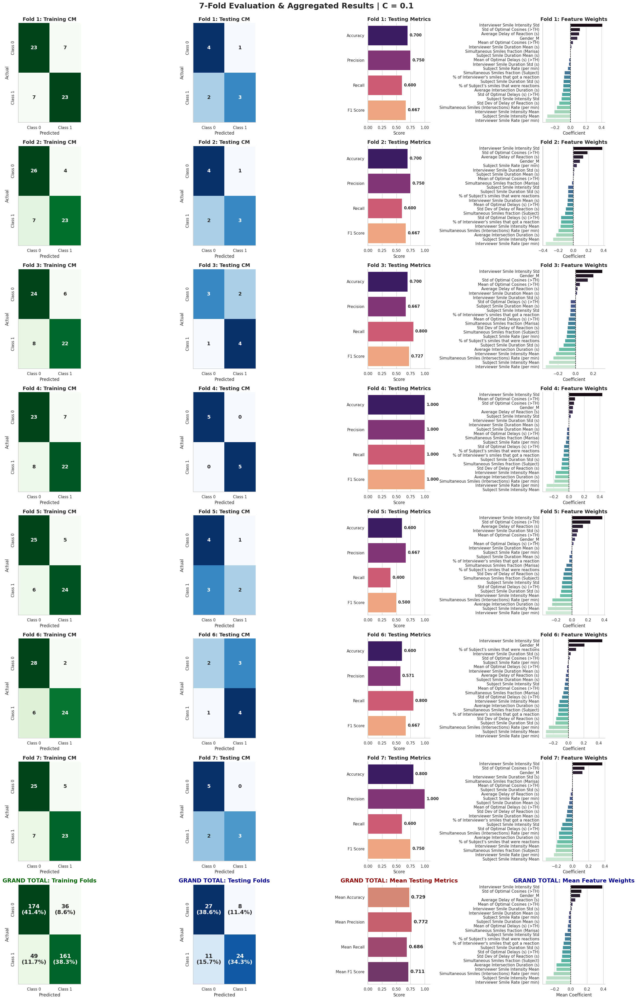

In [8]:
# Example usage:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH):
        # Using your newly updated prepare_data that normalizes and returns X, y directly
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        
        # Run the detailed 7-Fold Analysis
        evaluate_kfold_detailed(
            X=X_scaled, 
            y=y, 
            K_FOLDS=7, 
            use_l1=False, 
            C_value=1/10
        )

Preparing data...
Preparation complete: 70 subjects processed.
Starting 7-Fold Detailed Analysis (Penalty: L1 (Sparse), C=0.1)...
----------------------------------------------------------------------


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

Completed 7 Folds. Rendering Aggregate Matrix...


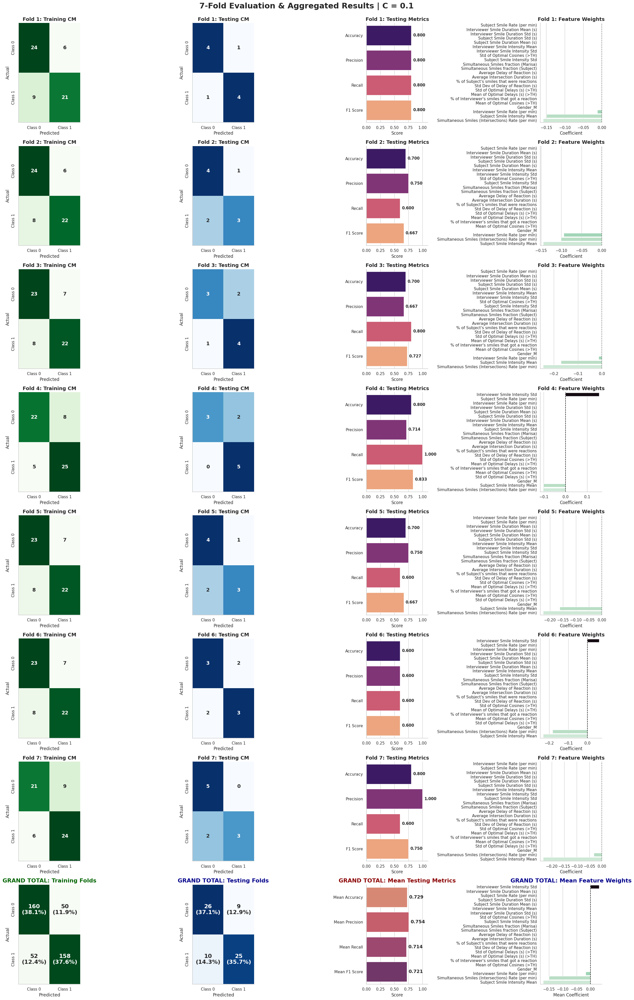

In [9]:
# Example usage:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH):
        # Using your newly updated prepare_data that normalizes and returns X, y directly
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        
        # Run the detailed 7-Fold Analysis
        evaluate_kfold_detailed(
            X=X_scaled, 
            y=y, 
            K_FOLDS=7, 
            use_l1=True, 
            C_value=1/10
        )

# Method1

In [10]:
def execute_pruning_for_fold(X_tr, X_te, y_tr, y_te, fold_idx, model_params, phase_name):
    """
    Helper function to recursively prune features for a single data fold.
    Tracks the 'Survival Score' (elimination order) for every feature.
    Generates a 1x4 subplot for every step until 1 feature remains.
    Returns a dictionary of {Feature_Name: Survival_Score}.
    """
    current_X_tr = X_tr.copy()
    current_X_te = X_te.copy()
    
    log_reg = LogisticRegression(**model_params)
    
    # --- NEW: Track survival scores ---
    survival_scores = {}
    current_rank = 1 
    
    print(f"\n{'='*60}")
    print(f"[{phase_name}] STARTING FOLD {fold_idx} PRUNING")
    print(f"{'='*60}")
    
    while current_X_tr.shape[1] > 0:
        num_feats = current_X_tr.shape[1]
        
        # 1. Train Model & Predict
        log_reg.fit(current_X_tr, y_tr)
        y_tr_pred = log_reg.predict(current_X_tr)
        y_te_pred = log_reg.predict(current_X_te)
        
        # 2. Calculate Matrices & Metrics
        train_cm = confusion_matrix(y_tr, y_tr_pred, labels=[0, 1])
        test_cm = confusion_matrix(y_te, y_te_pred, labels=[0, 1])
        
        acc = accuracy_score(y_te, y_te_pred)
        prec = precision_score(y_te, y_te_pred, zero_division=0)
        rec = recall_score(y_te, y_te_pred, zero_division=0)
        f1 = f1_score(y_te, y_te_pred, zero_division=0)
        
        test_metrics = pd.DataFrame({
            "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
            "Score": [acc, prec, rec, f1]
        })
        
        # 3. Extract Coefficients and identify the weakest link
        coefs = log_reg.coef_[0]
        abs_coefs = np.abs(coefs)
        min_idx = np.argmin(abs_coefs)
        feature_to_drop = current_X_tr.columns[min_idx]
        
        # --- NEW: Assign the survival score (rank) and increment ---
        survival_scores[feature_to_drop] = current_rank
        current_rank += 1
        
        # Determine plot titles and colors
        if num_feats > 1:
            drop_title = f"Dropping: [{feature_to_drop}]"
            custom_palette = {feat: '#e74c3c' if feat == feature_to_drop else '#3498db' for feat in current_X_tr.columns}
        else:
            drop_title = f"SURVIVOR: [{feature_to_drop}]"
            custom_palette = {feature_to_drop: '#2ecc71'} # Green for the final survivor
            
        iter_df = pd.DataFrame({
            'Feature': current_X_tr.columns,
            'Coefficient': coefs,
            'Abs_Coef': abs_coefs
        }).sort_values(by='Abs_Coef', ascending=False)
        
        # ---------------------------------------------------------------------
        # --- PLOT 1x4 GRID ---
        # ---------------------------------------------------------------------
        plot_height = max(4.0, num_feats * 0.4)
        fig, axes = plt.subplots(1, 4, figsize=(24, plot_height))
        fig.suptitle(f'[{phase_name}] Fold {fold_idx} | Features: {num_feats} | {drop_title}', 
                     fontsize=16, fontweight='bold', y=1.05)
        
        # Plot 1: Train CM
        sns.heatmap(train_cm, annot=True, fmt='d', cmap='Greens', ax=axes[0],
                    annot_kws={"size": 14, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[0].set_title('Training CM', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Predicted', fontsize=12)
        axes[0].set_ylabel('Actual', fontsize=12)
        
        # Plot 2: Test CM
        sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
                    annot_kws={"size": 14, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[1].set_title('Testing CM', fontsize=14, fontweight='bold')
        axes[1].set_xlabel('Predicted', fontsize=12)
        axes[1].set_ylabel('Actual', fontsize=12)
        
        # Plot 3: Test Metrics
        sns.barplot(x='Score', y='Metric', data=test_metrics, ax=axes[2], hue='Metric', palette='magma', legend=False)
        axes[2].set_title('Testing Metrics', fontsize=14, fontweight='bold')
        axes[2].set_xlim(0, 1.1)
        axes[2].set_ylabel('')
        for i in axes[2].containers:
            axes[2].bar_label(i, fmt='%.3f', padding=5, size=11, weight='bold')
            
        # Plot 4: Feature Weights
        sns.barplot(x='Coefficient', y='Feature', data=iter_df, ax=axes[3], hue='Feature', palette=custom_palette, legend=False)
        axes[3].set_title('Feature Weights (Red = Weakest)', fontsize=14, fontweight='bold')
        axes[3].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
        axes[3].set_ylabel('')
        
        sns.despine()
        plt.tight_layout()
        plt.show()
        plt.close(fig) # Prevent RAM overload
        
        # 4. Check if it's the last feature
        if num_feats == 1:
            return survival_scores # Return the full dictionary of scores, not just the single survivor
            
        # 5. Drop the feature for the next round
        current_X_tr = current_X_tr.drop(columns=[feature_to_drop])
        current_X_te = current_X_te.drop(columns=[feature_to_drop])


def evaluate_nested_pruning(X, y, K_FOLDS=7, use_l1=False, C_value=1.0, max_iter=10000):
    """
    Runs K-Fold Recursive Pruning on the full dataset, calculates Mean Survival Scores,
    and runs a final K-Fold Pruning on the subset of top survivors.
    """
    sns.set_theme(style="whitegrid", palette="muted")
    
    if C_value == 0 or C_value is None:
        model_params = {'penalty': None, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}
    else:
        model_params = {'penalty': 'elasticnet', 'l1_ratio': 1.0 if use_l1 else 0.0, 'C': C_value, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}

    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # =========================================================================
    # PHASE 1: Pruning per Fold (Full Features)
    # =========================================================================
    phase1_all_scores = {}
    phase1_top_survivors = {} # Tracks the absolute #1 feature per fold for Phase 3
    
    for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
        X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
        y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
        
        # Run pruning loop and get the dictionary of survival scores
        scores = execute_pruning_for_fold(X_tr, X_te, y_tr, y_te, fold, model_params, "PHASE 1 (ALL FEATURES)")
        phase1_all_scores[f"Fold {fold}"] = scores
        
        # Identify the ultimate survivor (the feature with the maximum score)
        top_feature = max(scores, key=scores.get)
        phase1_top_survivors[f"Fold {fold}"] = top_feature

    # =========================================================================
    # PHASE 2: Survival Score Analysis Dashboard
    # =========================================================================
    # Convert all scores into a clean DataFrame
    scores_df = pd.DataFrame(phase1_all_scores)
    
    # Calculate the new metric: Average Survival Score
    scores_df['Mean_Survival_Score'] = scores_df.mean(axis=1)
    scores_df = scores_df.sort_values(by='Mean_Survival_Score', ascending=False)
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    fig.suptitle('PHASE 2: Feature Survival Score Analysis', fontsize=20, fontweight='bold', y=1.02)
    
    # Plot A: The Heatmap (Shows exact rank in every fold)
    sns.heatmap(scores_df.drop(columns=['Mean_Survival_Score']), annot=True, fmt=".0f", cmap='viridis', 
                ax=axes[0], linewidths=0.5, cbar_kws={'label': 'Survival Rank (Higher is Better)'})
    axes[0].set_title('Survival Rank per Fold', fontsize=16, fontweight='bold')
    axes[0].set_ylabel('Features', fontsize=14)
    axes[0].set_xlabel('K-Folds', fontsize=14)
    
    # Plot B: The Leaderboard (Mean Score)
    sns.barplot(x='Mean_Survival_Score', y=scores_df.index, data=scores_df, palette='magma', ax=axes[1])
    axes[1].set_title('Overall Leaderboard: Mean Survival Score', fontsize=16, fontweight='bold')
    axes[1].set_xlabel('Average Rank Across All Folds', fontsize=14)
    axes[1].set_ylabel('')
    
    # Add values to the bars
    for i in axes[1].containers:
        axes[1].bar_label(i, fmt='%.2f', padding=5, size=11, weight='bold')

    sns.despine()
    plt.tight_layout()
    plt.show()
    
    # =========================================================================
    # PHASE 3: Pruning the Top Survivors
    # =========================================================================
    # Take only the features that placed #1 in at least one fold
    unique_survivors = list(set(phase1_top_survivors.values()))
    
    print(f"\n{'#'*60}")
    print(f"PHASE 3: FINAL SHOWDOWN")
    print(f"Features that survived to the end of at least 1 fold: {unique_survivors}")
    print(f"Applying pruning process exclusively on these {len(unique_survivors)} features...")
    print(f"{'#'*60}\n")
    
    if len(unique_survivors) == 1:
        print("Only 1 feature survived across all folds! No further pruning needed.")
        print(f"ULTIMATE SURVIVOR: {unique_survivors[0]}")
        return
        
    # Isolate the dataset to ONLY the absolute winning features
    X_subset = X[unique_survivors]
    phase3_all_scores = {}
    
    for fold, (train_index, test_index) in enumerate(skf.split(X_subset, y), start=1):
        X_tr_sub, X_te_sub = X_subset.iloc[train_index], X_subset.iloc[test_index]
        y_tr_sub, y_te_sub = y.iloc[train_index], y.iloc[test_index]
        
        scores = execute_pruning_for_fold(X_tr_sub, X_te_sub, y_tr_sub, y_te_sub, fold, model_params, "PHASE 3 (SUBSET)")
        phase3_all_scores[f"Fold {fold}"] = scores
        
    # --- PHASE 3 FINAL RESULTS PLOT ---
    phase3_scores_df = pd.DataFrame(phase3_all_scores)
    phase3_scores_df['Mean_Survival_Score'] = phase3_scores_df.mean(axis=1)
    phase3_scores_df = phase3_scores_df.sort_values(by='Mean_Survival_Score', ascending=False)

    plt.figure(figsize=(10, max(4, len(unique_survivors) * 0.8)))
    sns.barplot(x='Mean_Survival_Score', y=phase3_scores_df.index, data=phase3_scores_df, palette='viridis')
    plt.title('PHASE 3 RESULTS: Ultimate Feature Resiliency', fontsize=16, fontweight='bold')
    plt.xlabel('Mean Survival Score (Subset)', fontsize=14)
    plt.ylabel('Elite Features', fontsize=14)
    
    for i in plt.gca().containers:
        plt.gca().bar_label(i, fmt='%.2f', padding=5, size=12, weight='bold')
        
    sns.despine()
    plt.tight_layout()
    plt.show()

Preparing data...
Preparation complete: 70 subjects processed.

[PHASE 1 (ALL FEATURES)] STARTING FOLD 1 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


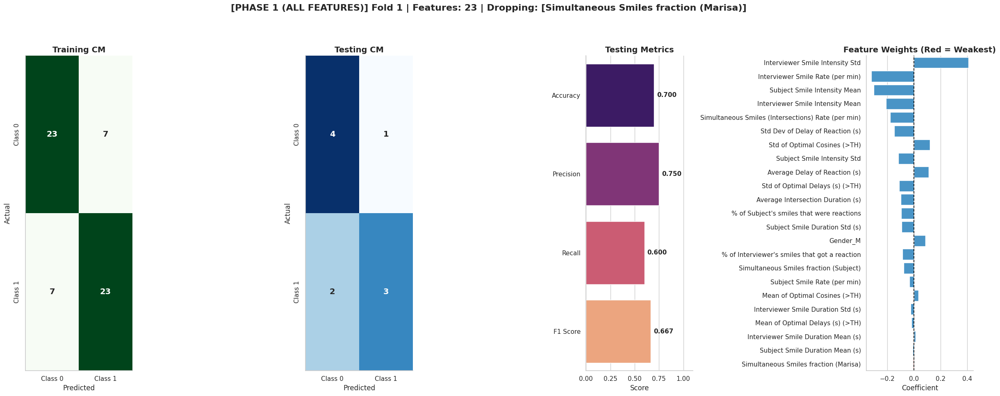

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


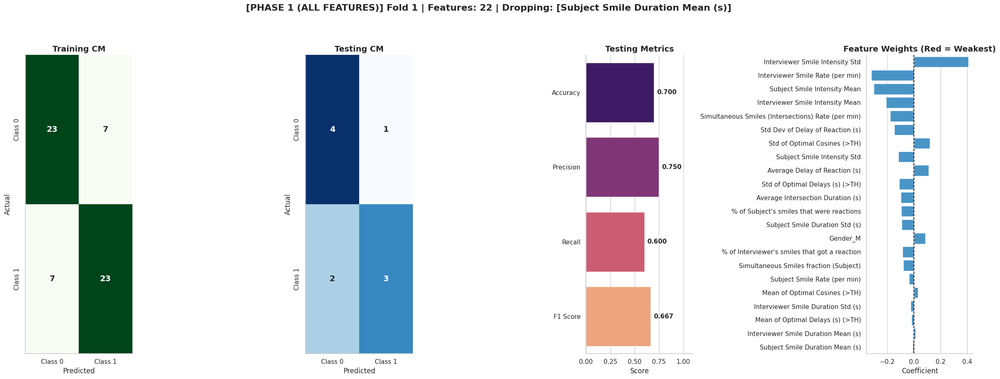

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


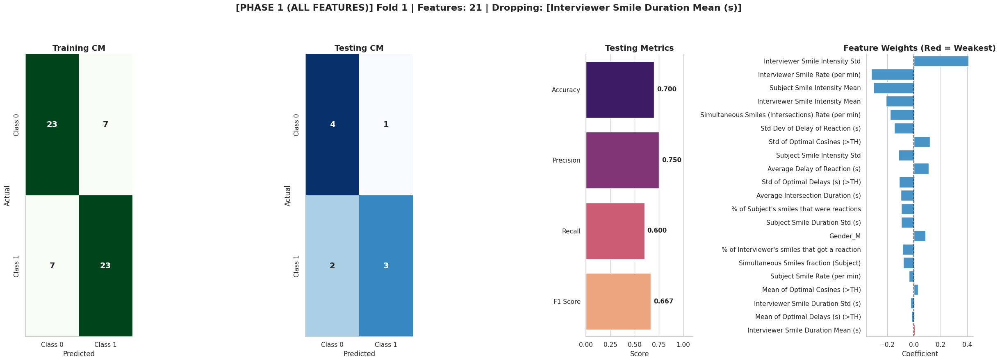

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


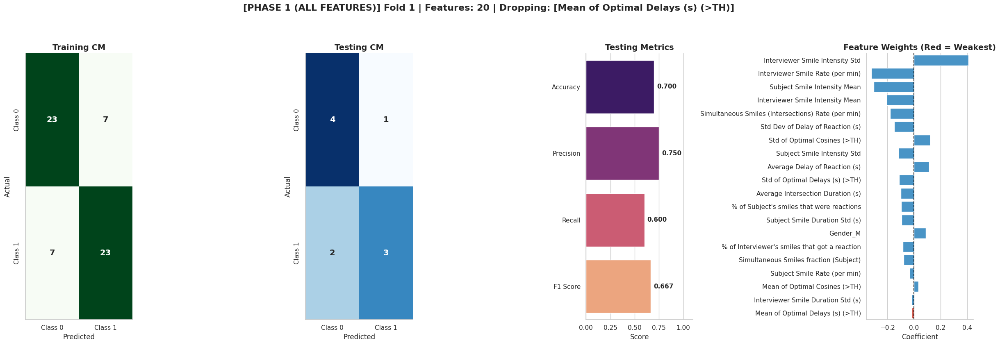

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


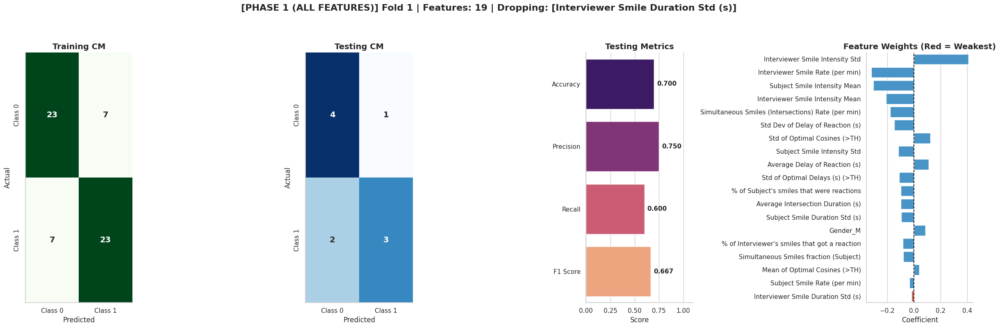

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


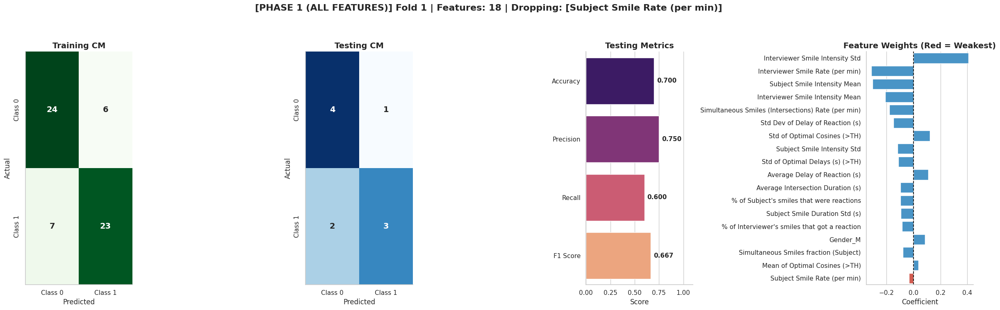

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


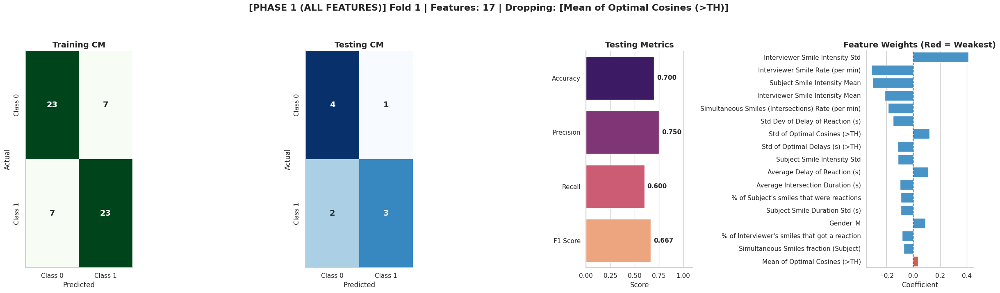

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


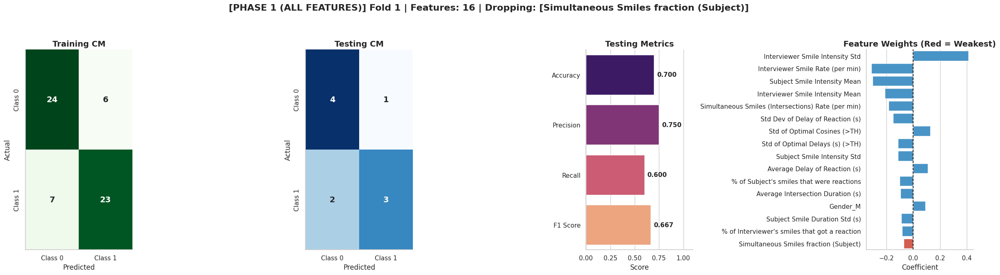

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


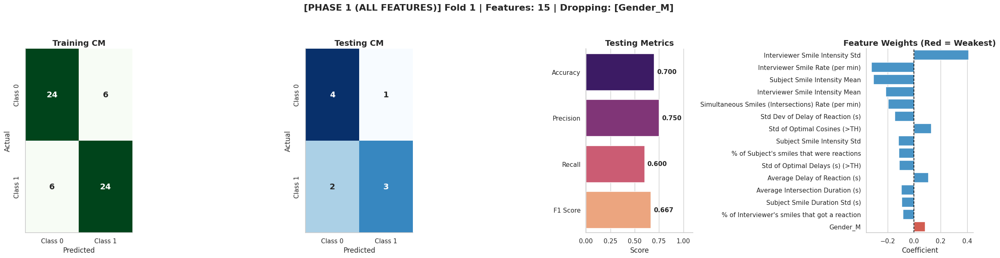

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


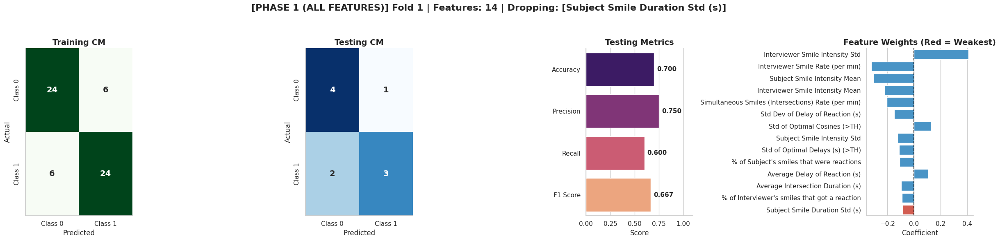

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


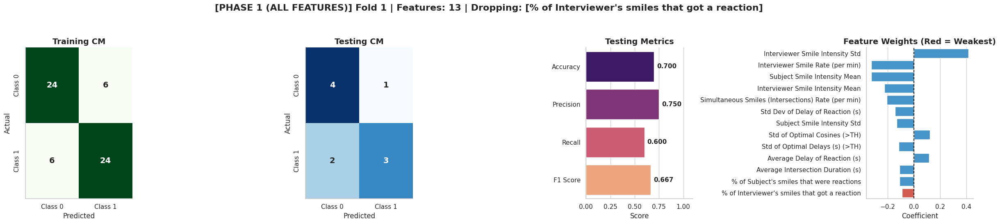

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


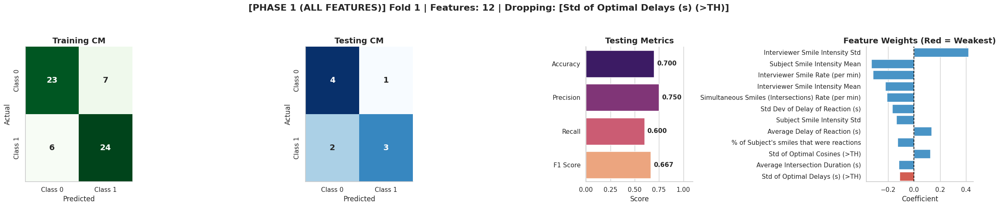

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


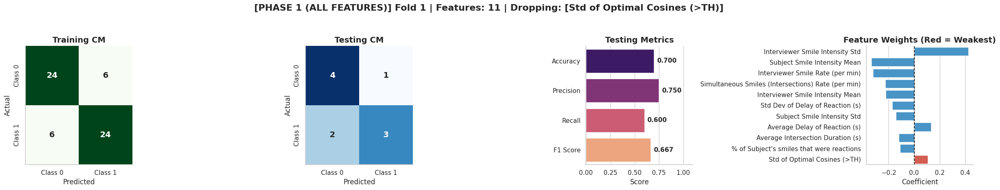

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


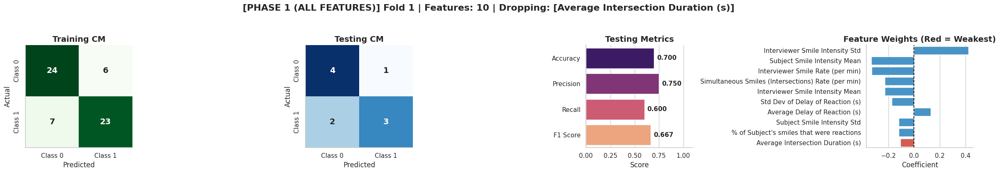

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


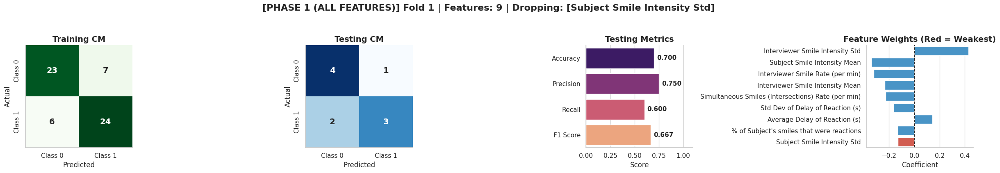

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


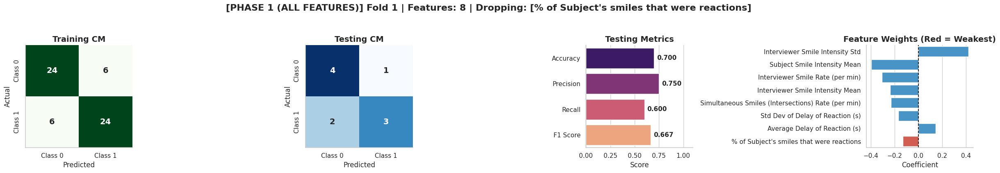

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


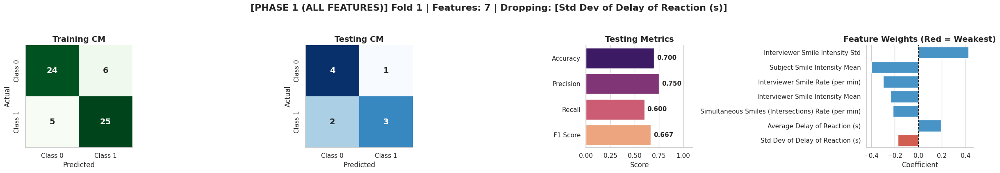

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


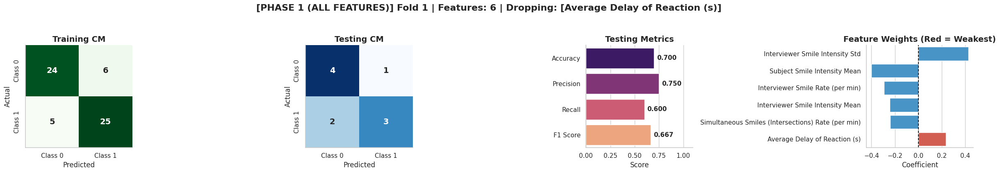

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


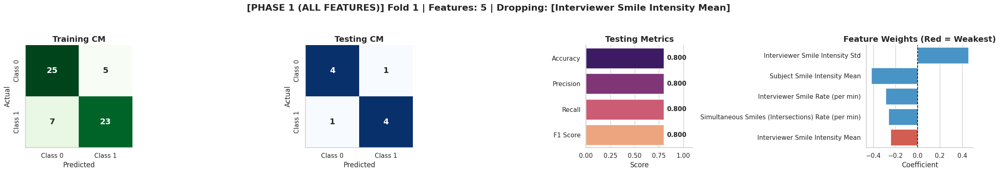

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


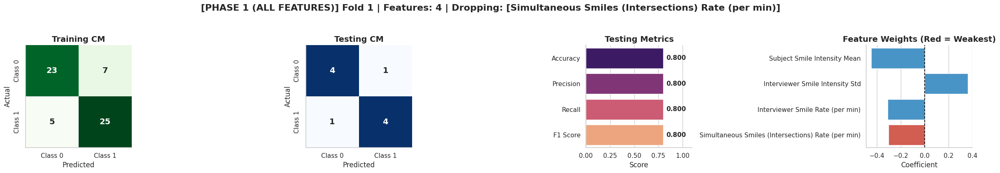

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


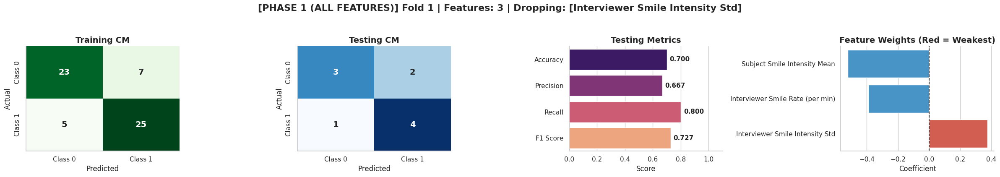

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


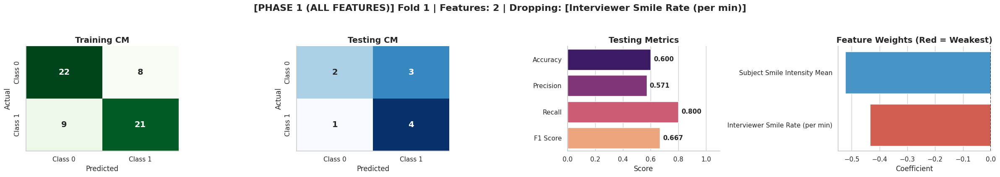

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


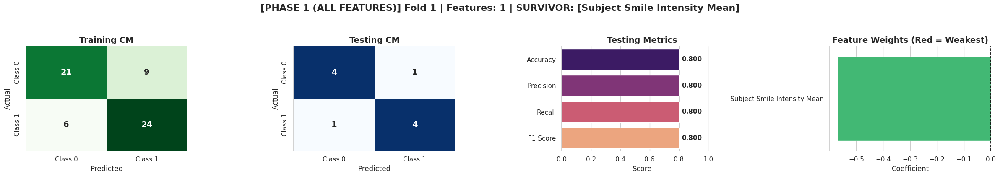


[PHASE 1 (ALL FEATURES)] STARTING FOLD 2 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


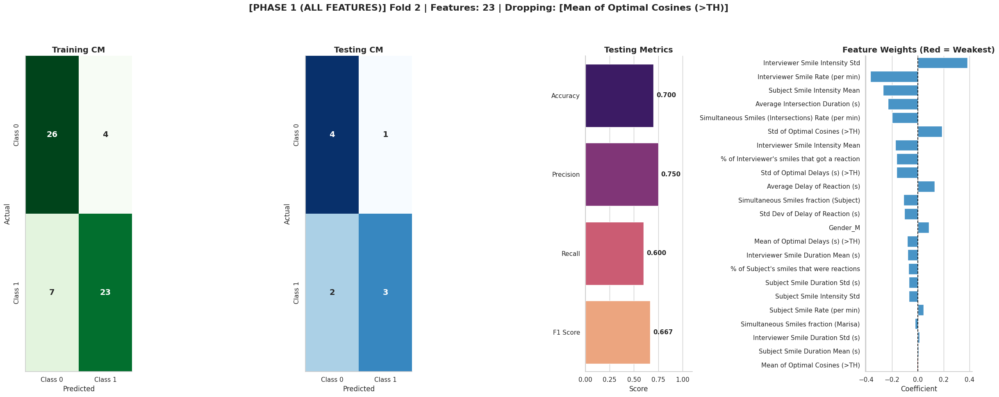

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


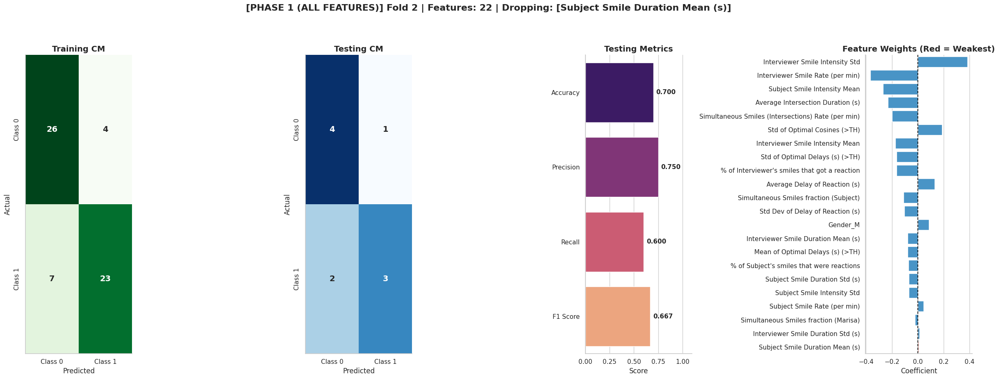

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


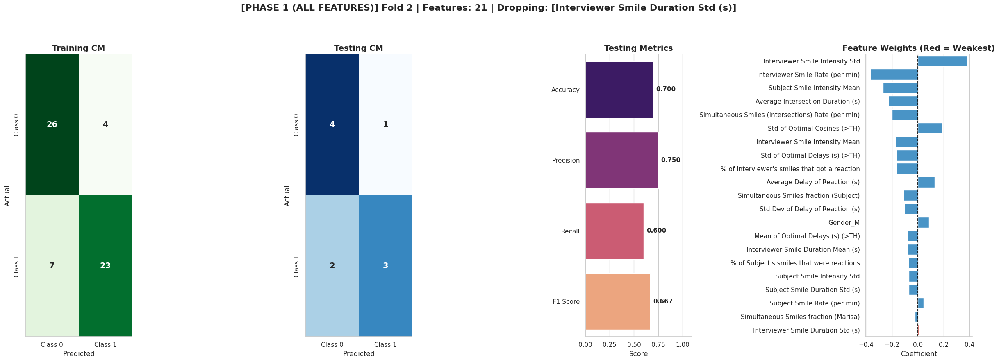

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


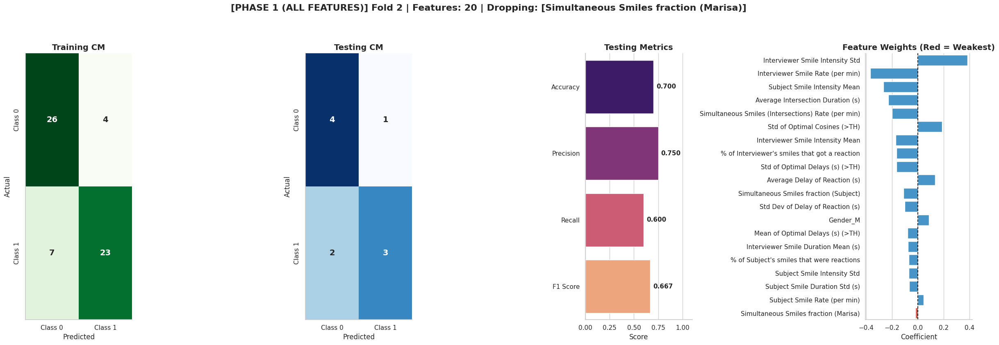

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


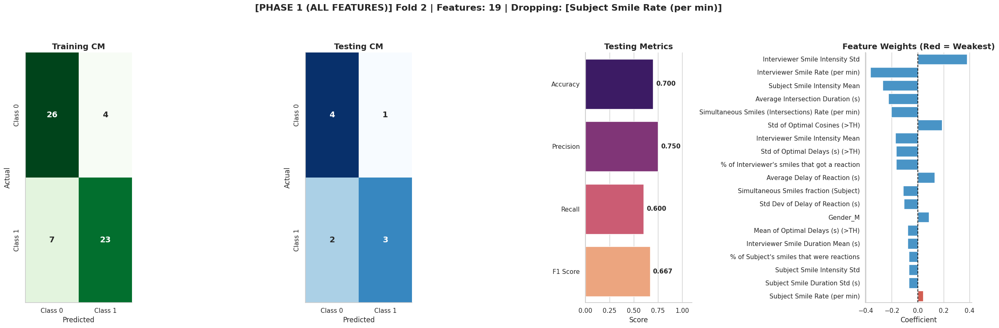

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


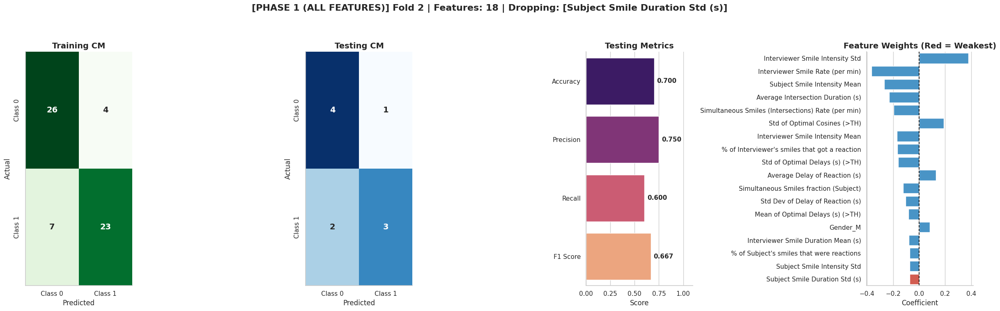

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


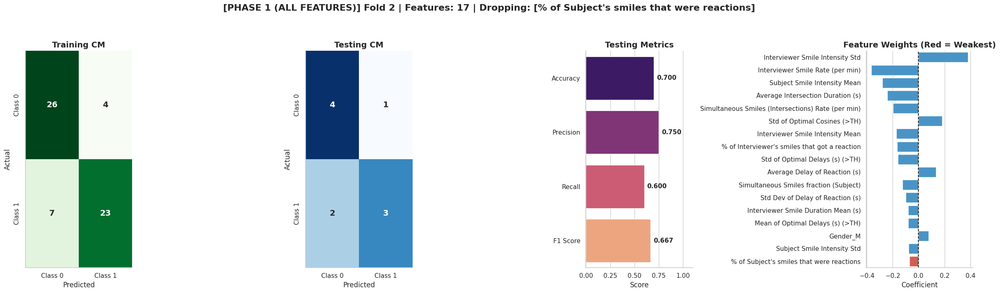

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


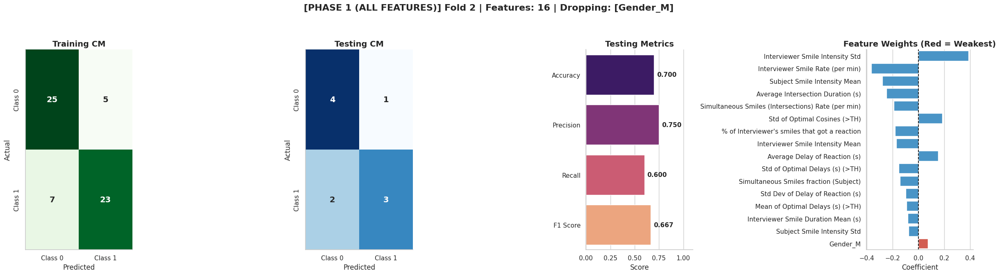

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


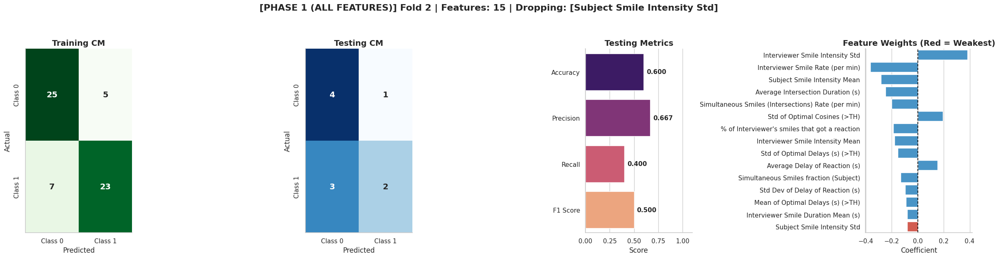

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


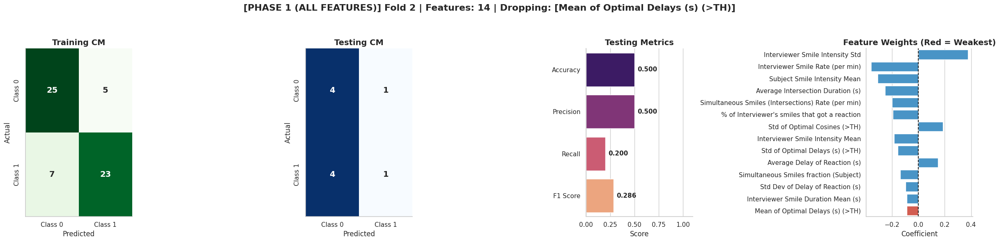

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


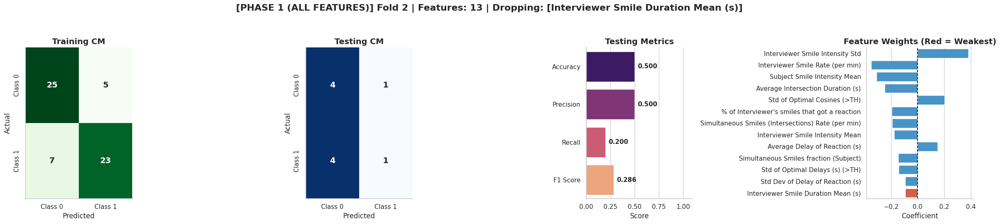

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


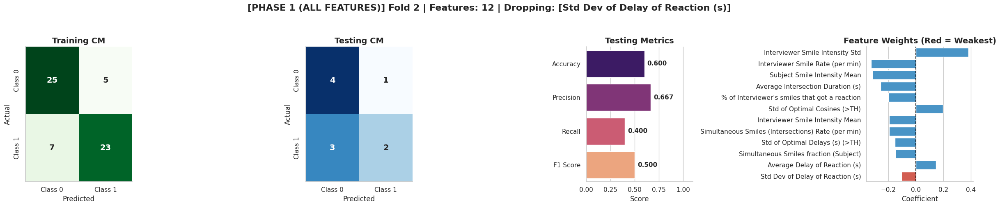

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


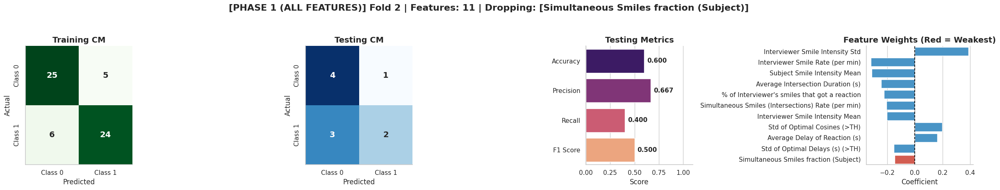

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


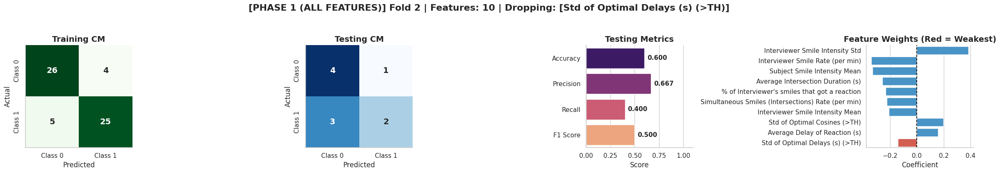

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


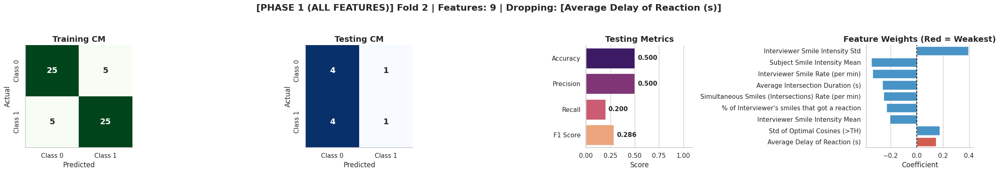

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


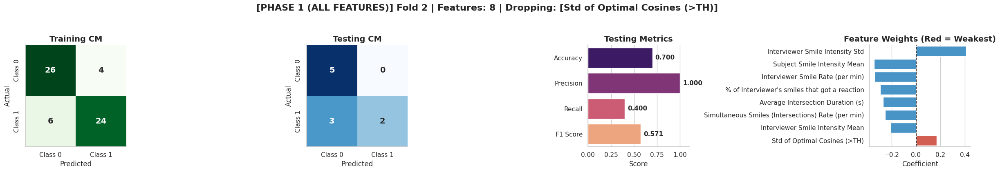

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


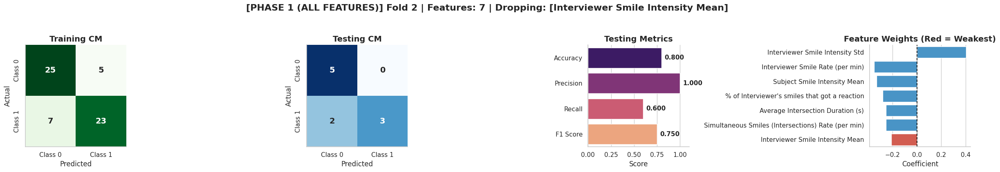

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


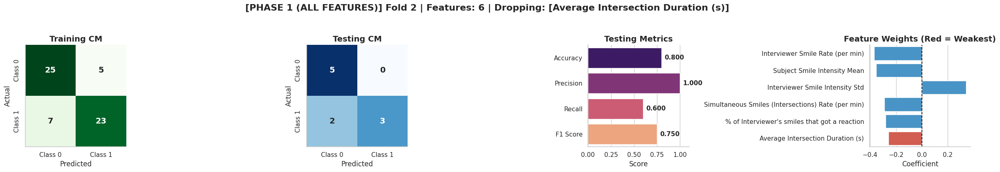

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


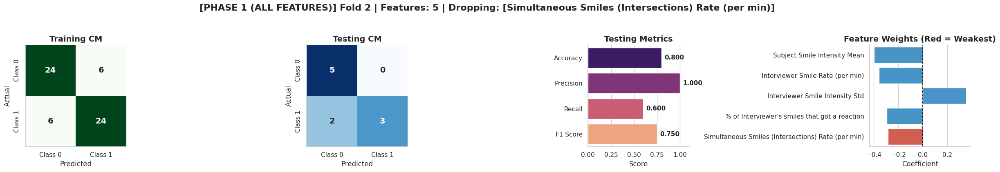

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


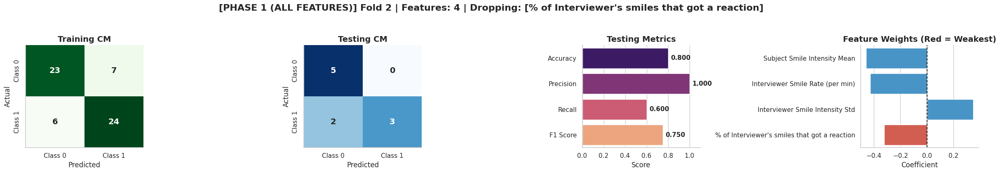

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


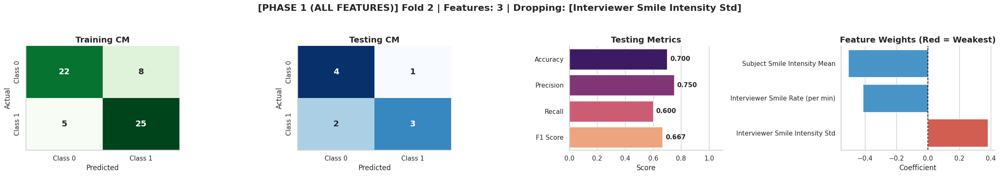

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


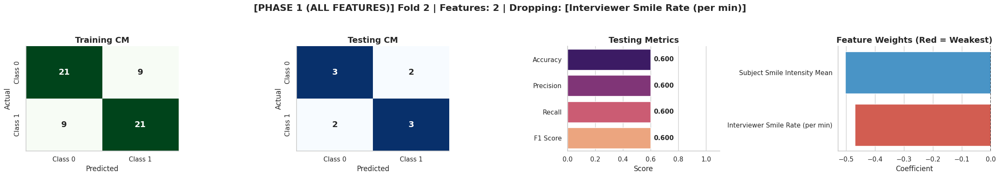

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


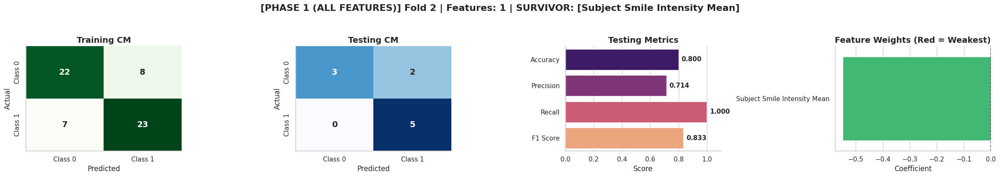


[PHASE 1 (ALL FEATURES)] STARTING FOLD 3 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


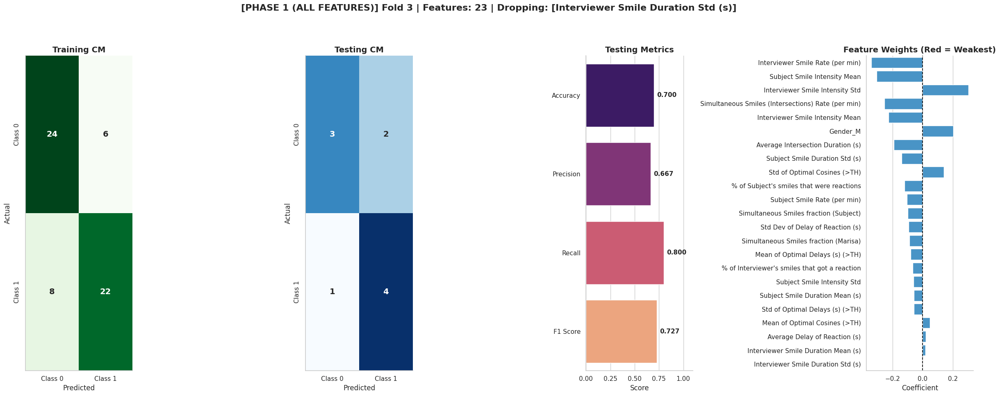

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


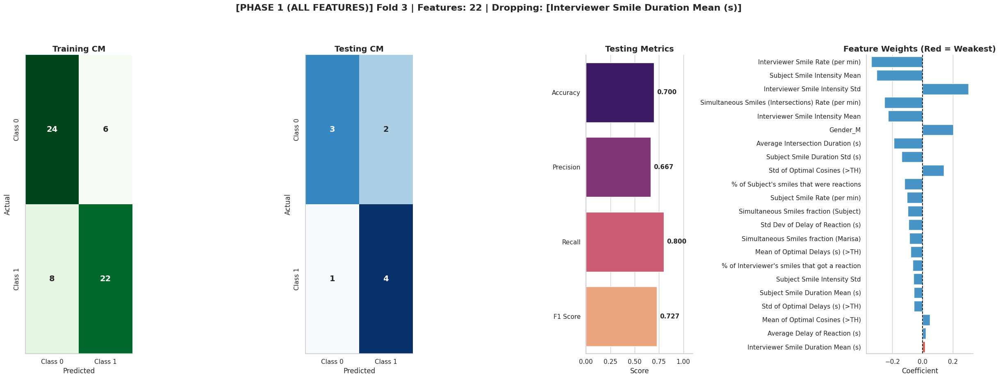

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


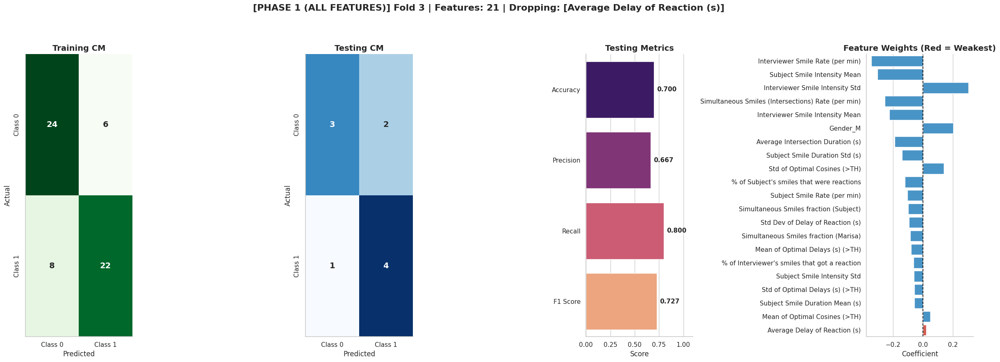

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


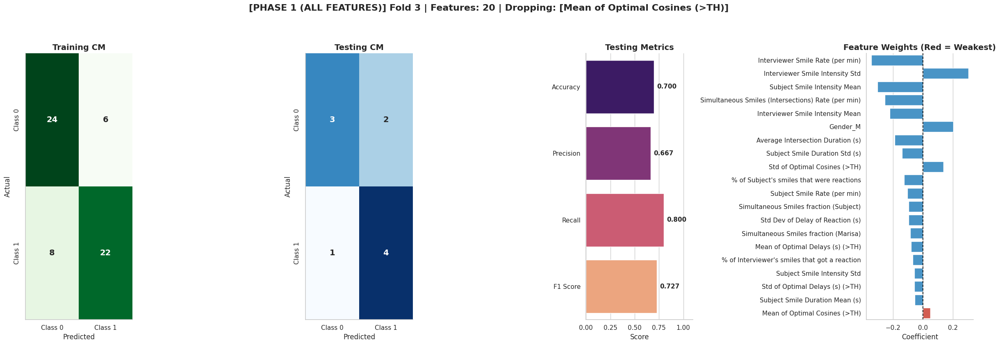

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


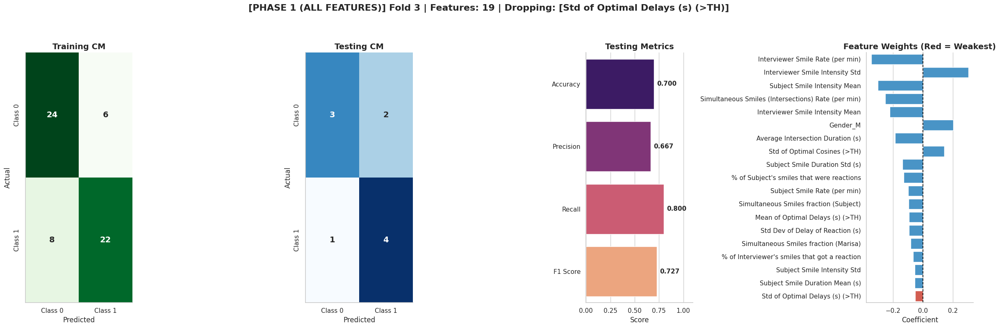

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


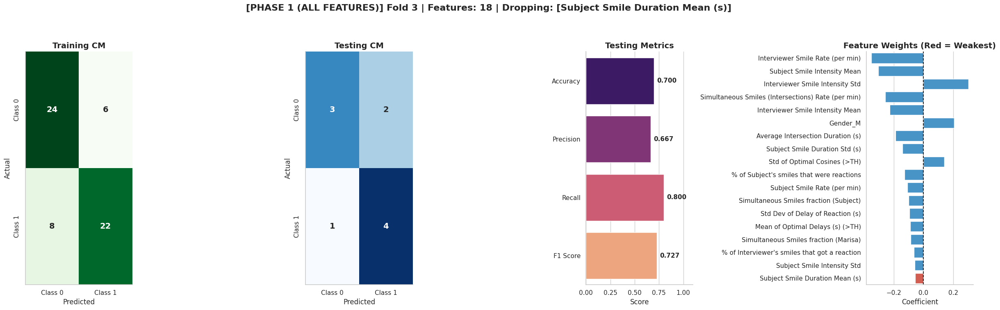

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


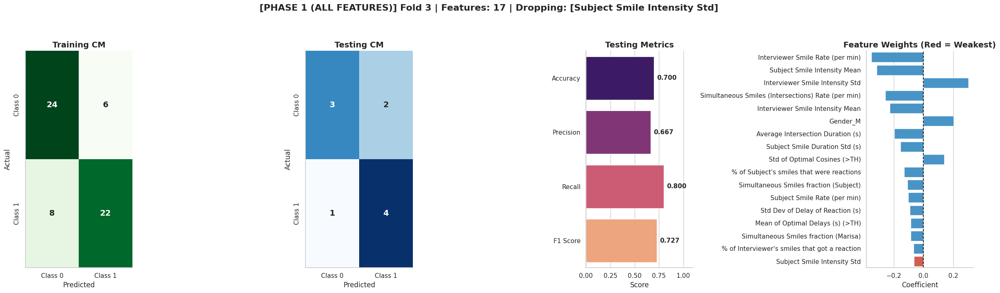

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


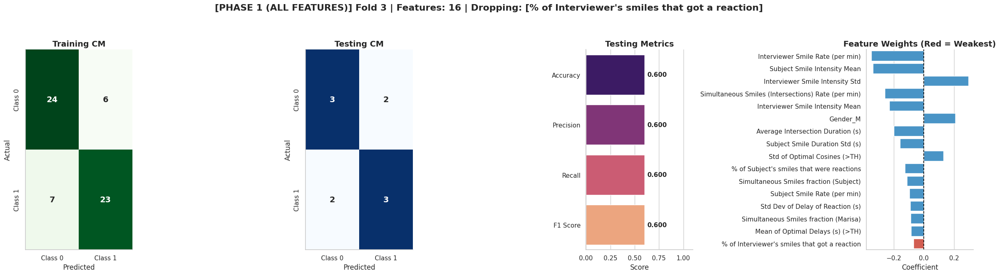

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


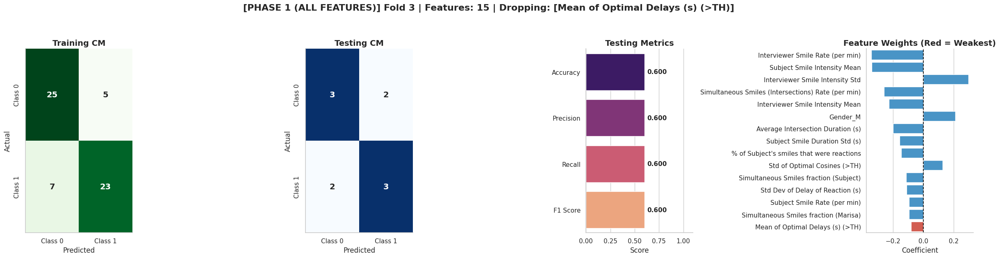

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


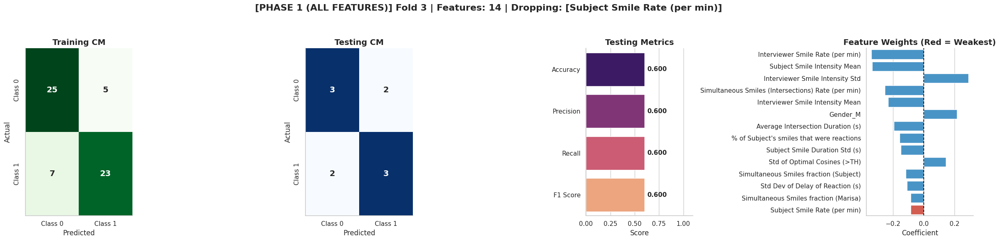

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


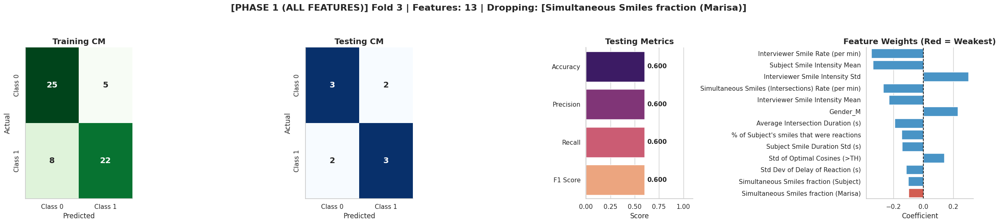

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


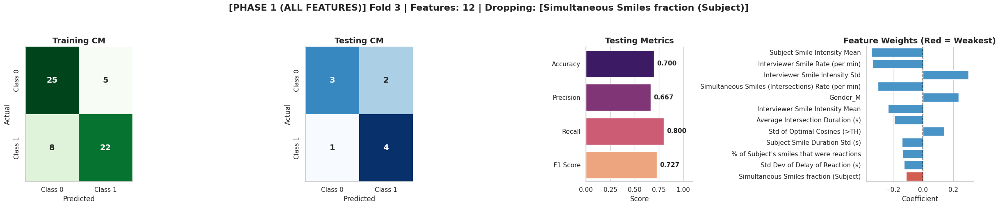

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


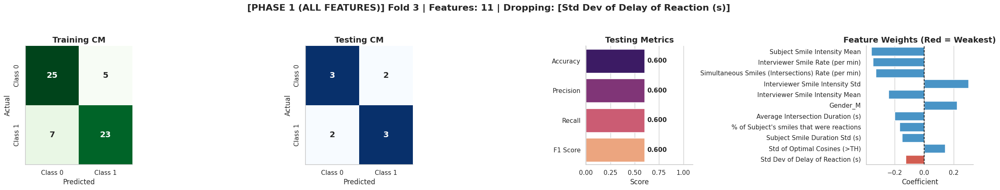

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


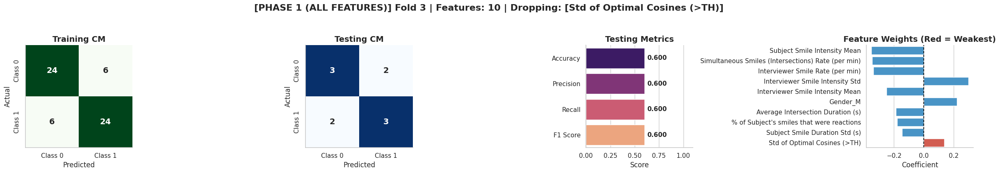

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


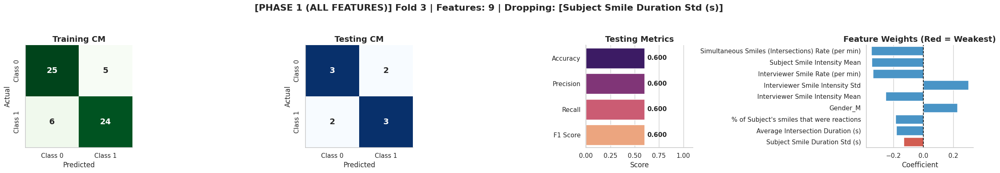

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


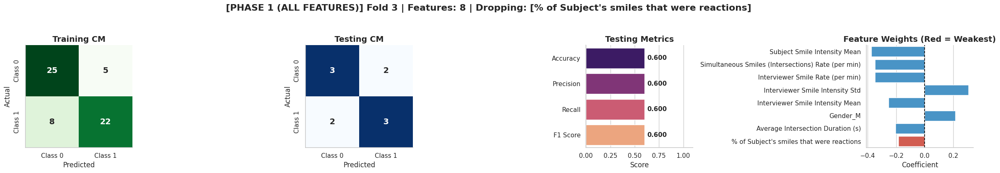

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


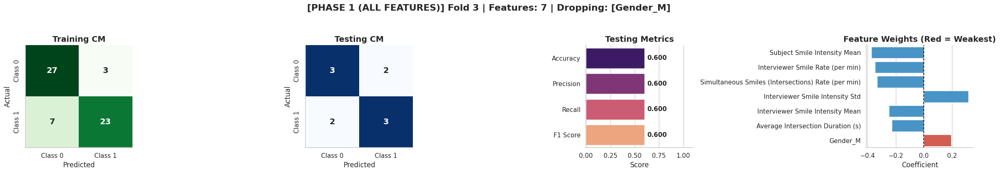

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


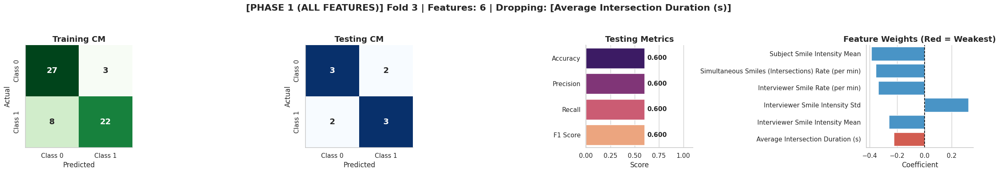

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


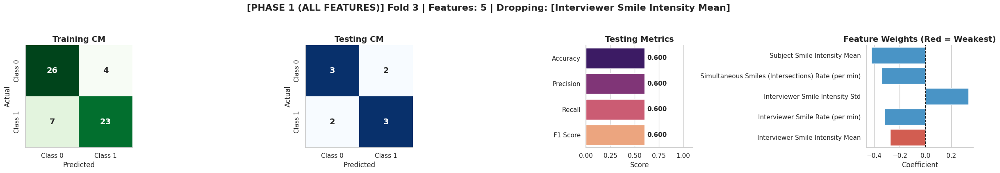

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


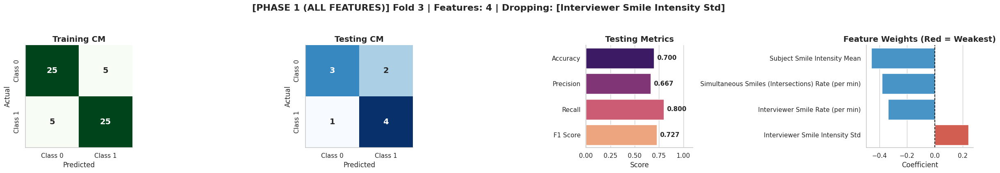

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


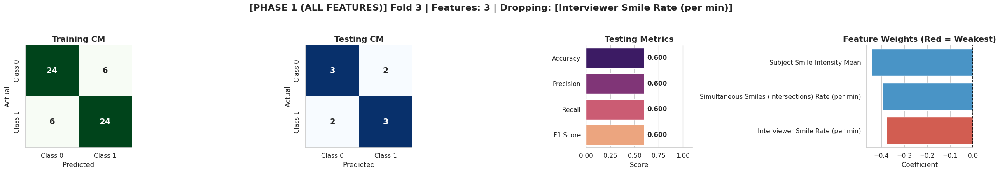

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


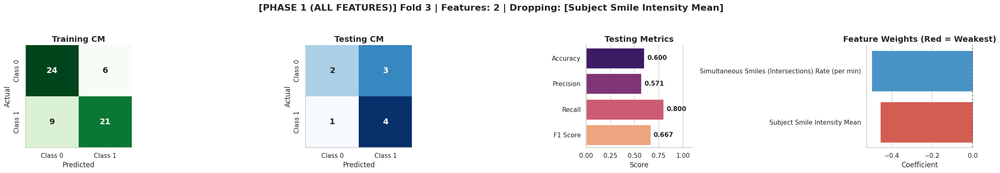

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


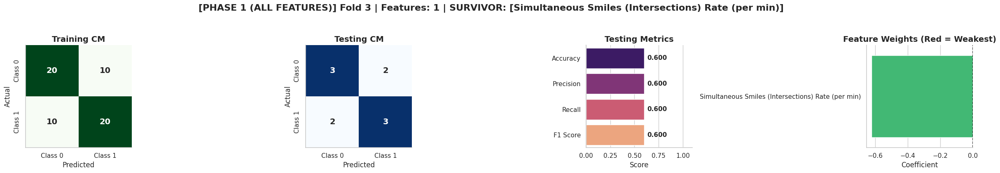


[PHASE 1 (ALL FEATURES)] STARTING FOLD 4 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


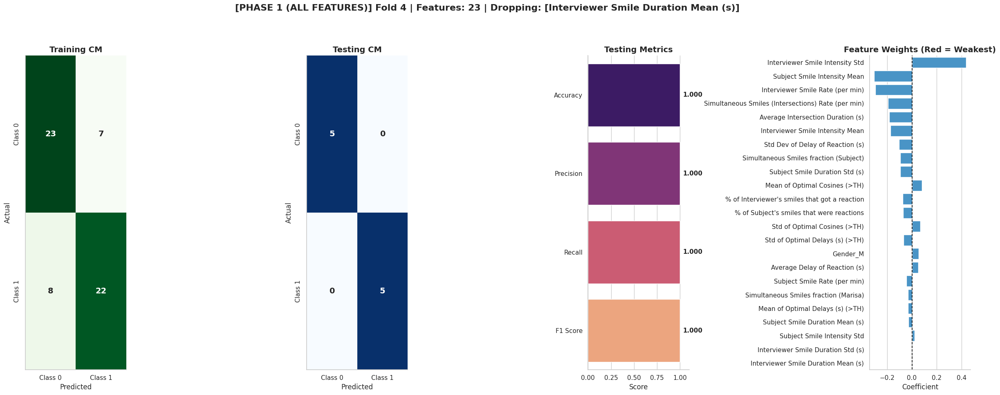

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


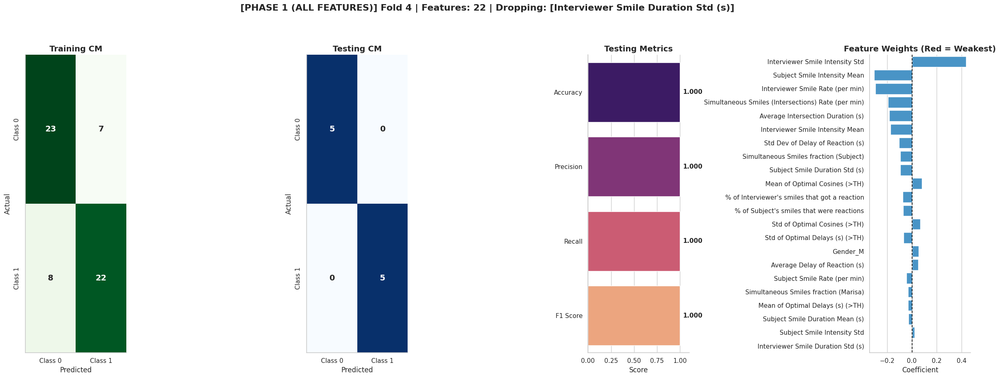

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


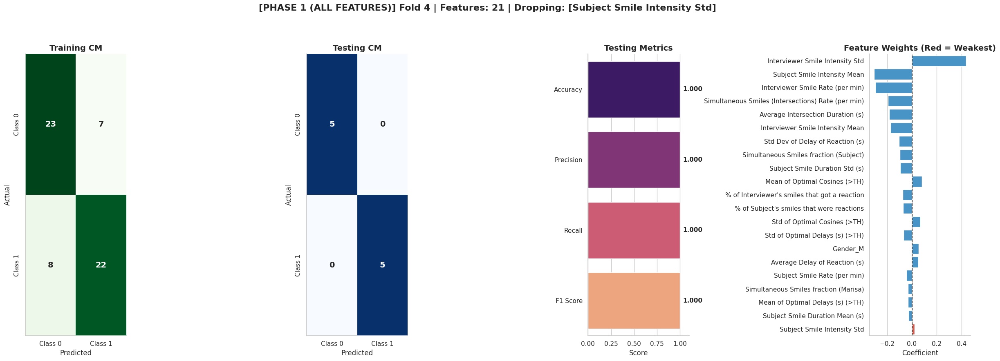

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


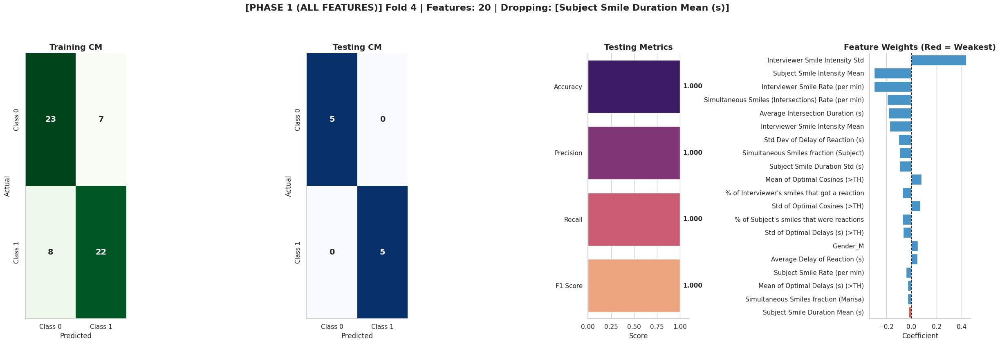

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


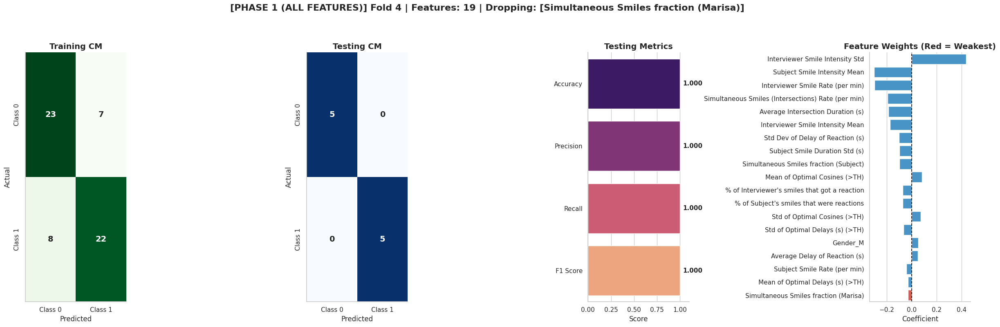

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


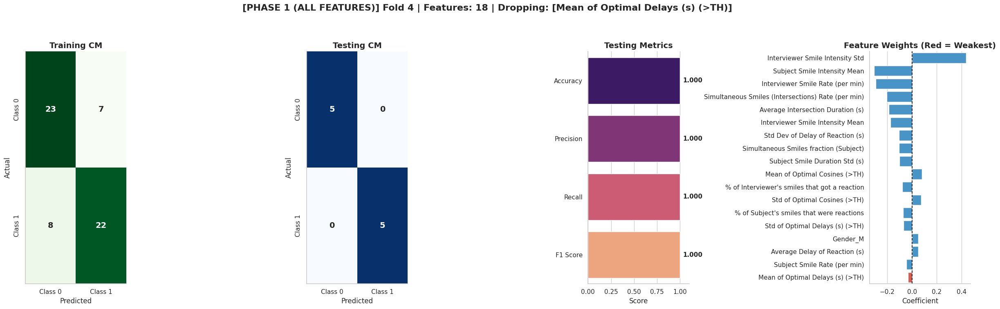

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


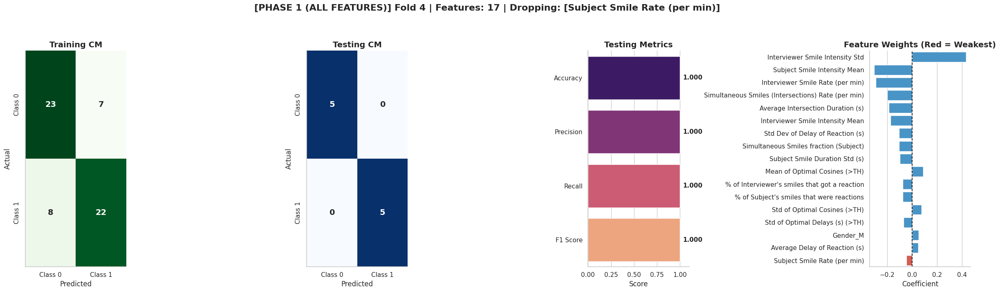

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


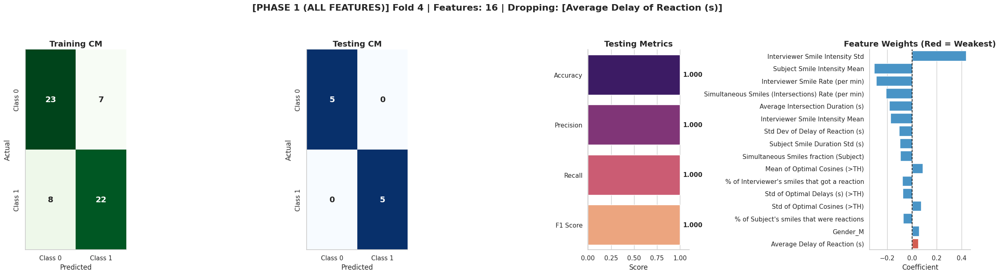

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


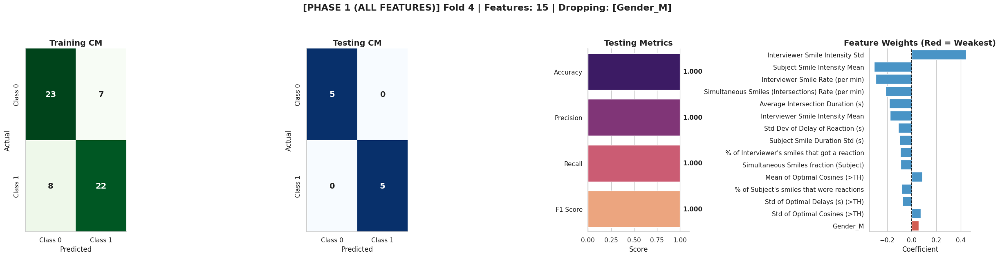

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


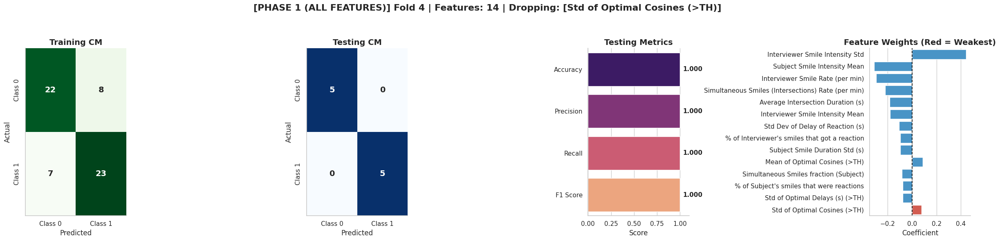

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


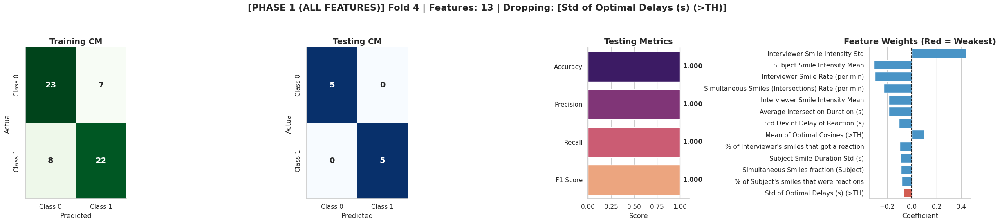

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


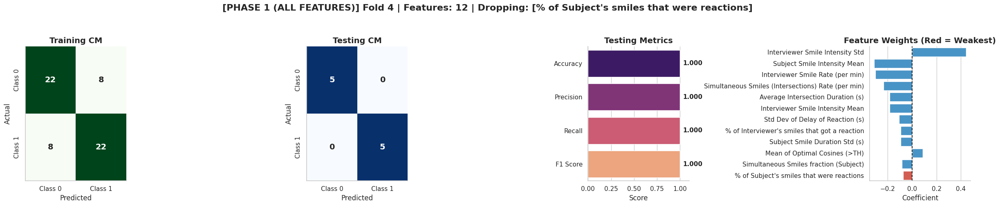

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


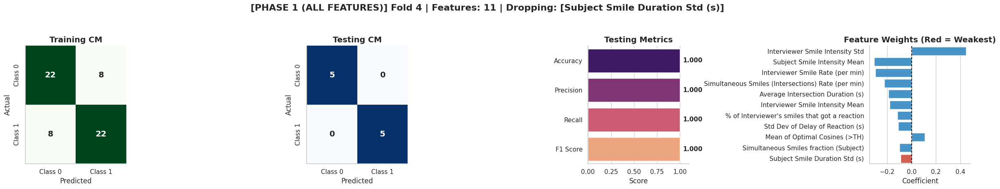

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


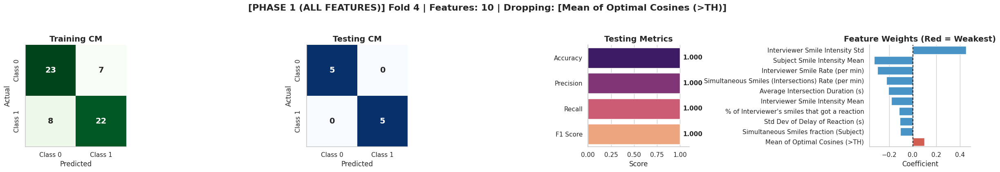

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


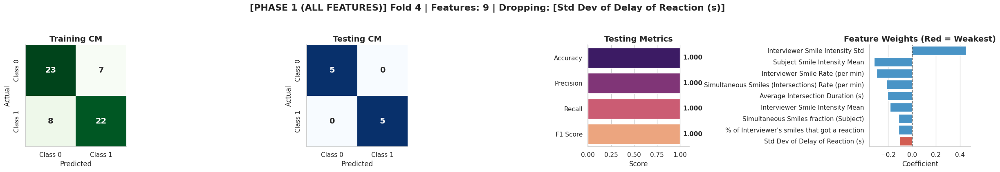

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


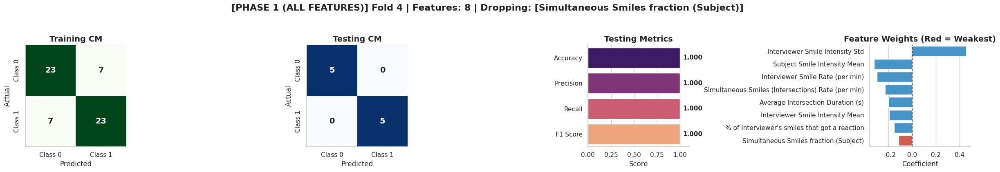

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


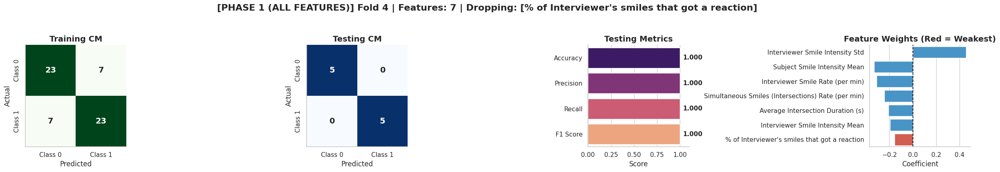

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


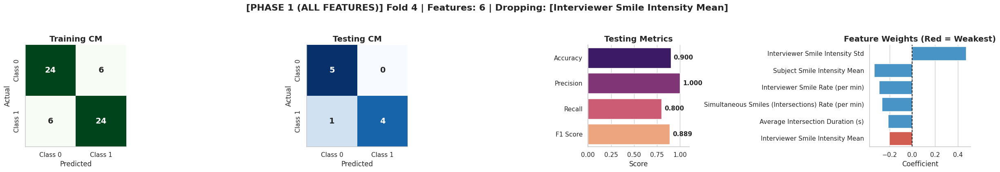

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


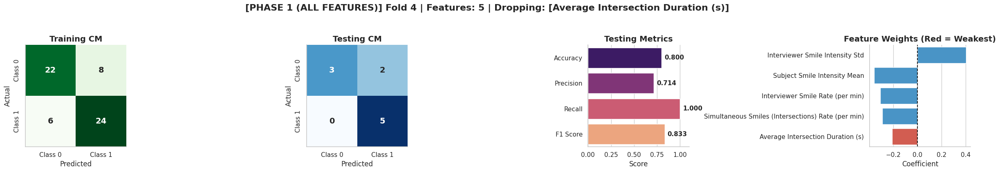

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


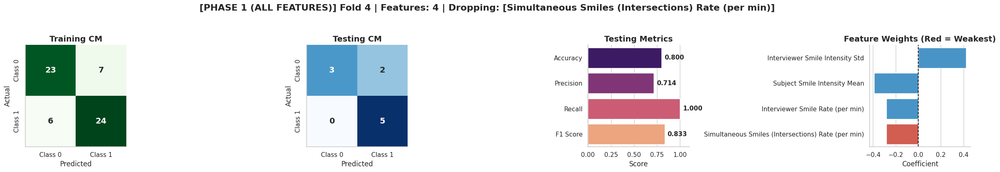

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


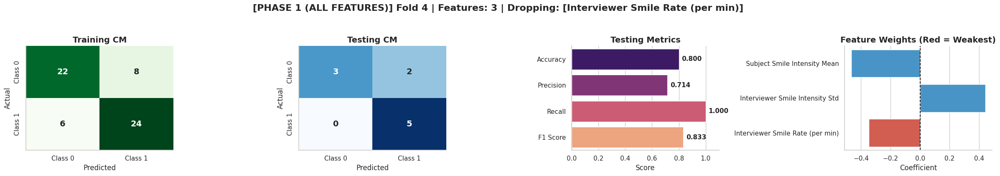

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


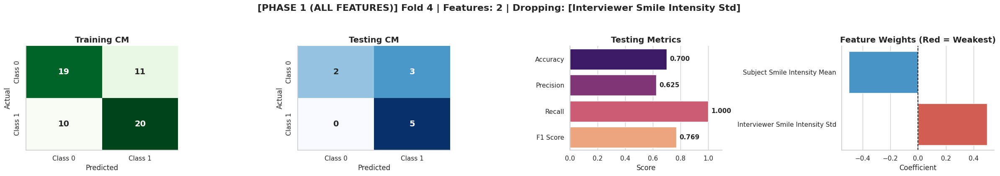

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


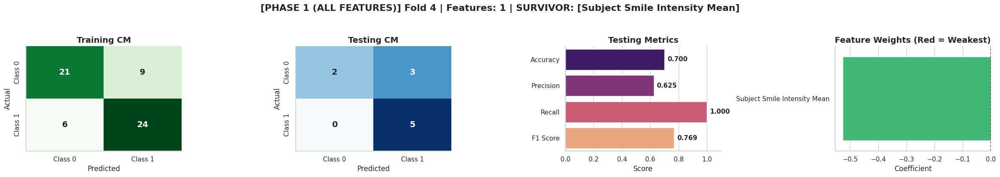


[PHASE 1 (ALL FEATURES)] STARTING FOLD 5 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


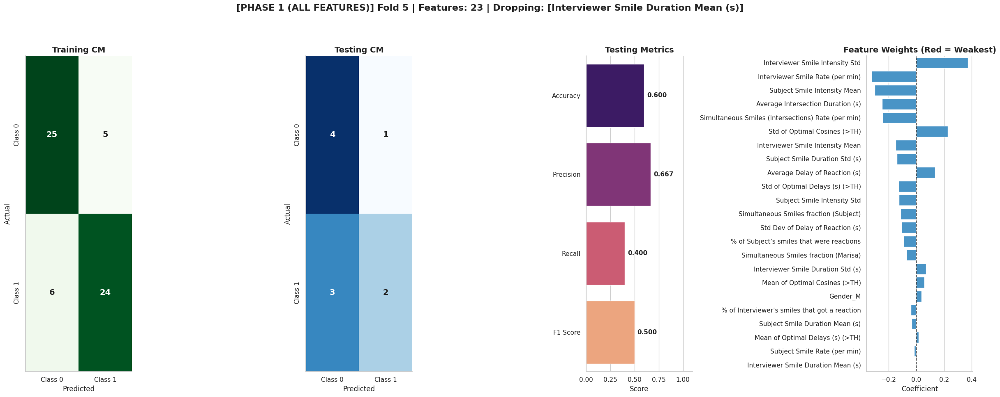

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


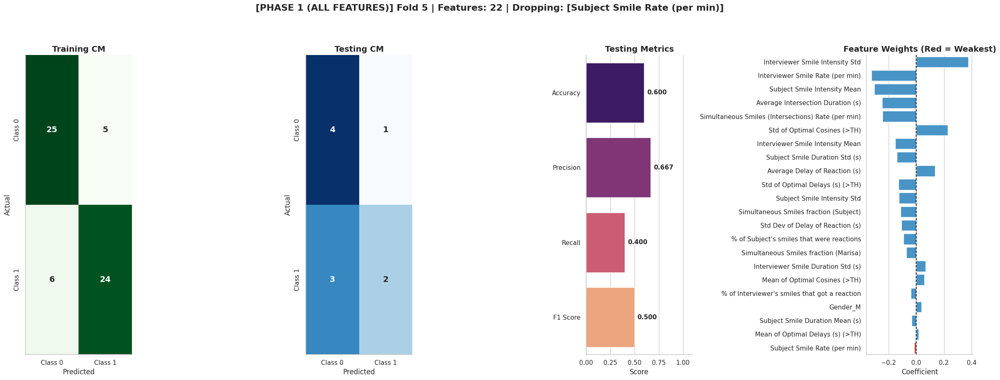

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


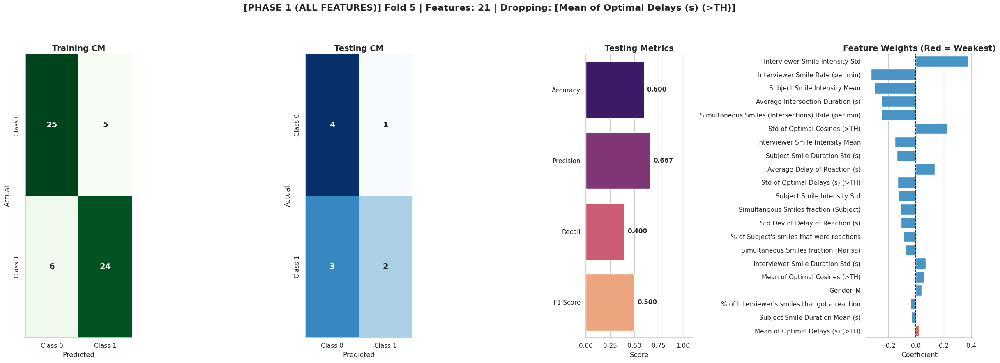

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


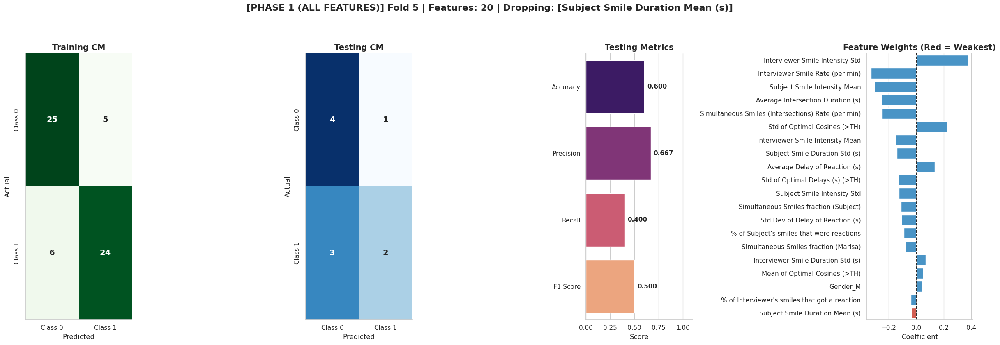

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


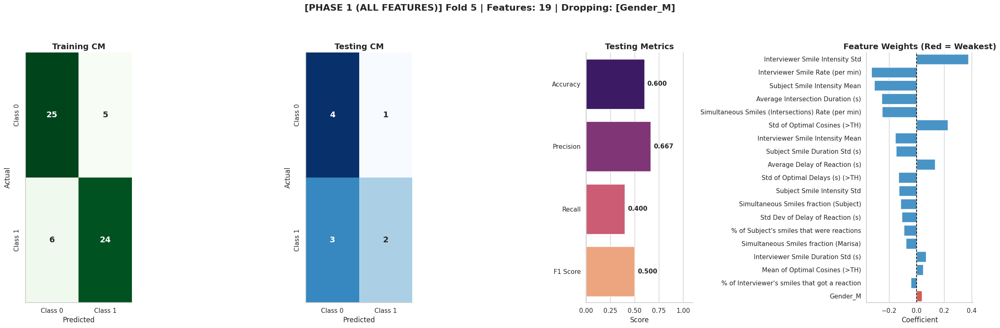

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


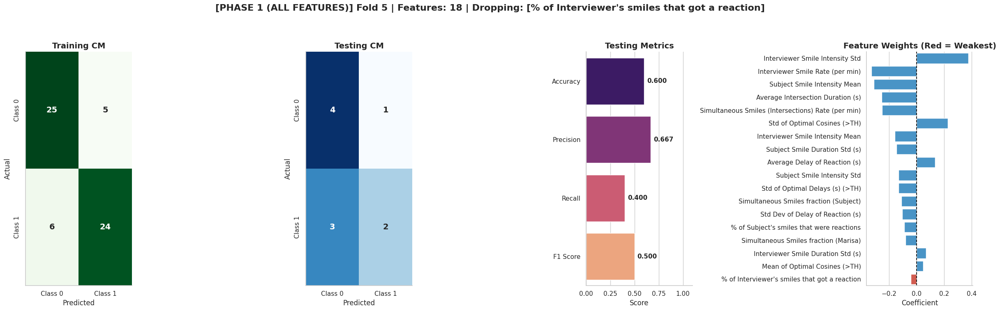

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


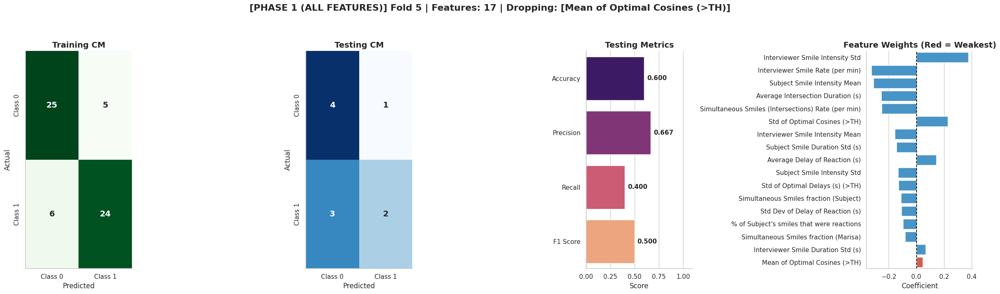

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


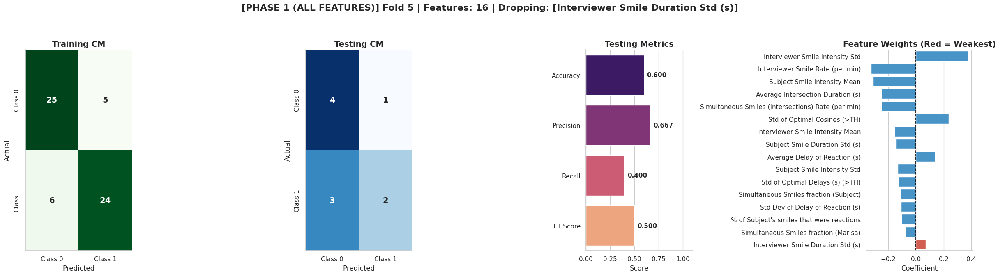

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


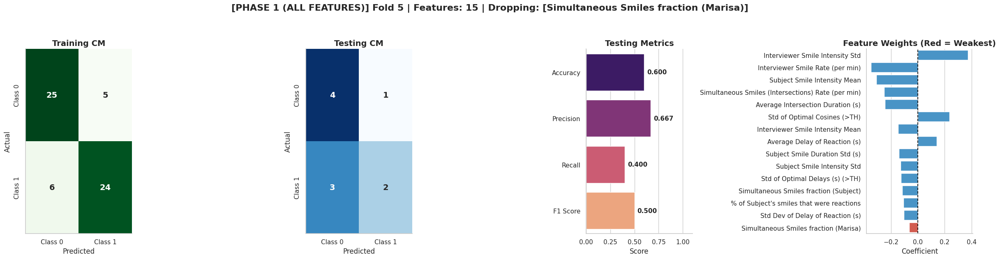

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


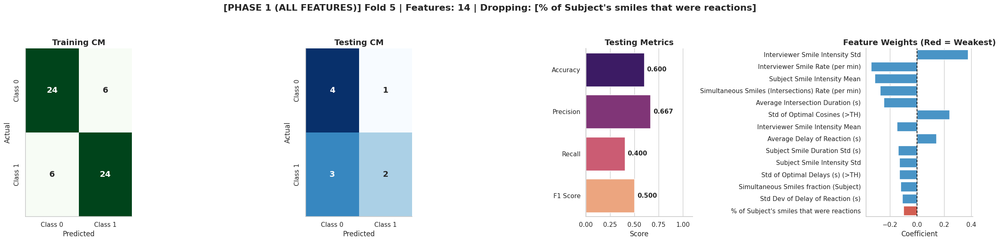

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


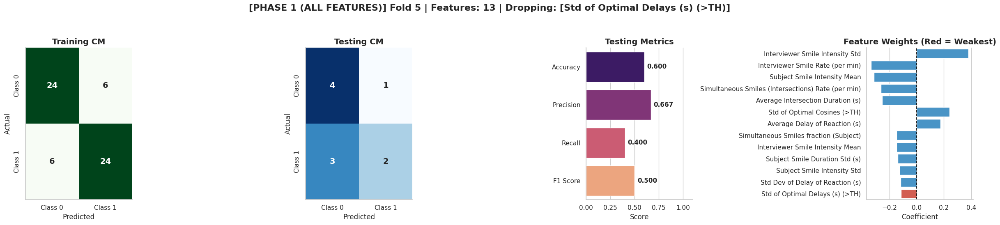

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


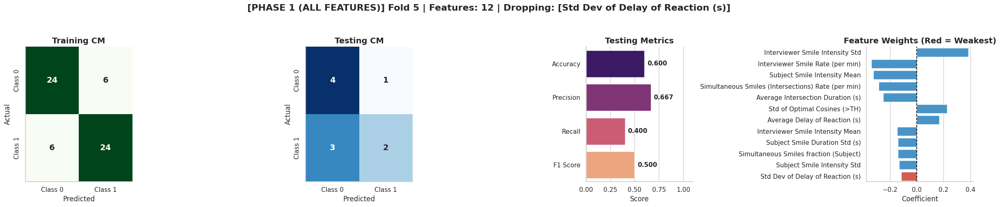

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


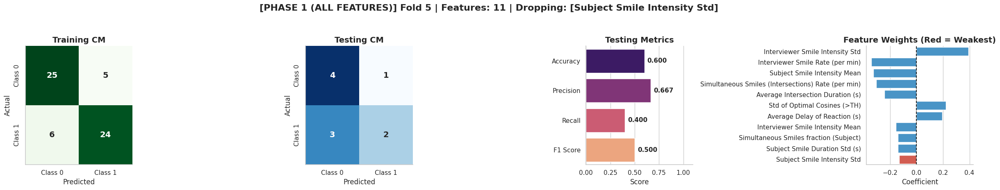

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


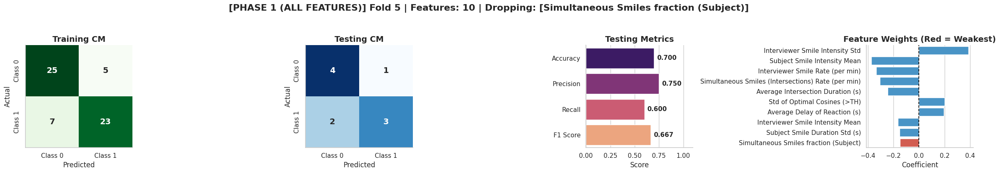

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


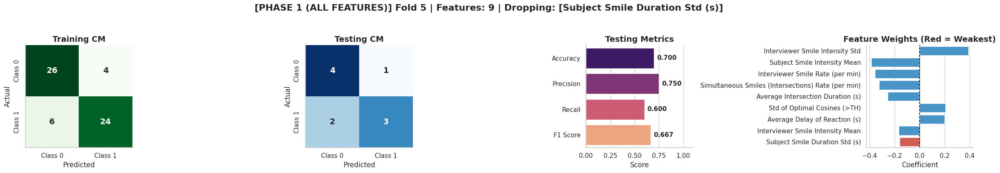

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


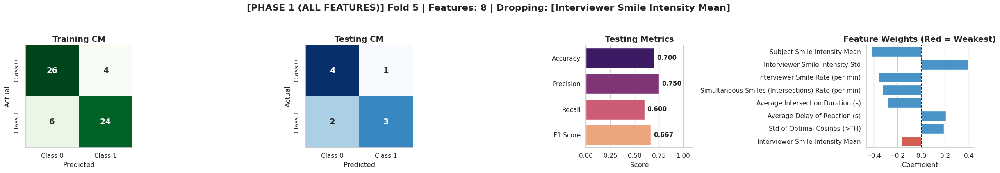

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


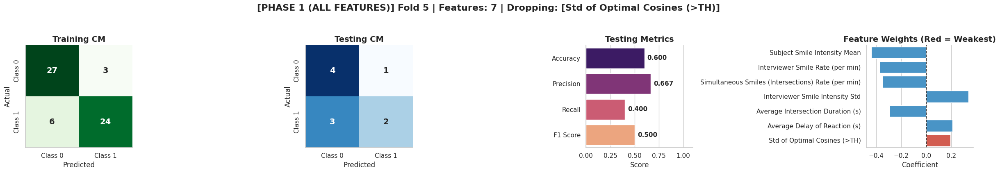

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


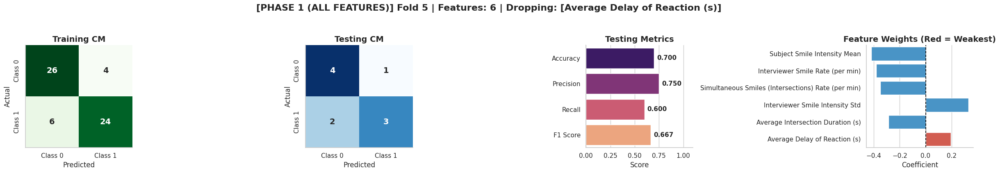

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


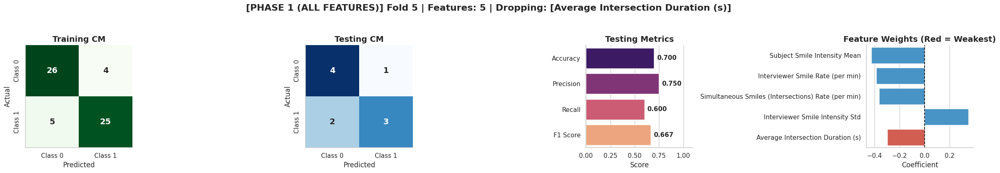

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


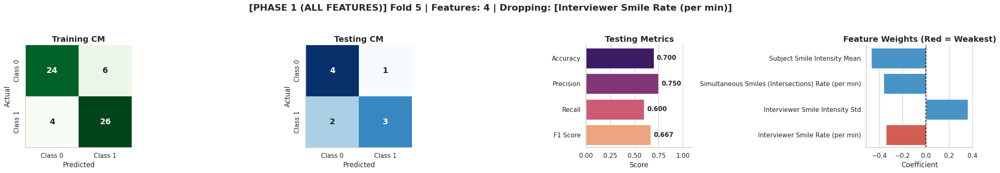

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


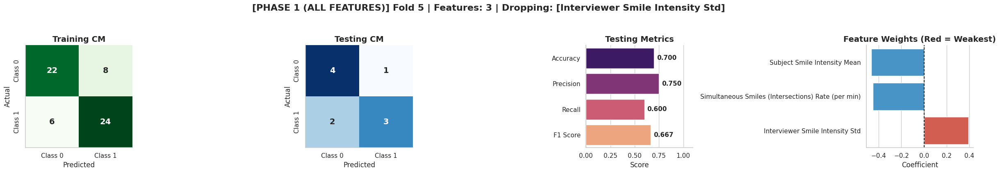

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


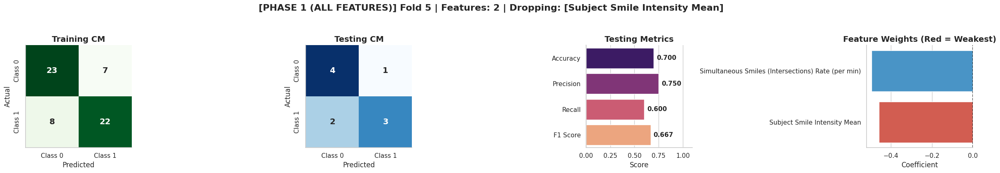

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


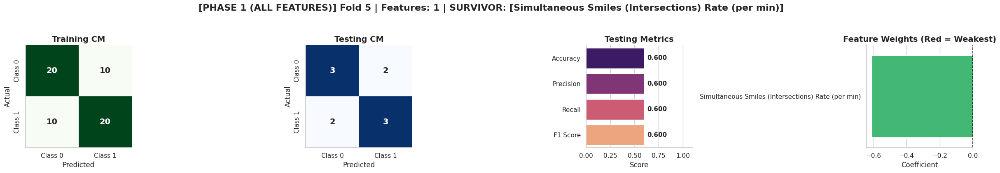


[PHASE 1 (ALL FEATURES)] STARTING FOLD 6 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


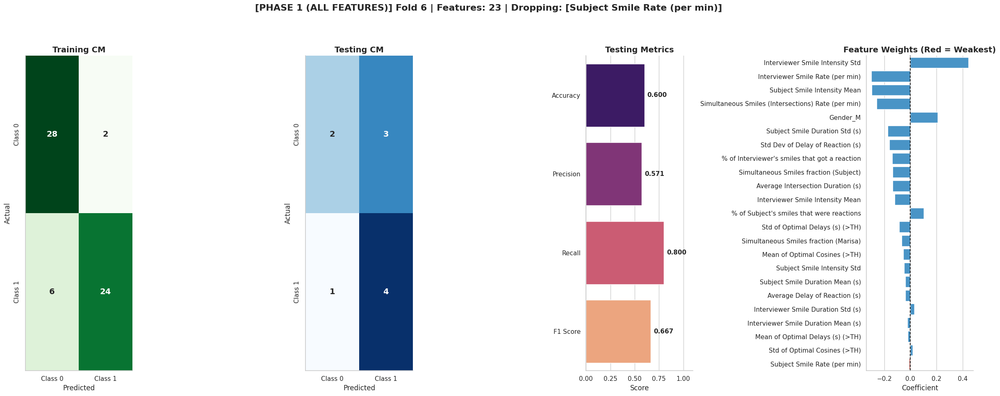

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


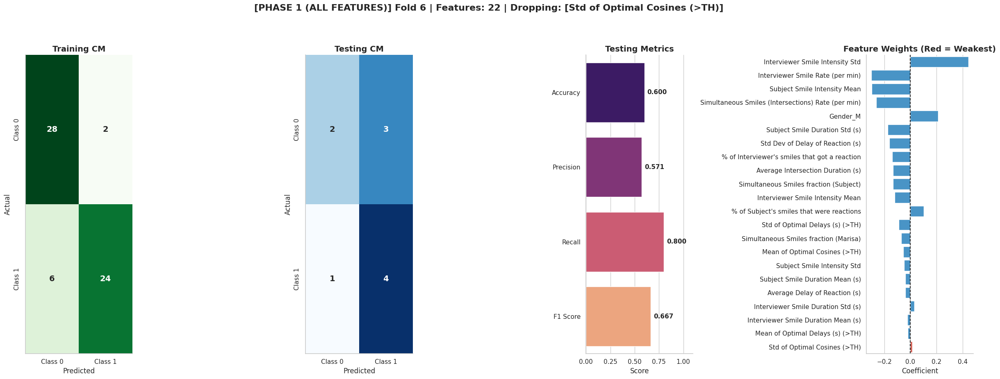

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


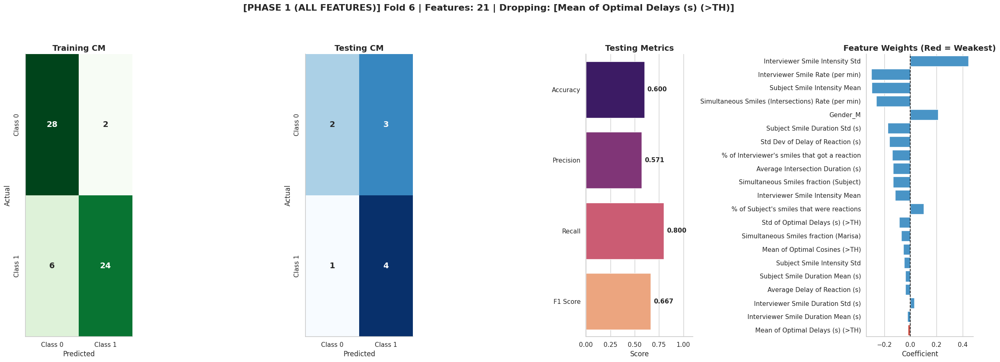

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


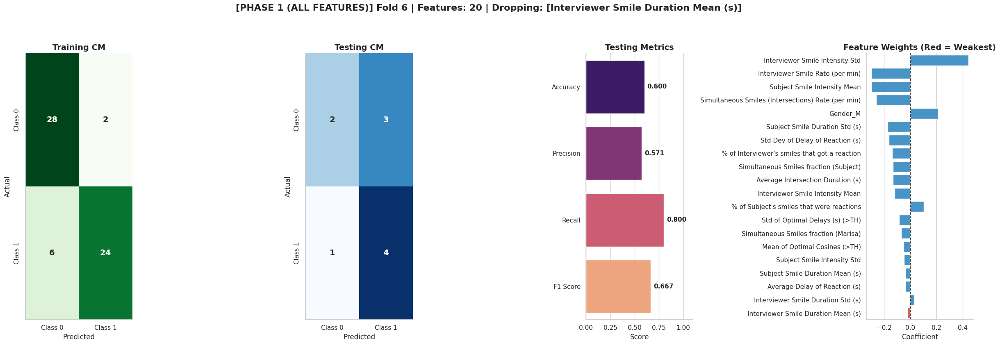

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


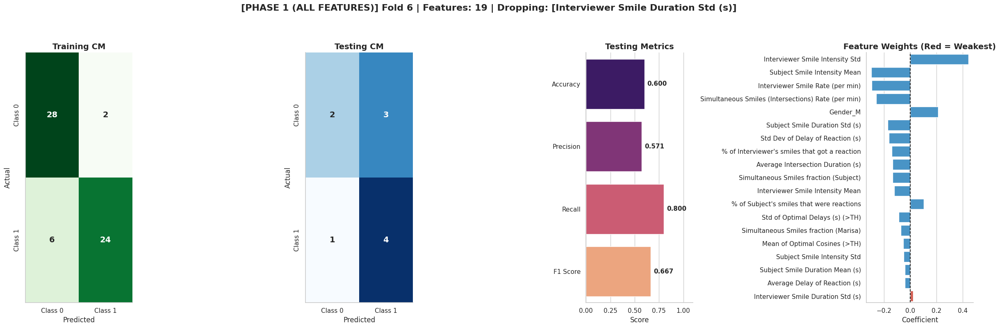

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


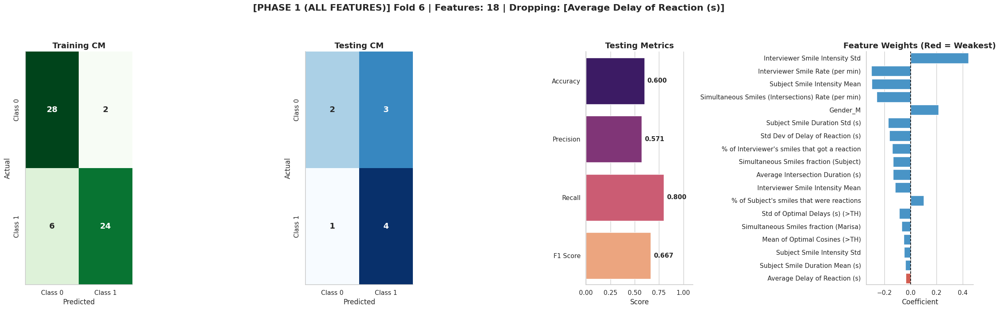

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


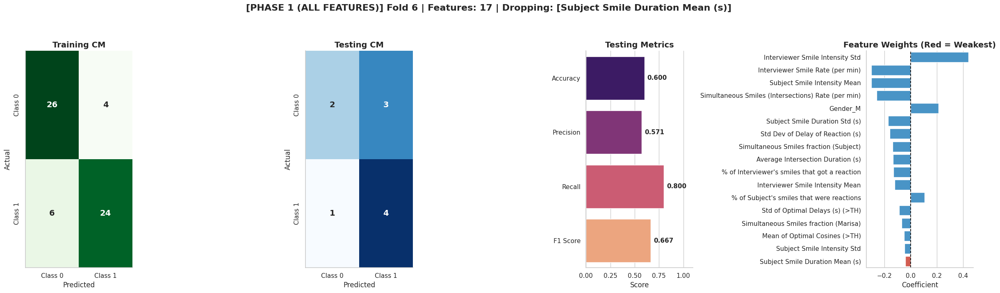

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


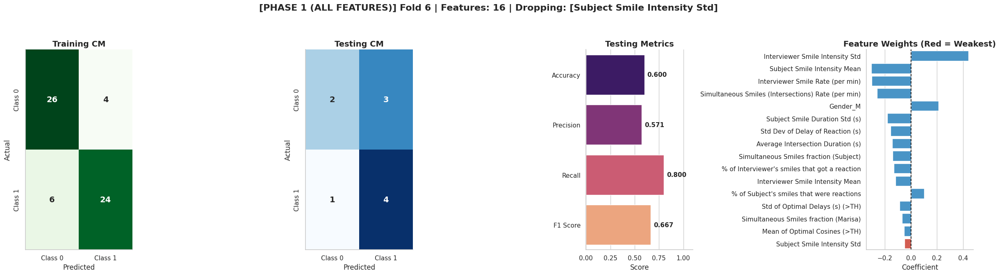

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


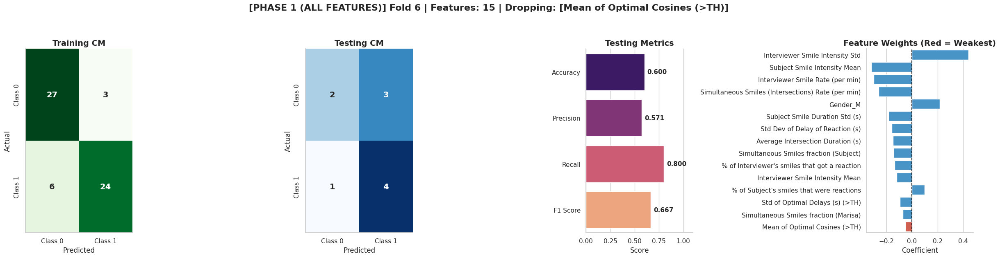

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


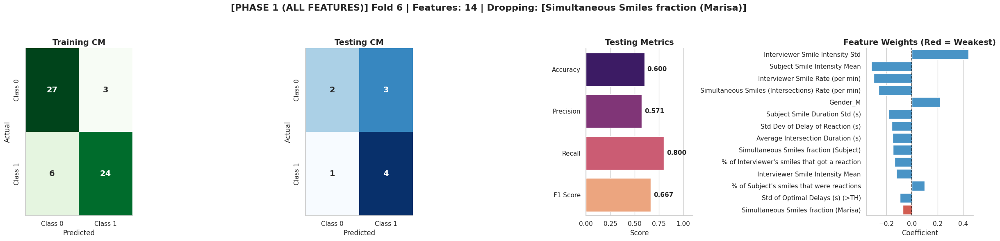

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


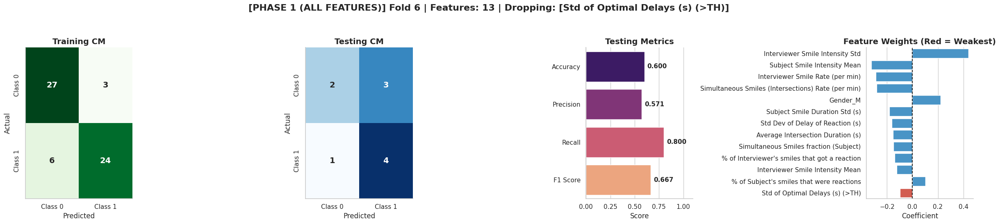

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


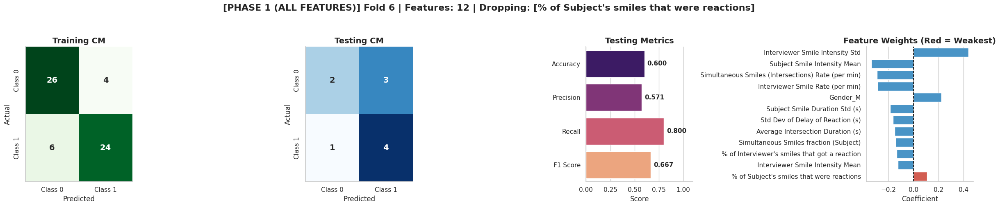

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


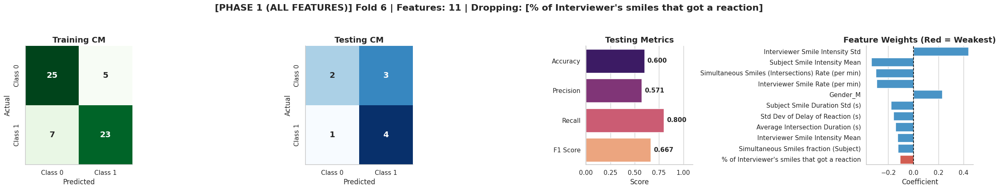

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


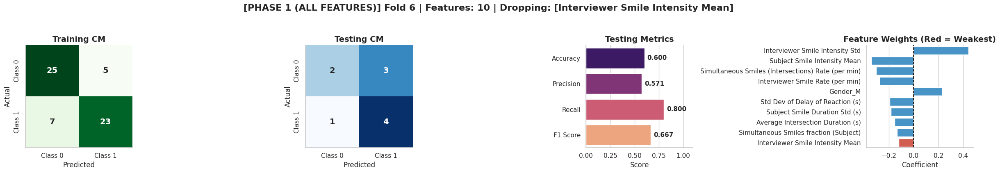

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


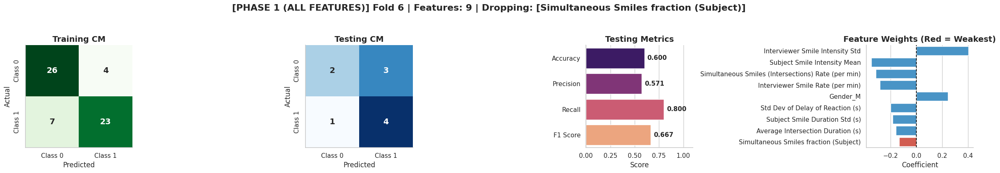

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


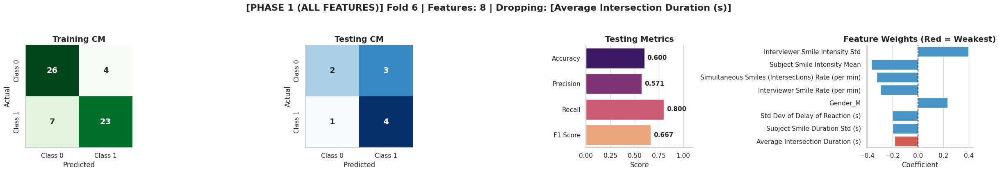

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


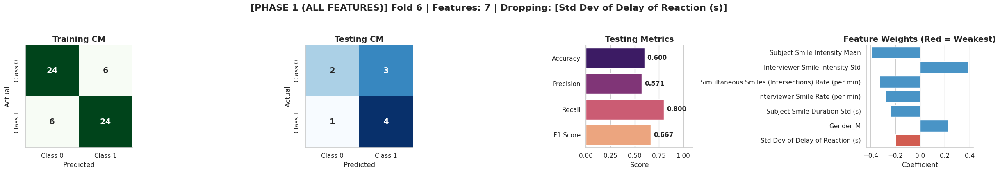

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


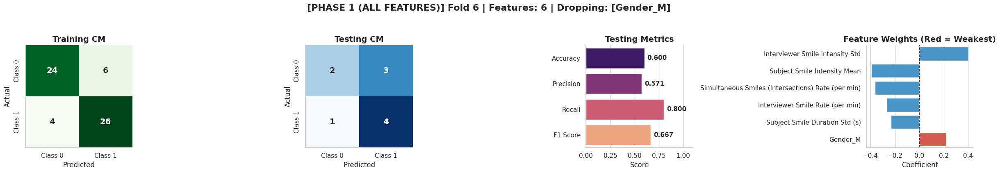

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


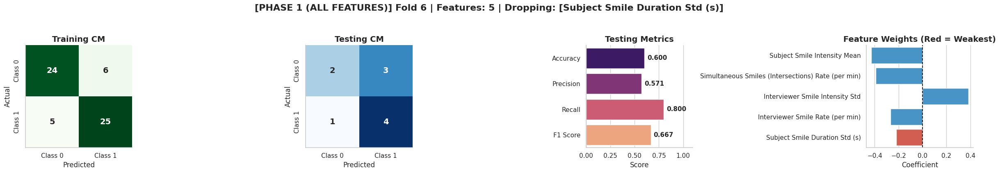

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


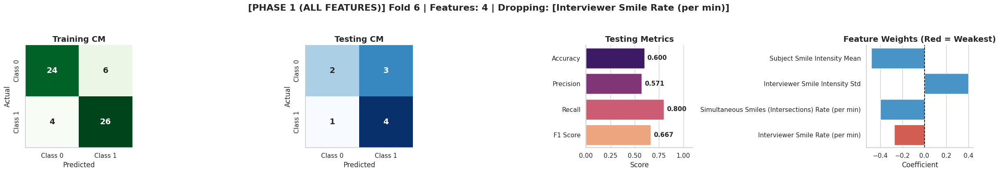

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


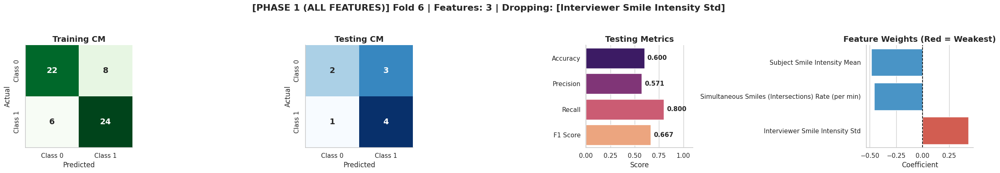

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


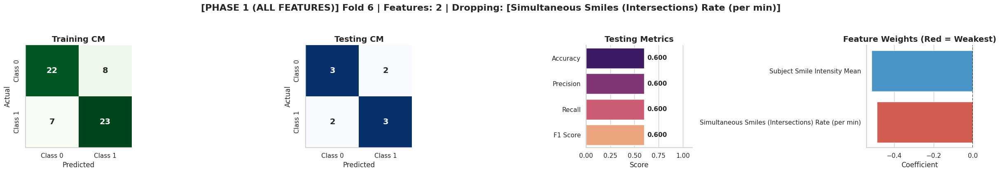

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


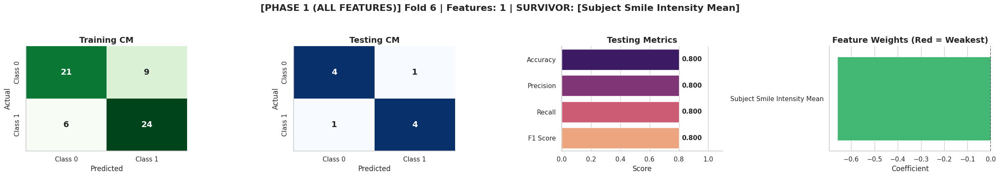


[PHASE 1 (ALL FEATURES)] STARTING FOLD 7 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


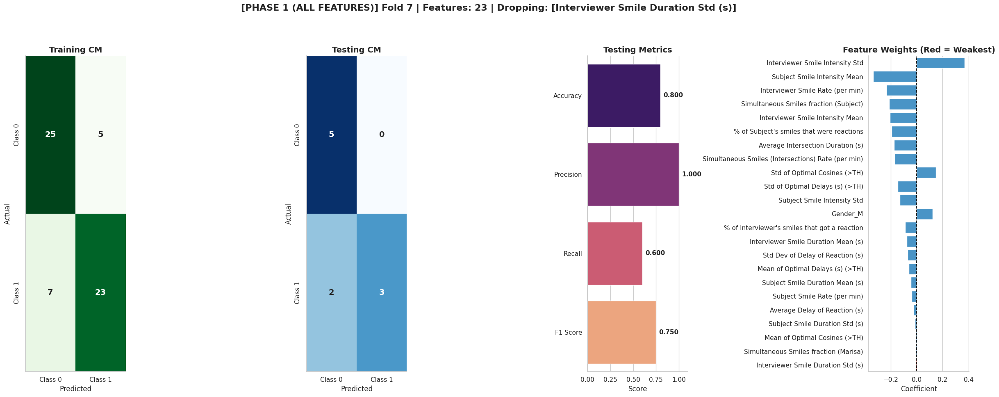

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


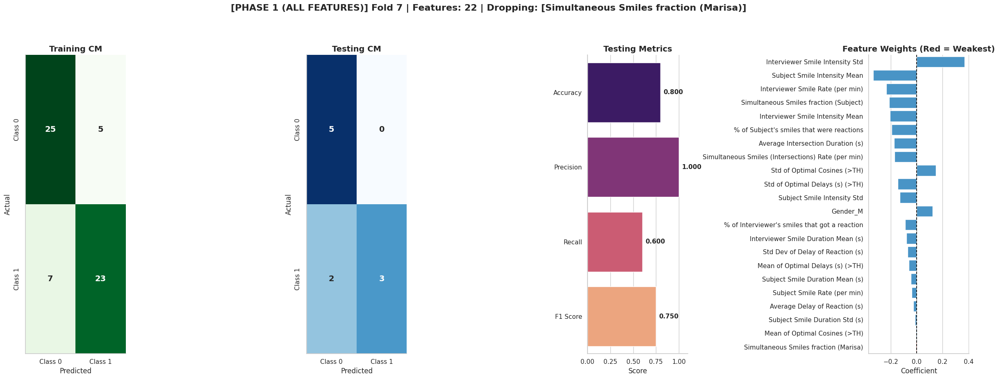

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


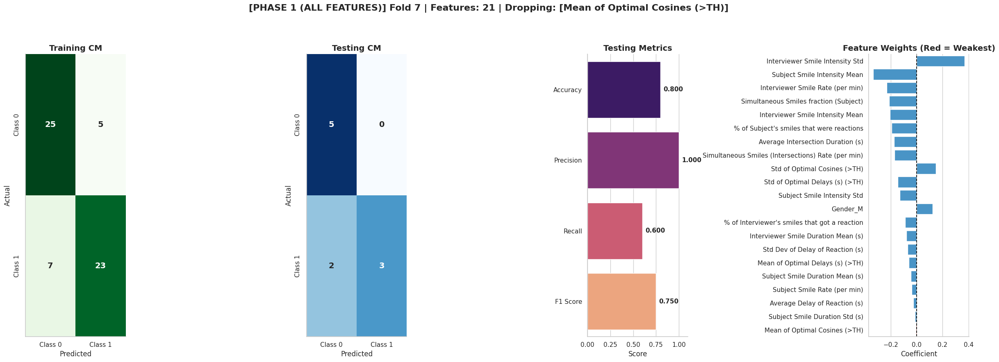

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


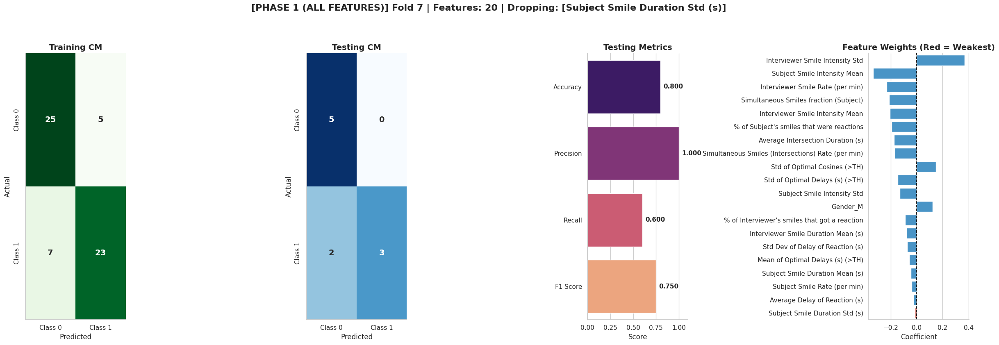

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


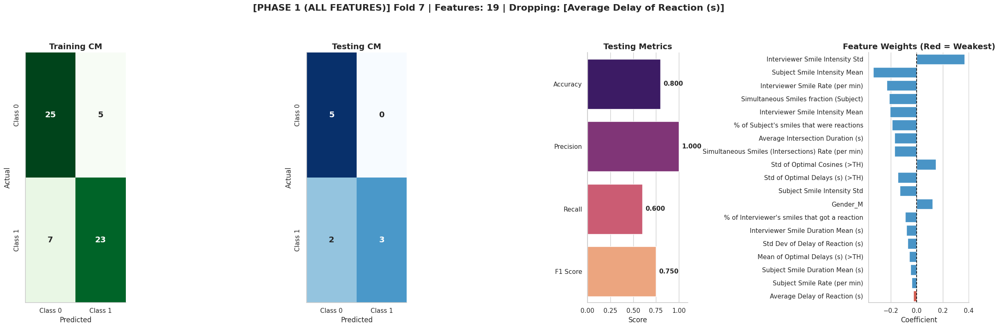

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


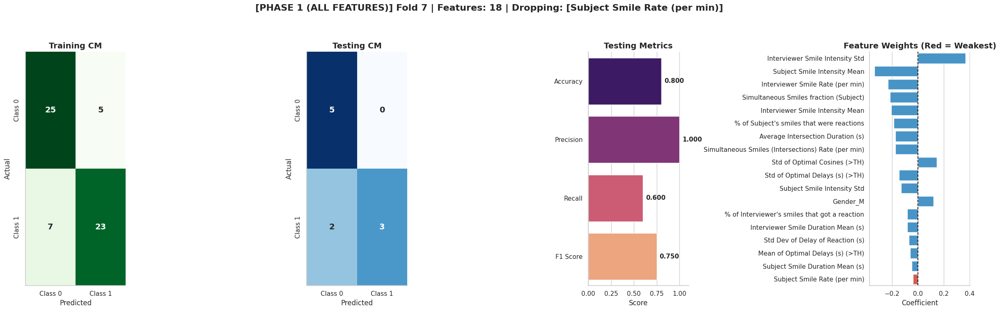

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


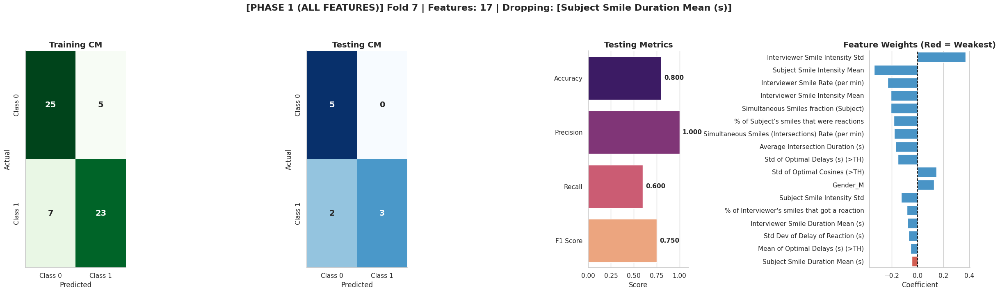

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


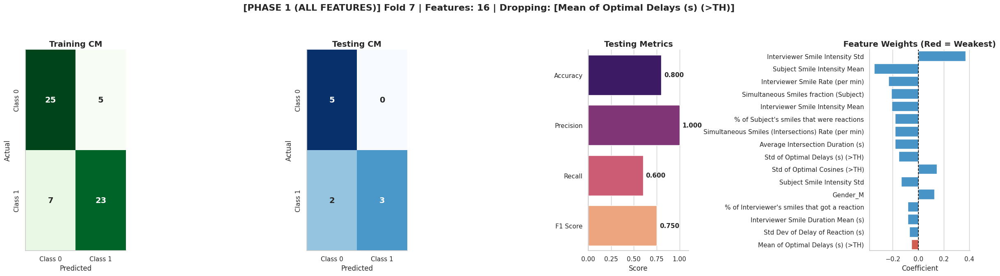

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


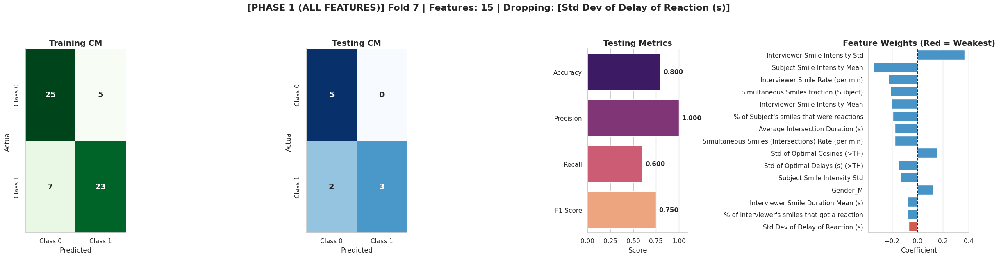

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


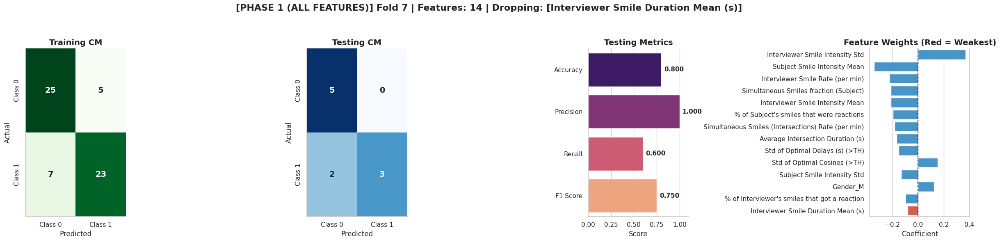

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


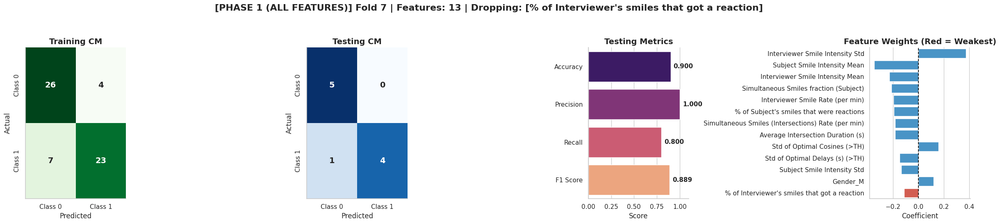

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


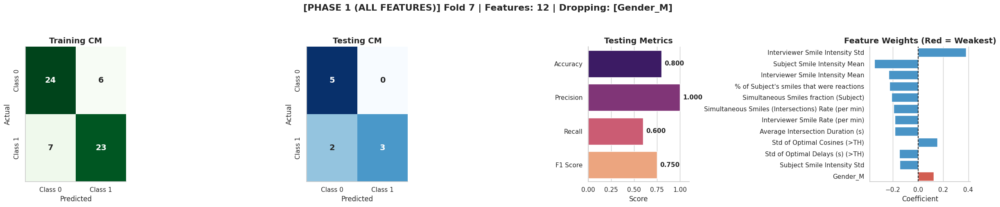

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


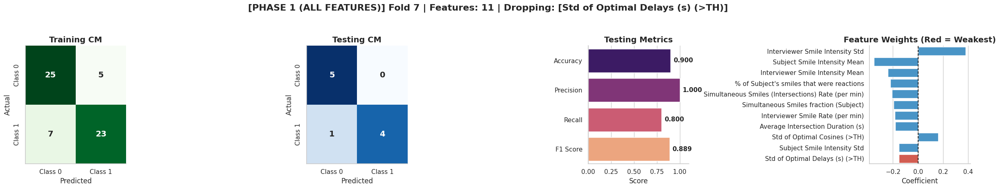

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


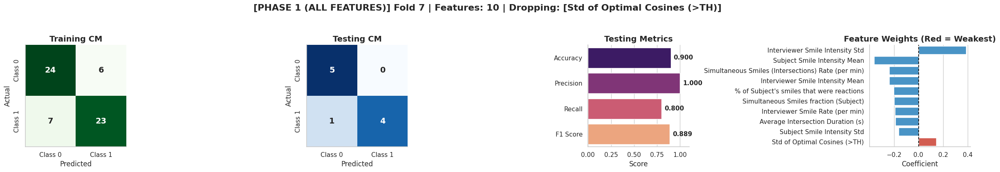

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


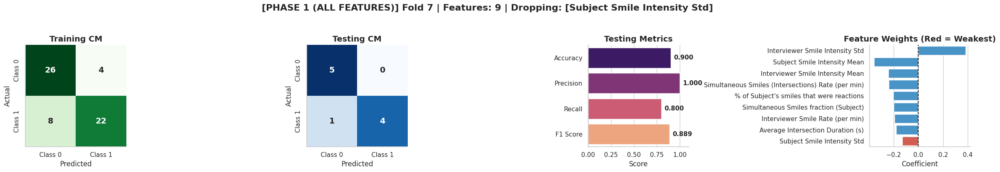

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


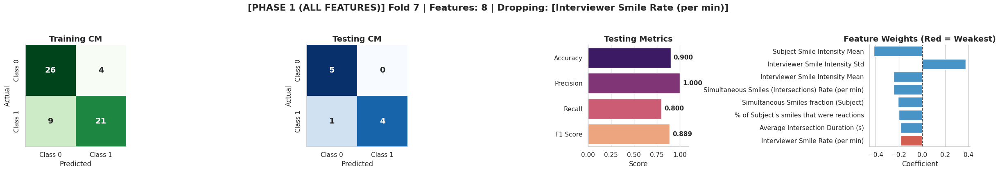

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


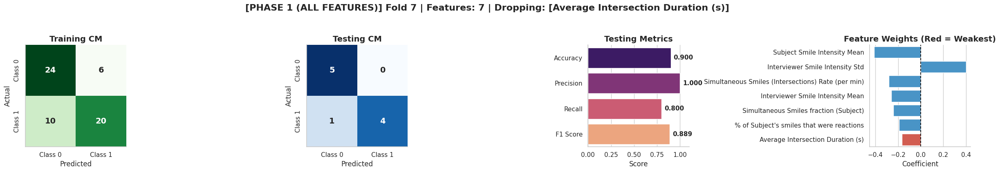

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


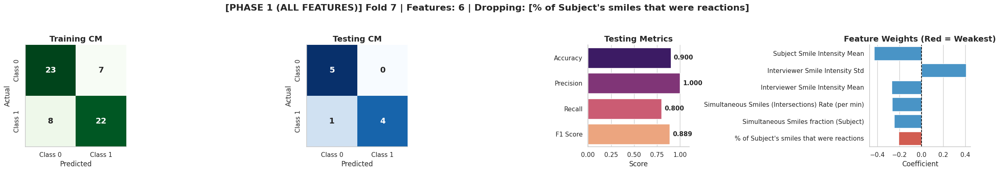

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


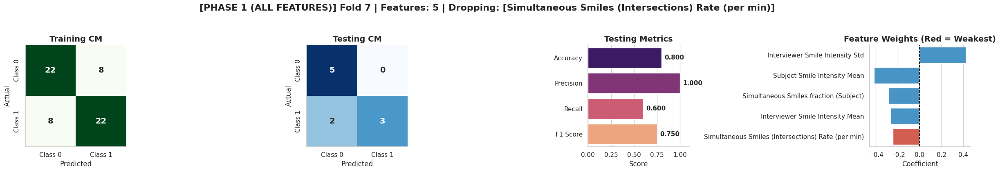

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


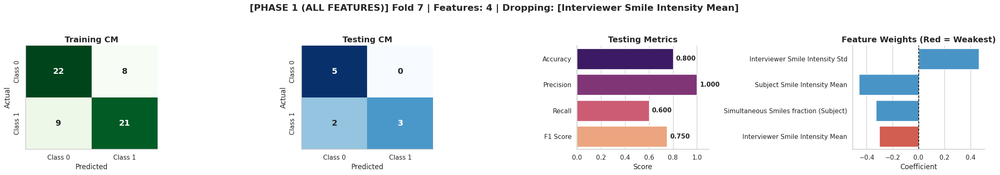

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


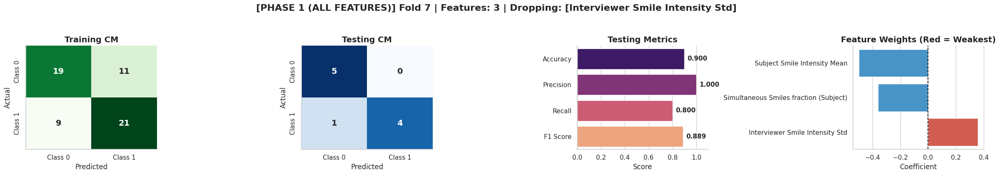

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


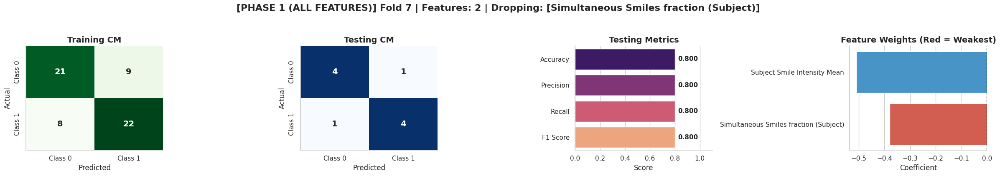

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


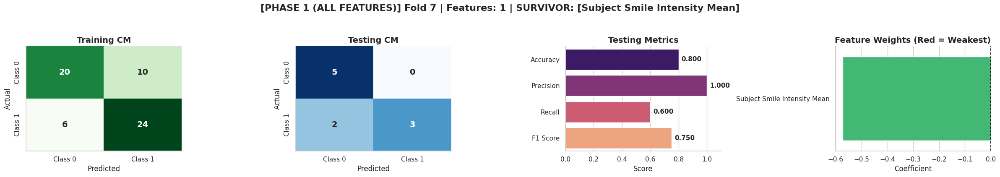

/tmp/ipykernel_161186/2202589265.py:172: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mean_Survival_Score', y=scores_df.index, data=scores_df, palette='magma', ax=axes[1])


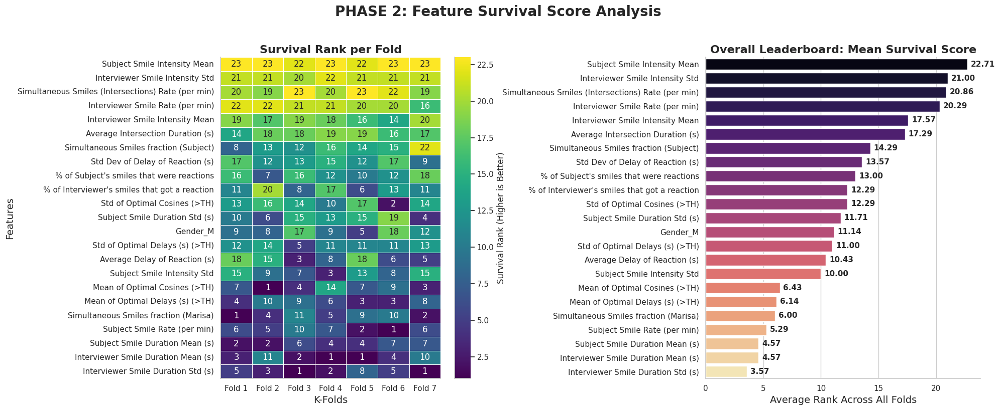


############################################################
PHASE 3: FINAL SHOWDOWN
Features that survived to the end of at least 1 fold: ['Subject Smile Intensity Mean', 'Simultaneous Smiles (Intersections) Rate (per min)']
Applying pruning process exclusively on these 2 features...
############################################################


[PHASE 3 (SUBSET)] STARTING FOLD 1 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


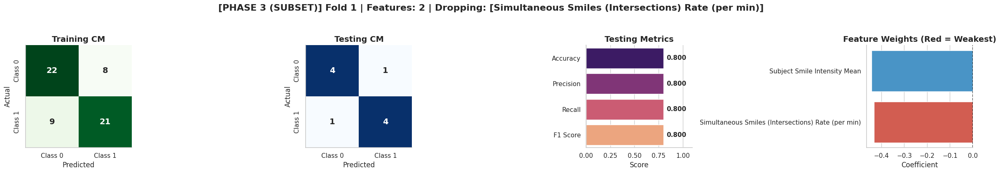

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


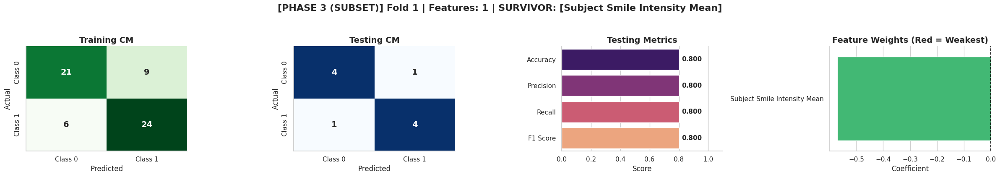


[PHASE 3 (SUBSET)] STARTING FOLD 2 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


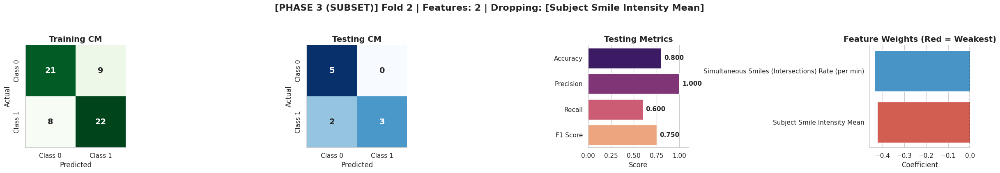

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


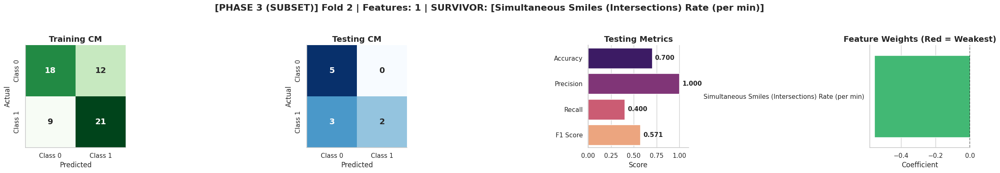


[PHASE 3 (SUBSET)] STARTING FOLD 3 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


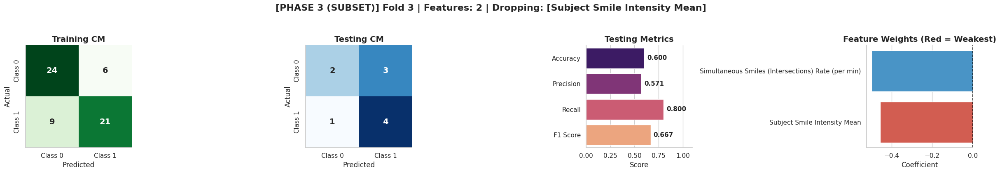

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


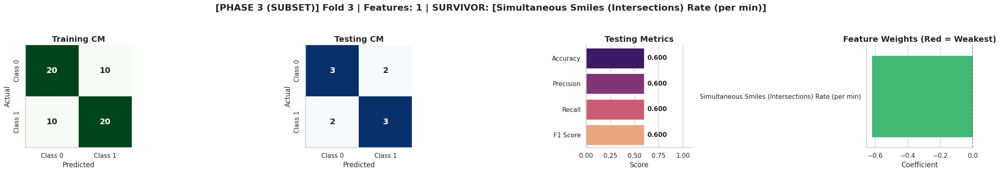


[PHASE 3 (SUBSET)] STARTING FOLD 4 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


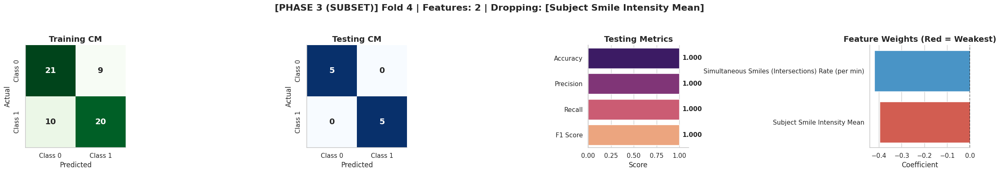

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


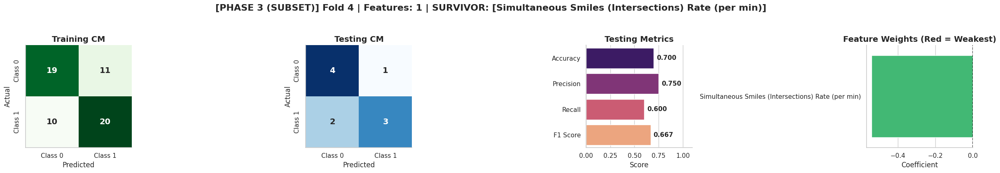


[PHASE 3 (SUBSET)] STARTING FOLD 5 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


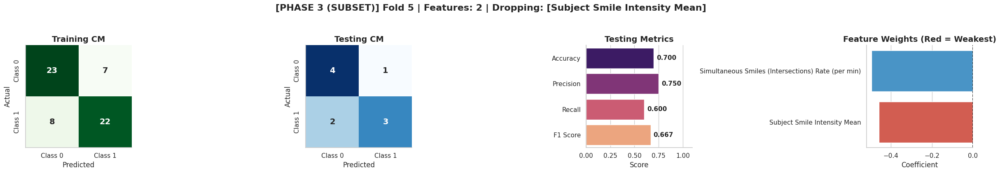

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


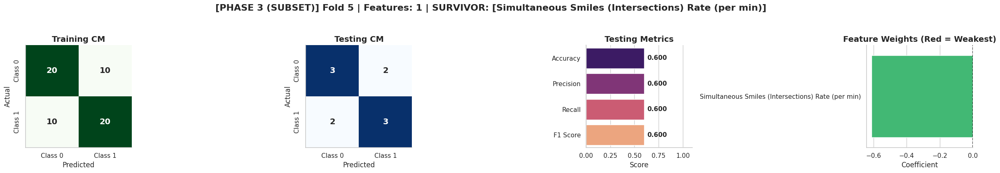


[PHASE 3 (SUBSET)] STARTING FOLD 6 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


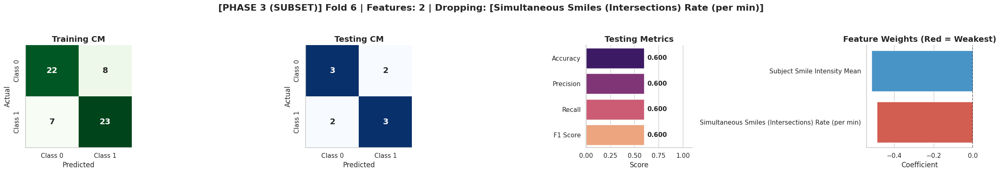

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


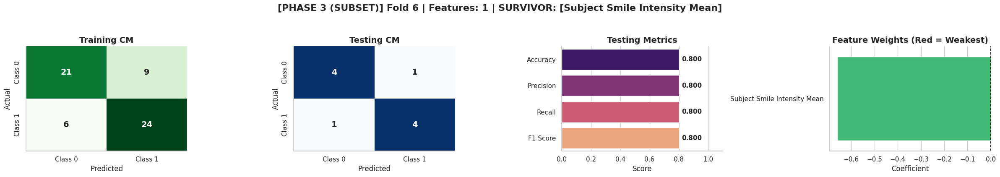


[PHASE 3 (SUBSET)] STARTING FOLD 7 PRUNING


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


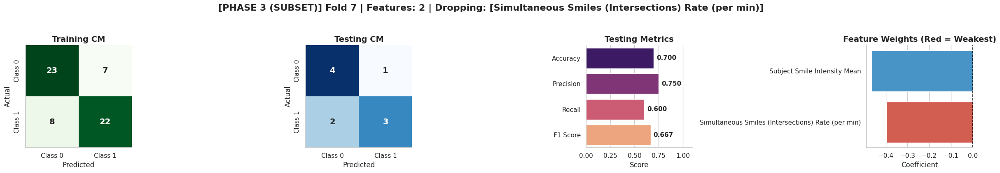

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


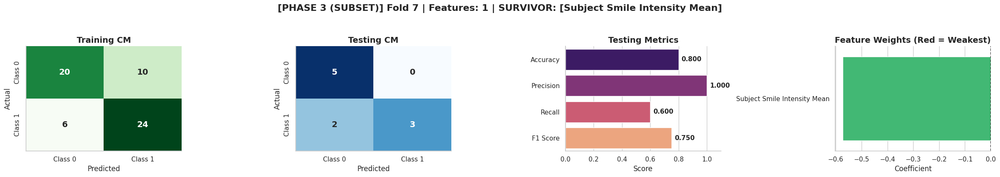

/tmp/ipykernel_161186/2202589265.py:219: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mean_Survival_Score', y=phase3_scores_df.index, data=phase3_scores_df, palette='viridis')


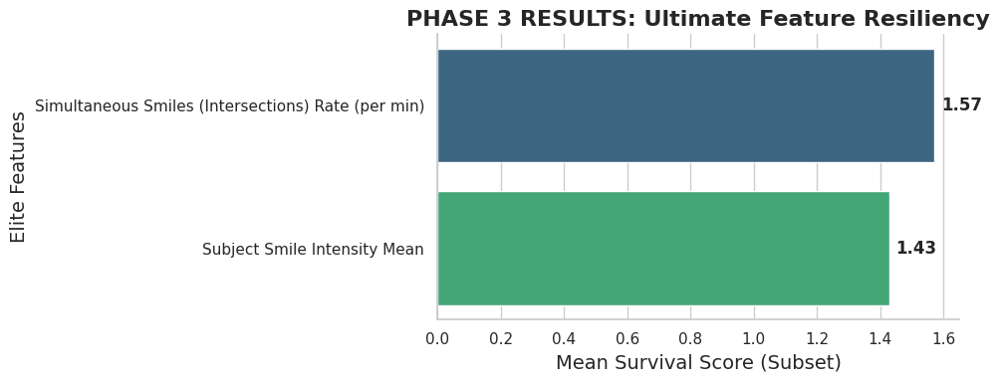

In [11]:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH):
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        
        # Execute the full nested loop
        evaluate_nested_pruning(X=X_scaled, y=y, K_FOLDS=7, use_l1=False, C_value=1/10)

# Method2

In [12]:
def evaluate_sqrt_n_feature_selection(X, y, K_FOLDS=7, C_value=1.0, max_iter=10000):
    """
    Phase 1: 7-Fold CV to extract top sqrt(n) features per fold.
    Phase 2: Join all extracted features into a unique subset.
    Phase 3: Train globally on 60 samples, test on 10 samples using the subset.
    Phase 4: Display a matrix ranking features across all folds (Highest Weight = Highest Index).
    """
    sns.set_theme(style="whitegrid", palette="muted")
    
    # --- Configuration ---
    n_samples = len(X)
    top_k = int(np.round(np.sqrt(n_samples))) # sqrt(70) ~ 8 features
    
    if C_value == 0 or C_value is None:
        model_params = {'penalty': None, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}
    else:
        model_params = {'penalty': 'l2', 'C': C_value, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}

    log_reg = LogisticRegression(**model_params)
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    # Set to store all unique features picked across all 7 folds
    all_picked_features = set()
    
    # Dictionary to store the rank of features in each fold
    fold_ranks_history = {}
    
    print(f"\n{'='*70}")
    print(f"PHASE 1: K-FOLD FEATURE SELECTION (Top {top_k} features per fold)")
    print(f"{'='*70}")

    # =========================================================================
    # PHASE 1: K-Fold Loop
    # =========================================================================
    for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
        X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
        y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
        
        # Train model
        log_reg.fit(X_tr, y_tr)
        y_te_pred = log_reg.predict(X_te)
        
        # Calculate Metrics
        test_cm = confusion_matrix(y_te, y_te_pred, labels=[0, 1])
        acc = accuracy_score(y_te, y_te_pred)
        prec = precision_score(y_te, y_te_pred, zero_division=0)
        rec = recall_score(y_te, y_te_pred, zero_division=0)
        f1 = f1_score(y_te, y_te_pred, zero_division=0)
        
        test_metrics = pd.DataFrame({
            "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
            "Score": [acc, prec, rec, f1]
        })
        
        # Extract Coefficients and sort by absolute value
        coefs = log_reg.coef_[0]
        abs_coefs = np.abs(coefs)
        
        # Calculate ranks: ascending=True means Highest Weight = Highest Rank (e.g., 17)
        feature_ranks = pd.Series(abs_coefs).rank(ascending=True, method='min').astype(int)
        fold_ranks_history[f"Fold {fold}"] = dict(zip(X.columns, feature_ranks))
        
        # Find the indices of the top_k features
        top_indices = np.argsort(abs_coefs)[-top_k:]
        picked_features_for_fold = X.columns[top_indices].tolist()
        
        # Add them to the global tracking set
        all_picked_features.update(picked_features_for_fold)
        
        # Setup DataFrame for plotting weights
        iter_df = pd.DataFrame({
            'Feature': X.columns,
            'Coefficient': coefs,
            'Abs_Coef': abs_coefs,
            'Picked': [feat in picked_features_for_fold for feat in X.columns]
        }).sort_values(by='Abs_Coef', ascending=False)
        
        # Color palette: Green if picked, Grey if ignored
        custom_palette = {feat: '#2ecc71' if picked else '#bdc3c7' 
                          for feat, picked in zip(iter_df['Feature'], iter_df['Picked'])}
        
        # --- PER-FOLD PLOT ---
        fig, axes = plt.subplots(1, 3, figsize=(18, 5))
        fig.suptitle(f'Fold {fold} of {K_FOLDS} | Highlighting Top {top_k} Features', 
                     fontsize=16, fontweight='bold', y=1.05)
        
        # Plot 1: Test CM
        sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
                    annot_kws={"size": 16, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        axes[0].set_title(f'Fold {fold} Testing CM', fontsize=14, fontweight='bold')
        axes[0].set_xlabel('Predicted', fontsize=12)
        axes[0].set_ylabel('Actual', fontsize=12)
        
        # Plot 2: Test Metrics
        sns.barplot(x='Score', y='Metric', data=test_metrics, ax=axes[1], hue='Metric', palette='magma', legend=False)
        axes[1].set_title(f'Fold {fold} Testing Metrics', fontsize=14, fontweight='bold')
        axes[1].set_xlim(0, 1.1)
        axes[1].set_ylabel('')
        for i in axes[1].containers:
            axes[1].bar_label(i, fmt='%.3f', padding=5, size=12, weight='bold')
            
        # Plot 3: Feature Weights (Highlighted)
        sns.barplot(x='Coefficient', y='Feature', data=iter_df, ax=axes[2], hue='Feature', palette=custom_palette, legend=False)
        axes[2].set_title(f'Feature Weights (Green = Top $\sqrt{{n}}$ Picked)', fontsize=14, fontweight='bold')
        axes[2].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
        axes[2].set_ylabel('')
        
        sns.despine()
        plt.tight_layout()
        plt.show()

    # =========================================================================
    # PHASE 2 & 3: Global Training
    # =========================================================================
    global_features = list(all_picked_features)
    
    print(f"\n{'='*70}")
    print(f"PHASE 2 & 3: GLOBAL TRAINING")
    print(f"Total Unique Features Selected by the Folds: {len(global_features)}")
    print(f"{'='*70}\n")
    
    # Subset data to ONLY the features that were picked by at least one fold
    X_global = X[global_features]
    
    # Split exactly 60 for training, 10 for testing
    X_tr_g, X_te_g, y_tr_g, y_te_g = train_test_split(
        X_global, y, 
        test_size=10, 
        stratify=y, 
        random_state=42
    )
    
    # Train Global Model
    log_reg.fit(X_tr_g, y_tr_g)
    y_te_g_pred = log_reg.predict(X_te_g)
    
    # Calculate Global Metrics
    global_cm = confusion_matrix(y_te_g, y_te_g_pred, labels=[0, 1])
    g_acc = accuracy_score(y_te_g, y_te_g_pred)
    g_prec = precision_score(y_te_g, y_te_g_pred, zero_division=0)
    g_rec = recall_score(y_te_g, y_te_g_pred, zero_division=0)
    g_f1 = f1_score(y_te_g, y_te_g_pred, zero_division=0)
    
    global_metrics = pd.DataFrame({
        "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
        "Score": [g_acc, g_prec, g_rec, g_f1]
    })
    
    global_coefs_df = pd.DataFrame({
        'Feature': X_global.columns,
        'Coefficient': log_reg.coef_[0],
        'Abs_Coef': np.abs(log_reg.coef_[0])
    }).sort_values(by='Abs_Coef', ascending=False)
    
    # --- GLOBAL PLOT ---
    fig_g, axes_g = plt.subplots(1, 3, figsize=(18, max(5, len(global_features)*0.4)))
    fig_g.suptitle(f'GLOBAL EVALUATION | 60 Train / 10 Test | Using {len(global_features)} Selected Features', 
                 fontsize=18, fontweight='bold', y=1.05)
    
    # Global Test CM
    sns.heatmap(global_cm, annot=True, fmt='d', cmap='Purples', ax=axes_g[0],
                annot_kws={"size": 18, "weight": "bold"}, cbar=False,
                xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
    axes_g[0].set_title(f'Global Testing CM (10 Samples)', fontsize=15, fontweight='bold')
    axes_g[0].set_xlabel('Predicted', fontsize=13)
    axes_g[0].set_ylabel('Actual', fontsize=13)
    
    # Global Test Metrics
    sns.barplot(x='Score', y='Metric', data=global_metrics, ax=axes_g[1], hue='Metric', palette='flare', legend=False)
    axes_g[1].set_title(f'Global Testing Metrics', fontsize=15, fontweight='bold')
    axes_g[1].set_xlim(0, 1.1)
    axes_g[1].set_ylabel('')
    for i in axes_g[1].containers:
        axes_g[1].bar_label(i, fmt='%.3f', padding=5, size=13, weight='bold')
        
    # Global Final Weights
    sns.barplot(x='Coefficient', y='Feature', data=global_coefs_df, ax=axes_g[2], hue='Feature', palette='mako', legend=False)
    axes_g[2].set_title(f'Final Global Feature Weights', fontsize=15, fontweight='bold')
    axes_g[2].axvline(x=0, color='black', linestyle='--', linewidth=1.2)
    axes_g[2].set_ylabel('')
    
    sns.despine()
    plt.tight_layout()
    plt.show()

    # =========================================================================
    # PHASE 4: Feature Ranking Matrix Across All Folds (Highest = Best)
    # =========================================================================
# Convert fold ranks to DataFrame
    ranks_df = pd.DataFrame(fold_ranks_history)
    
    # Calculate an Average Rank to sort the features (Higher average = better feature)
    ranks_df['Average_Rank'] = ranks_df.mean(axis=1)
    ranks_df = ranks_df.sort_values(by='Average_Rank', ascending=False)
    
    # Create subplots with a width ratio (Heatmap 4x wider than Bar plot)
    fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={'width_ratios': [4, 1]})
    fig.suptitle('Feature Survival Score Analysis', fontsize=20, fontweight='bold', y=1.02)

    # 1. Heatmap (Left Axis)
    max_rank = len(X.columns)
    sns.heatmap(ranks_df.drop(columns=['Average_Rank']), annot=True, fmt="d", cmap="viridis", 
                cbar=False, linewidths=0.5, ax=axes[0])
    
    axes[0].set_title('Feature Rankings Across K-Folds', fontsize=16, fontweight='bold')
    axes[0].set_xlabel('Cross-Validation Folds', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Features (Sorted by Highest Average Rank)', fontsize=14, fontweight='bold')
    
    # 2. Average Rank Bar Chart (Right Axis)
    sns.barplot(x='Average_Rank', y=ranks_df.index, data=ranks_df, 
                ax=axes[1], palette='Blues_r', orient='h')
    
    axes[1].set_title('Mean Survival Score', fontsize=16, fontweight='bold')
    axes[1].set_xlabel('Avg Rank', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('') # Hide y-labels on the bar plot as they duplicate the heatmap
    axes[1].tick_params(axis='y', which='both', left=False, labelleft=False) # Hide y-axis ticks
    
    # Add values to the bars
    for i in axes[1].containers:
        axes[1].bar_label(i, fmt='%.2f', padding=5, size=11, weight='bold')

    sns.despine()
    plt.tight_layout()
    plt.show()


<>:105: SyntaxWarning: invalid escape sequence '\s'
<>:105: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_161186/1771284136.py:105: SyntaxWarning: invalid escape sequence '\s'
  axes[2].set_title(f'Feature Weights (Green = Top $\sqrt{{n}}$ Picked)', fontsize=14, fontweight='bold')


Preparing data...
Preparation complete: 70 subjects processed.

PHASE 1: K-FOLD FEATURE SELECTION (Top 8 features per fold)


/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


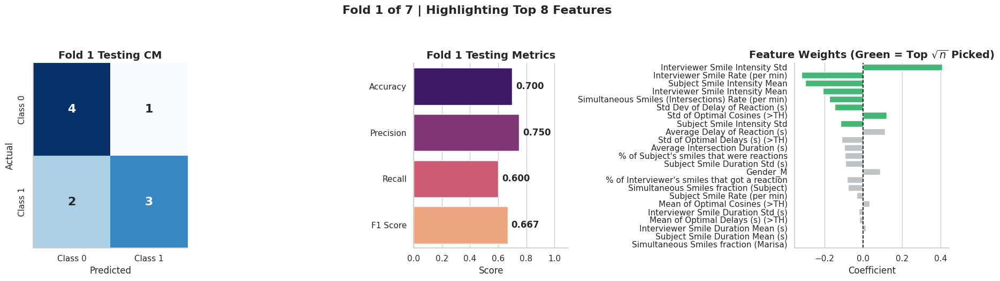

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


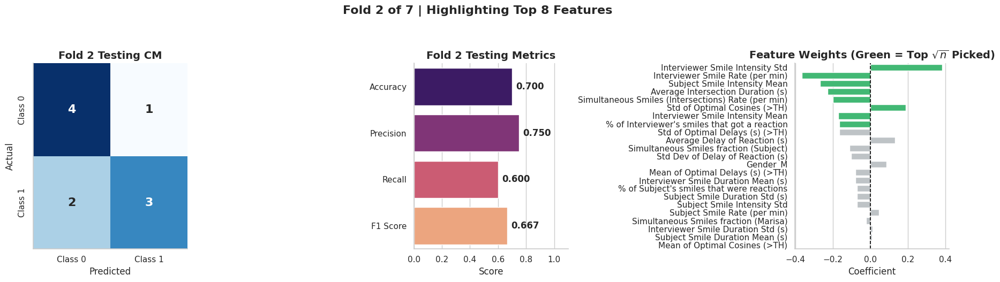

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


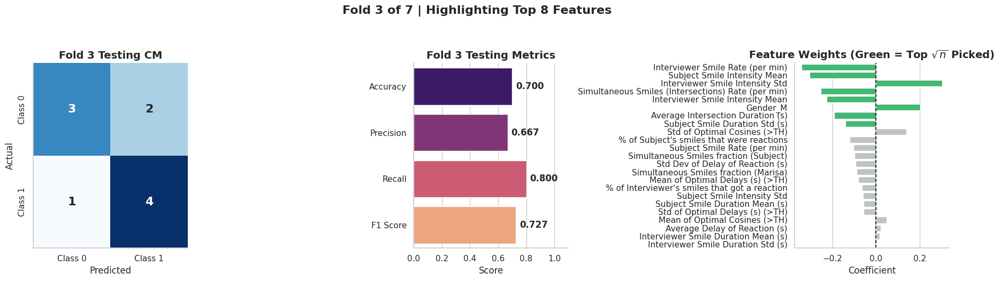

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


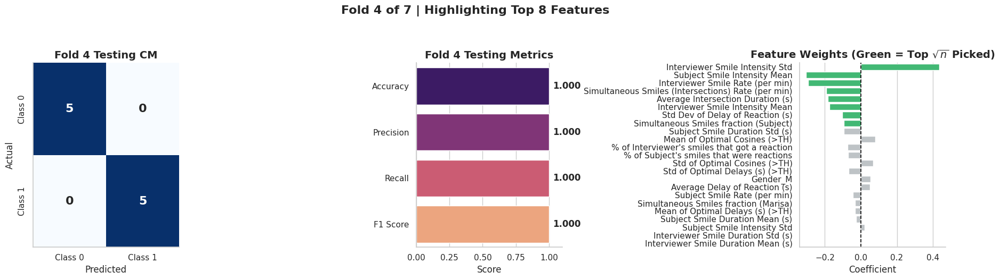

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


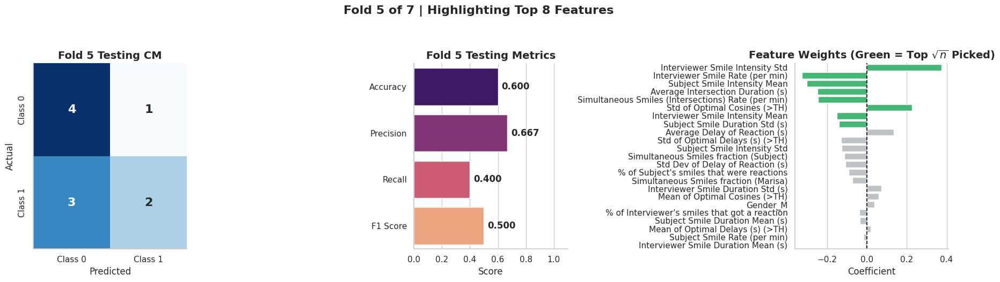

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


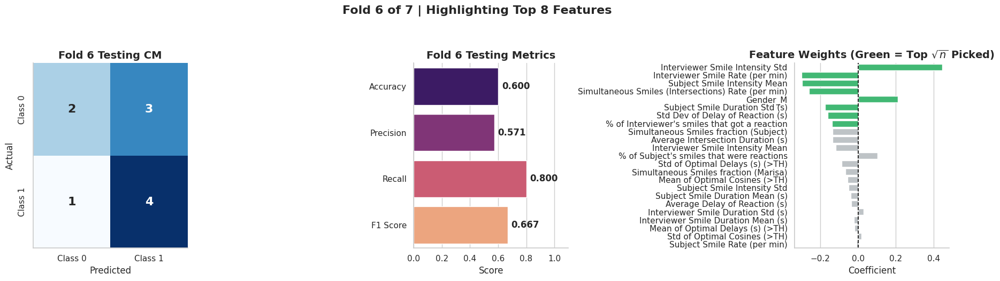

/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


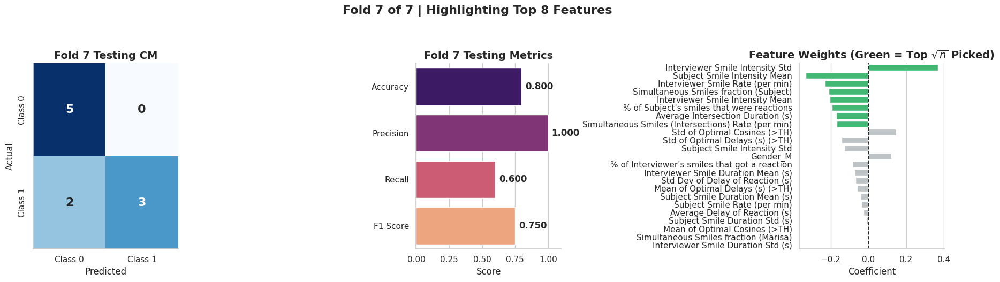


PHASE 2 & 3: GLOBAL TRAINING
Total Unique Features Selected by the Folds: 14



/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


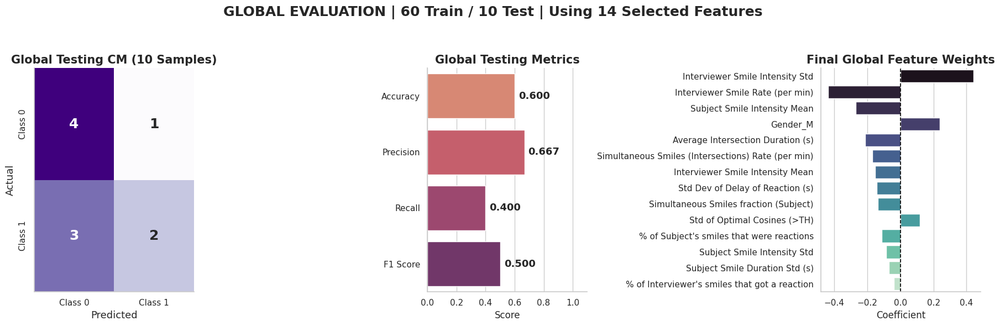

/tmp/ipykernel_161186/1771284136.py:211: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Average_Rank', y=ranks_df.index, data=ranks_df,


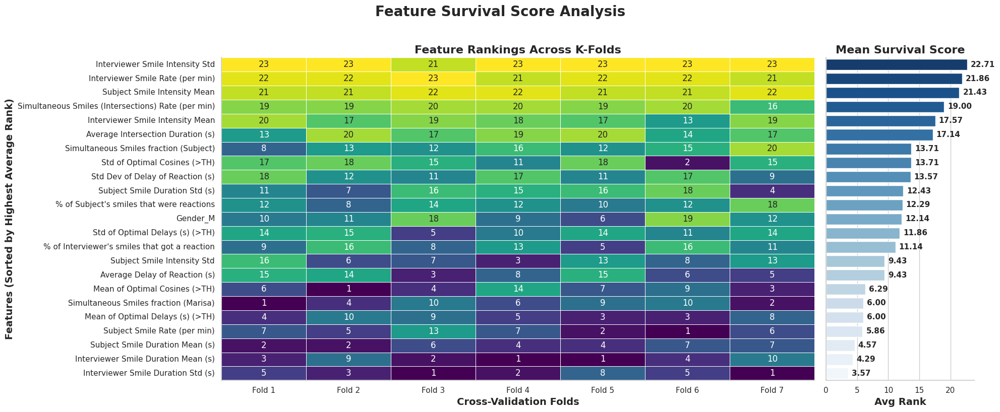

In [13]:
    
# Example Usage:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH): 
        df = pd.read_csv(DATA_PATH)
        
        # Prepare Data (Assuming your prepare_data function is loaded)
        X_scaled, y = prepare_data(df)
        
        # Execute the full pipeline
        evaluate_sqrt_n_feature_selection(X=X_scaled, y=y, K_FOLDS=7, C_value=1/10)

# Method 3

In [3]:
def abbreviate_feature_name(name):
    """Shortens long feature names so they don't overlap on the plot axis."""
    replacements = {
        # 1. Longest phrases first (to avoid partial replacement bugs)
        "% of Subject's smiles that were": "% Subj smiles were",
        "% of Interviewer's smiles that got a": "% Intv smiles got",
        "Simultaneous Smiles (Intersections)": "Simul Overlap",
        "Std Dev of": "Std",
        "Mean of": "Mean",
        
        # 2. Base entities 
        "Interviewer": "Intv", 
        "Subject": "Subj", 
        "Marisa": "Intv",  # Standardizes the specific name to match other Interviewer features
        
        # 3. Specific metrics & terms
        "Smile Duration": "Dur",
        "Smile Intensity": "Int",
        "Smile Rate": "Rate",
        "Simultaneous": "Simul",
        "Intersections": "Overlap", 
        "Reactions": "React", 
        "Reaction": "React",
        "fraction": "frac",
        "Average": "Avg",
        "Optimal": "Opt",
        "Cosines": "Cos",
        "(per min)": "(/min)"
    }
    
    for old, new in replacements.items():
        name = name.replace(old, new)
        
    return name

In [14]:



def plot_feature_rank_dashboard(rank_df, total_features, k_folds):
    """
    Plots a side-by-side dashboard of the feature rank matrix (Heatmap) 
    and the average rank (Bar Chart).
    """
    sns.set_theme(style="whitegrid")
    
    # Create a figure with 2 subplots side-by-side. 
    # width_ratios=[3, 1] means the heatmap gets 75% of the space, bar chart gets 25%
    fig, axes = plt.subplots(1, 2, figsize=(18, 10), gridspec_kw={'width_ratios': [3, 1], 'wspace': 0.05})
    
    # --- 1. Left Subplot: The Rank Matrix (Heatmap) ---
    sns.heatmap(rank_df, annot=True, fmt=".1f", cmap="viridis", 
                cbar_kws={'label': f'Feature Rank (1 = Worst, {total_features} = Best)'},
                linewidths=1, ax=axes[0], annot_kws={"size": 11, "weight": "bold"})
    
    axes[0].set_title(f'Feature Elimination Rank Matrix Across {k_folds} Folds', 
                      fontsize=18, fontweight='bold', pad=20)
    axes[0].set_ylabel('Features (Sorted by Avg Rank)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Validation Folds & Overall Average', fontsize=14, fontweight='bold')
    axes[0].tick_params(axis='y', rotation=0, labelsize=11)
    axes[0].tick_params(axis='x', labelsize=11)
    
    # --- 2. Right Subplot: Average Rank (Bar Chart) ---
    avg_ranks = rank_df['Average Rank'].values
    features = rank_df.index
    
    # Generate colors matching the 'viridis' colormap used in the heatmap
    norm = plt.Normalize(1, total_features)
    colors = plt.cm.viridis(norm(avg_ranks))
    
    sns.barplot(x=avg_ranks, y=features, ax=axes[1], palette=list(colors), hue=features, legend=False)
    
    axes[1].set_title('Average Rank', fontsize=18, fontweight='bold', pad=20)
    axes[1].set_xlabel('Rank Score', fontsize=14, fontweight='bold')
    axes[1].set_xlim(0, total_features + 1) # Give the bars a little breathing room on the right
    
    # Remove Y-axis labels and ticks to seamlessly attach it to the heatmap
    axes[1].set_ylabel('')
    axes[1].tick_params(axis='y', labelleft=False, left=False)
    axes[1].grid(axis='y', visible=False) # Remove horizontal grid lines behind bars
    
    # Annotate the exact value at the end of each bar
    for i, val in enumerate(avg_ranks):
        axes[1].text(val + 0.2, i, f'{val:.1f}', va='center', fontsize=11, fontweight='bold')

    plt.tight_layout()
    plt.show()


def evaluate_kfold_pruning(X, y, K_FOLDS=7, C_value=1.0, max_iter=10000):
    sns.set_theme(style="whitegrid", palette="muted")
    
    # Fix for scikit-learn 1.8 FutureWarning
    if C_value == 0 or C_value is None:
        model_params = {'C': np.inf, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}
    else:
        model_params = {'C': C_value, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}

    log_reg = LogisticRegression(**model_params)
    skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
    
    fold_best_features = {}
    
    # Dictionary to track the rank of each feature across folds
    feature_ranks = {feat: {} for feat in X.columns}
    total_features_count = len(X.columns)
    
    print(f"\n{'='*80}")
    print(f"STARTING RECURSIVE FEATURE PRUNING ({K_FOLDS}-Fold CV)")
    print(f"{'='*80}\n")

    for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
        print(f"Processing Fold {fold}/{K_FOLDS}...")
        
        X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
        y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
        
        current_features = list(X.columns)
        
        pruning_history_x = []
        pruning_history_y = []
        dropped_history = [] 
        
        best_acc = -1
        best_features = []
        best_cm = None
        best_coefs = None
        
        last_dropped = "All Features" 
        
        # --- The Pruning Loop ---
        while len(current_features) > 0:
            log_reg.fit(X_tr[current_features], y_tr)
            y_te_pred = log_reg.predict(X_te[current_features])
            
            acc = accuracy_score(y_te, y_te_pred)
            
            pruning_history_x.append(len(current_features))
            pruning_history_y.append(acc)
            dropped_history.append(last_dropped) 
            
            if acc >= best_acc:
                best_acc = acc
                best_features = list(current_features)
                best_cm = confusion_matrix(y_te, y_te_pred, labels=[0, 1])
                
                best_coefs = pd.DataFrame({
                    'Feature': current_features,
                    'Coefficient': log_reg.coef_[0],
                    'Abs_Coef': np.abs(log_reg.coef_[0])
                }).sort_values(by='Abs_Coef', ascending=False)
                
                best_coefs['Display_Feature'] = best_coefs['Feature'].apply(abbreviate_feature_name)
            
            # Find the weakest feature to eliminate in the NEXT round
            current_coefs = np.abs(log_reg.coef_[0])
            weakest_feature_idx = np.argmin(current_coefs)
            weakest_feature_name = current_features[weakest_feature_idx]
            
            # Assign the inverted rank
            current_rank = total_features_count - len(current_features) + 1
            feature_ranks[weakest_feature_name][f"Fold_{fold}"] = current_rank
            
            last_dropped = weakest_feature_name 
            current_features.remove(weakest_feature_name)
            
        fold_best_features[f"Fold_{fold}"] = best_features
            
        # --- Plotting the 2x2 Dashboard for the Fold ---
        fig = plt.figure(figsize=(18, 15))
        gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2], wspace=0.25, hspace=0.5)
        
        fig.suptitle(f'Fold {fold} | Optimal Subset: {len(best_features)} Features (Acc: {best_acc:.3f})', 
                     fontsize=20, fontweight='bold', y=0.98)
        
        ax_curve = fig.add_subplot(gs[0, 0:2])
        ax_cm = fig.add_subplot(gs[1, 0])
        ax_weights = fig.add_subplot(gs[1, 1])
        
        sns.lineplot(x=pruning_history_x, y=pruning_history_y, marker='o', 
                     color='#3498db', linewidth=2.5, markersize=10, ax=ax_curve)
        
        ax_curve.plot(len(best_features), best_acc, marker='*', color='#e74c3c', markersize=20, 
                      label=f'Optimal Subset ({len(best_features)} Features)', zorder=5)
        
        ax_curve.invert_xaxis()
        ax_curve.set_title('Feature Pruning Accuracy Curve', fontsize=16, fontweight='bold', pad=10)
        ax_curve.set_xlabel('Number of Features Remaining', fontsize=14, fontweight='bold', labelpad=15)
        ax_curve.set_ylabel('Test Accuracy', fontsize=14, fontweight='bold')
        ax_curve.tick_params(axis='both', labelsize=12)
        ax_curve.legend(loc='lower left', fontsize=12)
        
        y_min, y_max = min(pruning_history_y), max(pruning_history_y)
        margin = max(0.15, (y_max - y_min) * 0.4) 
        ax_curve.set_ylim(y_min - margin, y_max + 0.05)
        
        for x_val, y_val, feat in zip(pruning_history_x, pruning_history_y, dropped_history):
            if feat == "All Features":
                text_label = "Full Set"
            else:
                text_label = f"- {abbreviate_feature_name(feat)}"
                
            ax_curve.annotate(
                text_label,
                xy=(x_val, y_val),
                xytext=(5, -12),
                textcoords="offset points",
                ha="left",
                va="top",
                fontsize=10,
                rotation=-90,
                color="#555555",
                fontweight='bold' if feat == "All Features" else 'normal'
            )
        
        sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', ax=ax_cm,
                    annot_kws={"size": 22, "weight": "bold"}, cbar=False,
                    xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
        ax_cm.set_title(f'CM (Using Best {len(best_features)} Features)', fontsize=16, fontweight='bold', pad=15)
        ax_cm.set_xlabel('Predicted', fontsize=14, fontweight='bold')
        ax_cm.set_ylabel('Actual', fontsize=14, fontweight='bold')
        ax_cm.tick_params(axis='both', labelsize=13)
        
        palette = ['#e74c3c' if c < 0 else '#2ecc71' for c in best_coefs['Coefficient']]
        sns.barplot(x='Coefficient', y='Display_Feature', data=best_coefs, ax=ax_weights, 
                    palette=palette, hue='Display_Feature', legend=False)
        
        ax_weights.set_title(f'Weights of Optimal Subset', fontsize=16, fontweight='bold', pad=15)
        ax_weights.axvline(x=0, color='black', linestyle='--', linewidth=1.5)
        ax_weights.set_ylabel('')
        ax_weights.set_xlabel('Coefficient Value', fontsize=14, fontweight='bold')
        ax_weights.tick_params(axis='y', labelsize=11)
        
        sns.despine()
        plt.tight_layout(pad=2.0)
        plt.show()

    # =============================================================================
    # Call the Subplot Function
    # =============================================================================
    rank_df = pd.DataFrame(feature_ranks).T
    rank_df['Average Rank'] = rank_df.mean(axis=1)
    rank_df = rank_df.sort_values(by='Average Rank', ascending=False)
    rank_df.index = [abbreviate_feature_name(idx) for idx in rank_df.index]
    
    plot_feature_rank_dashboard(rank_df, total_features_count, K_FOLDS)

    return fold_best_features, rank_df

fold_best_features = None 


Preparing data...
Preparation complete: 70 subjects processed.

STARTING RECURSIVE FEATURE PRUNING (7-Fold CV)

Processing Fold 1/7...


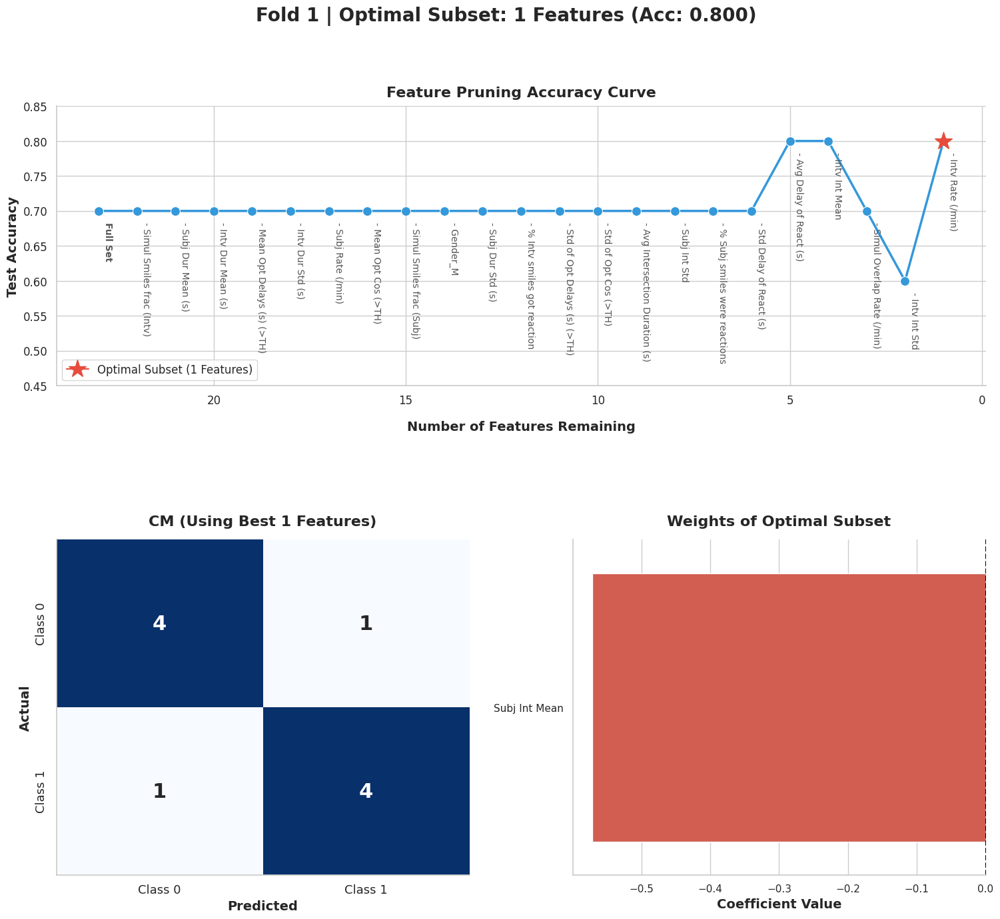

Processing Fold 2/7...


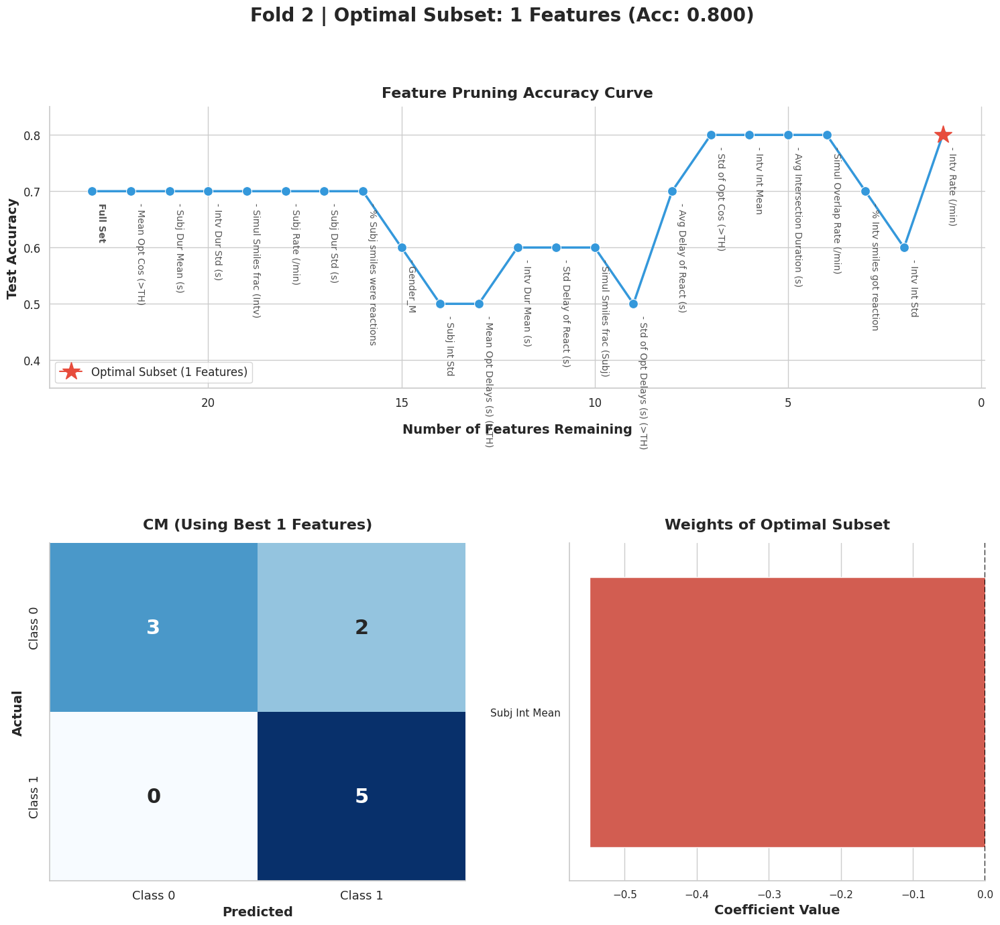

Processing Fold 3/7...


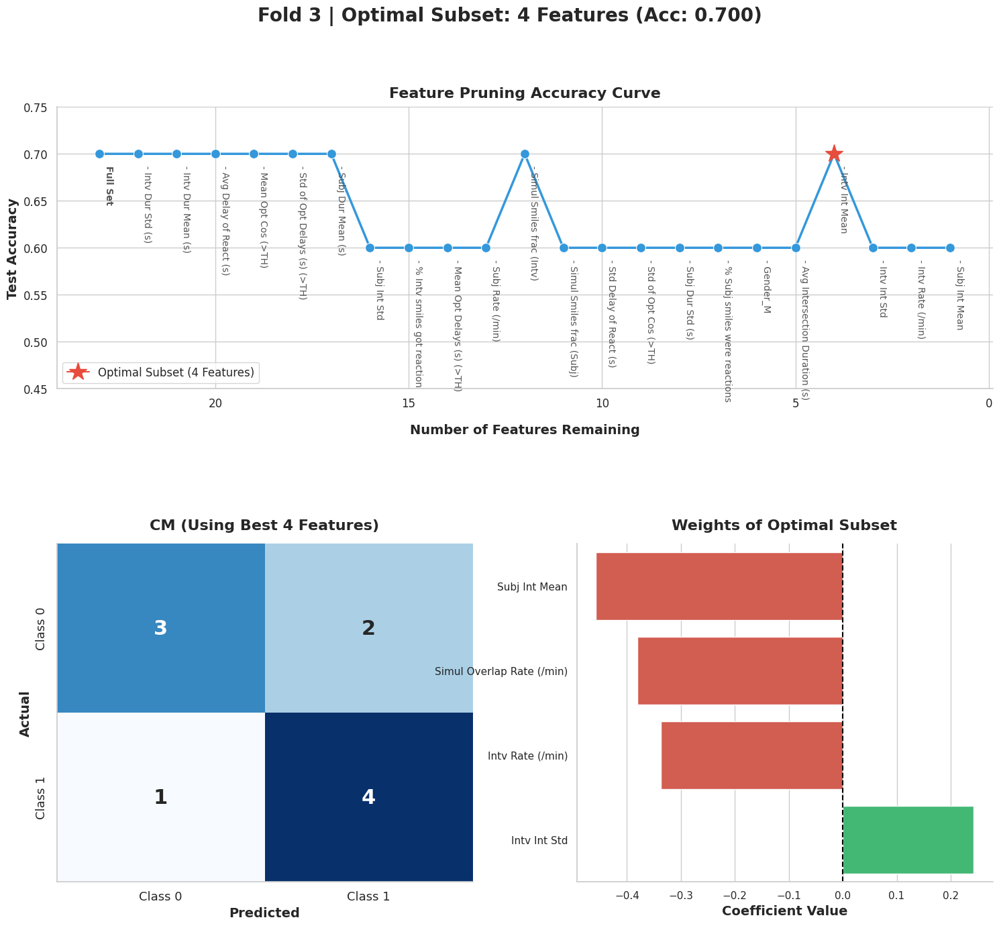

Processing Fold 4/7...


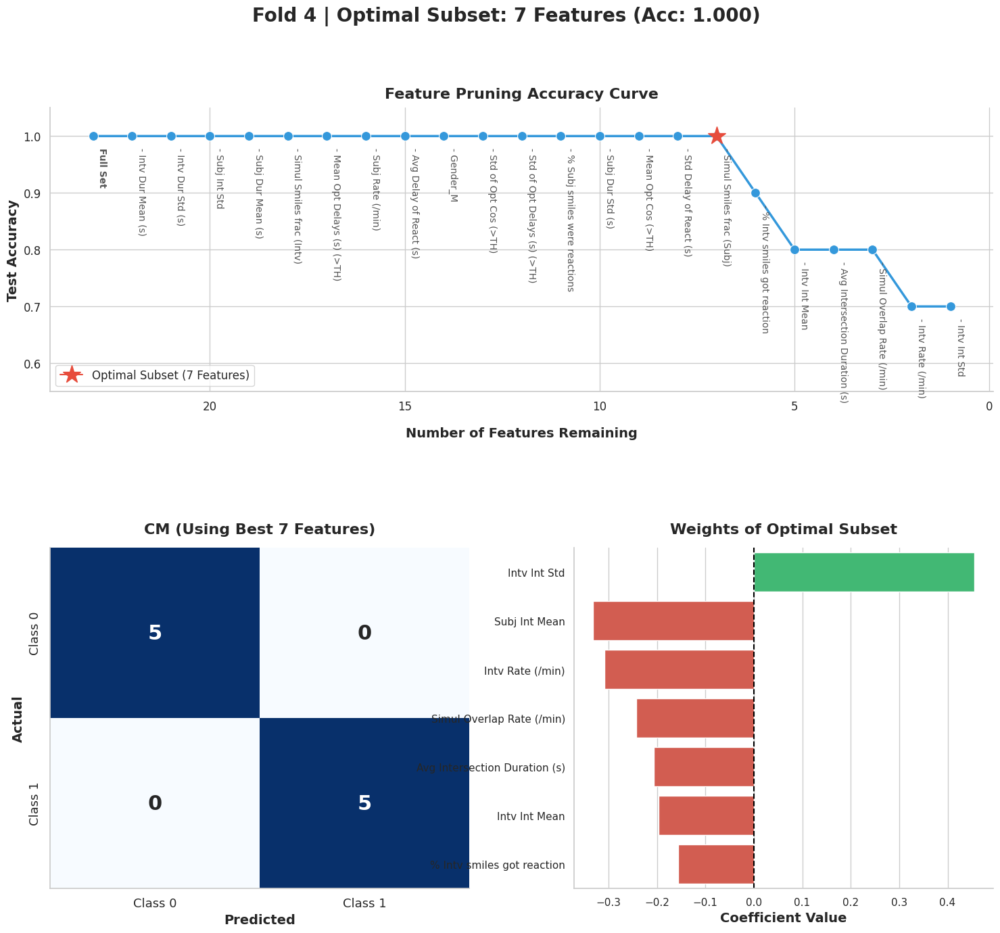

Processing Fold 5/7...


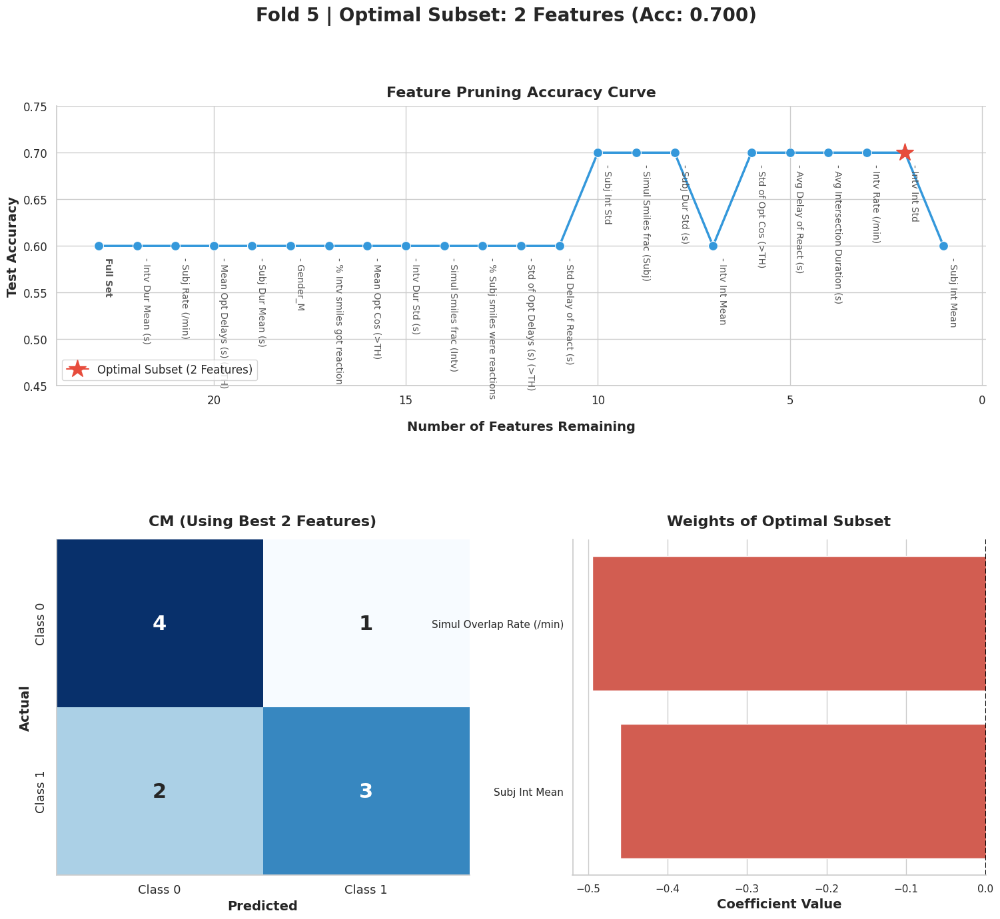

Processing Fold 6/7...


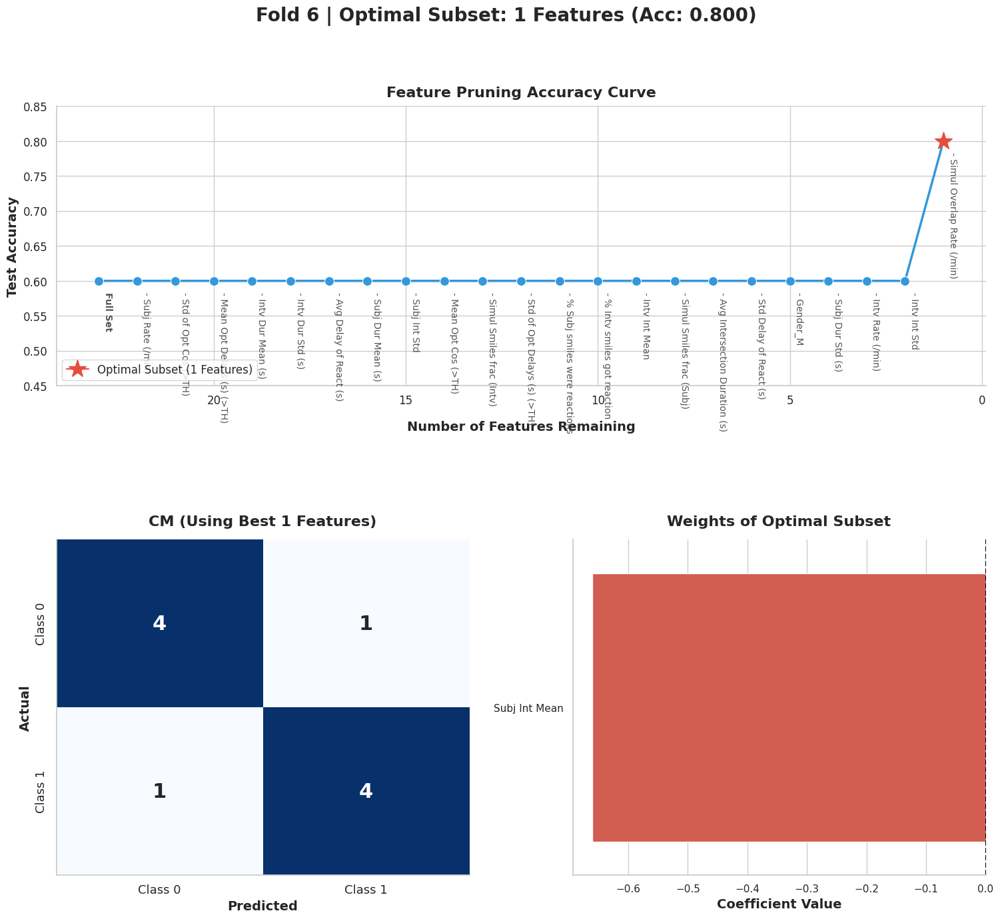

Processing Fold 7/7...


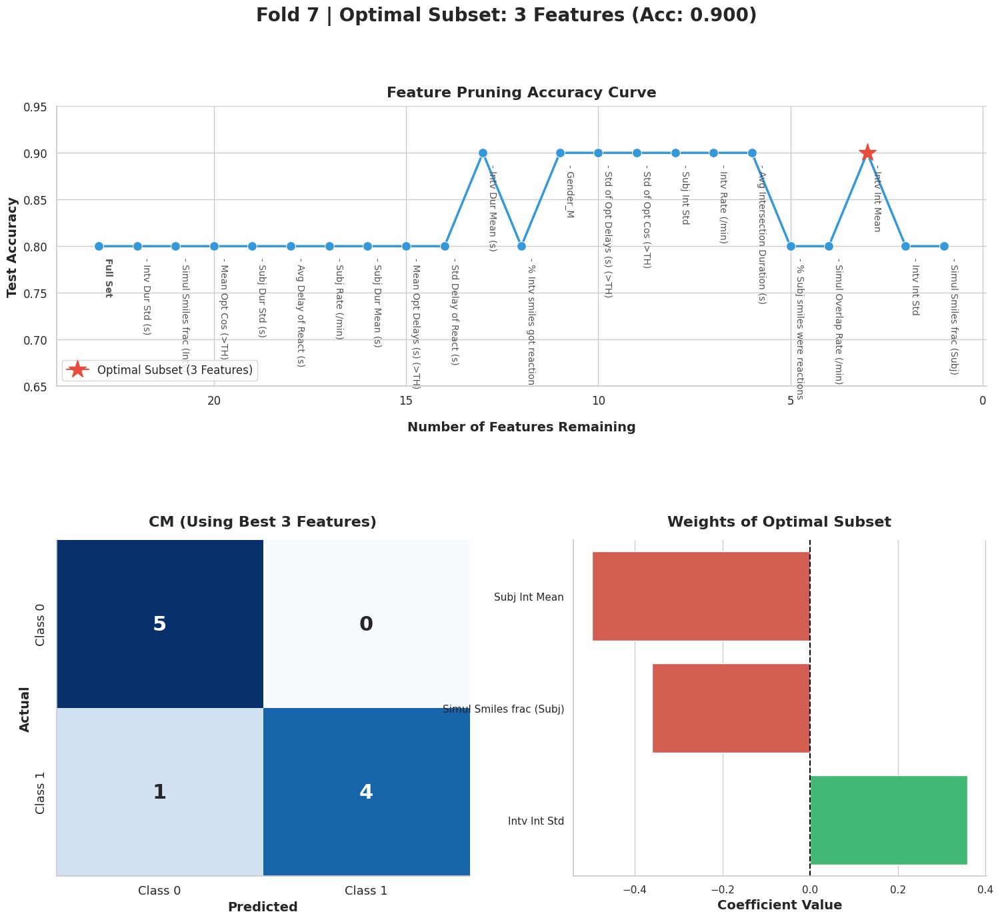

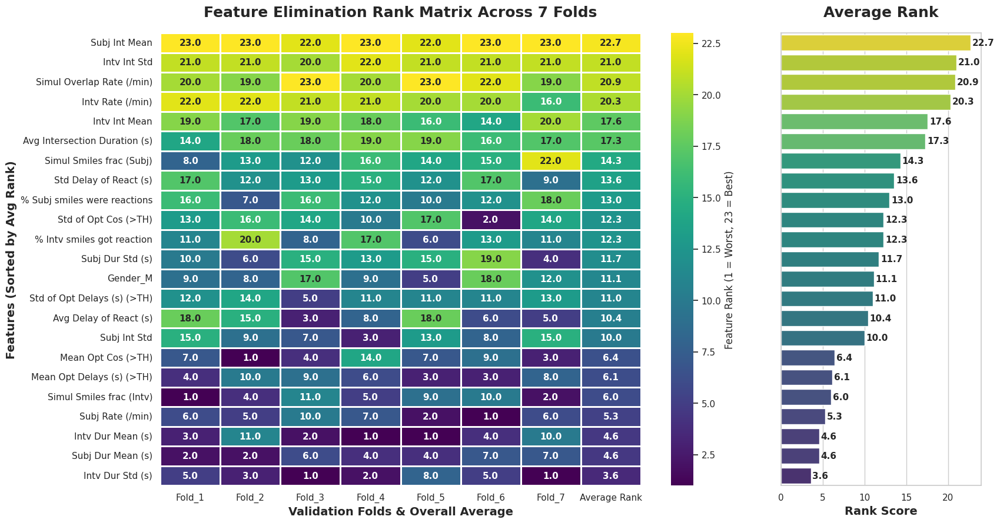

In [15]:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH): 
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        fold_best_features, rank_df = evaluate_kfold_pruning(X=X_scaled, y=y, K_FOLDS=7, C_value=1/10)
    else:
        print(f"File not found: {DATA_PATH}")

In [16]:
fold_best_features

{'Fold_1': ['Subject Smile Intensity Mean'],
 'Fold_2': ['Subject Smile Intensity Mean'],
 'Fold_3': ['Interviewer Smile Rate (per min)',
  'Interviewer Smile Intensity Std',
  'Subject Smile Intensity Mean',
  'Simultaneous Smiles (Intersections) Rate (per min)'],
 'Fold_4': ['Interviewer Smile Rate (per min)',
  'Interviewer Smile Intensity Mean',
  'Interviewer Smile Intensity Std',
  'Subject Smile Intensity Mean',
  'Simultaneous Smiles (Intersections) Rate (per min)',
  'Average Intersection Duration (s)',
  "% of Interviewer's smiles that got a reaction"],
 'Fold_5': ['Subject Smile Intensity Mean',
  'Simultaneous Smiles (Intersections) Rate (per min)'],
 'Fold_6': ['Subject Smile Intensity Mean'],
 'Fold_7': ['Interviewer Smile Intensity Std',
  'Subject Smile Intensity Mean',
  'Simultaneous Smiles fraction (Subject)']}

In [17]:
def evaluate_elected_features_loocv(X, y, elected_features_dict, use_l1=True, C_value=1.0, max_iter=10000, random_state=42):
    """
    Evaluates each set of elected features using Leave-One-Out Cross-Validation (LOOCV).
    Plots a grid where each elected subset gets its own sub-figure showing all metrics.
    """

    if C_value == 0 or C_value is None:
        model_params = {
            'penalty': None,
            'solver': 'saga',
            'max_iter': max_iter,
            'random_state': random_state
        }
        penalty_display = "None"
    else:
        model_params = {
            'penalty': 'elasticnet',
            'l1_ratio': 1.0 if use_l1 else 0.0,
            'C': C_value,
            'solver': 'saga',
            'max_iter': max_iter,
            'random_state': random_state
        }
        penalty_display = "L1" if use_l1 else "L2"

    total_samples = len(X)
    print(f"\n{'='*80}")
    print(f"EVALUATING FEATURE SETS USING LEAVE-ONE-OUT (Train: {total_samples - 1}, Test: 1)")
    print(f"Regularization: {penalty_display} | C-Value: {C_value}")
    print(f"{'='*80}\n")
    
    log_reg = LogisticRegression(**model_params)
    loo = LeaveOneOut()
    
    results = []
    
    for fold_name, features in elected_features_dict.items():
        X_subset = X[features]
        
        y_true_all = []
        y_pred_all = []
        
        # The LOOCV Loop
        for train_index, test_index in loo.split(X_subset):
            X_tr, X_te = X_subset.iloc[train_index], X_subset.iloc[test_index]
            y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
            
            log_reg.fit(X_tr, y_tr)
            pred = log_reg.predict(X_te)[0]
            
            y_true_all.append(y_te.values[0])
            y_pred_all.append(pred)
            
        acc = accuracy_score(y_true_all, y_pred_all)
        prec = precision_score(y_true_all, y_pred_all, zero_division=0)
        rec = recall_score(y_true_all, y_pred_all, zero_division=0)
        f1 = f1_score(y_true_all, y_pred_all, zero_division=0)
        
        # Abbreviate and wrap the feature names for plotting
        short_feats = [abbreviate_feature_name(f) for f in features]
        feat_string = ", ".join(short_feats)
        wrapped_labels = textwrap.fill(feat_string, width=45) # Wrapped for sub-figure titles
        
        results.append({
            'Source': fold_name,
            'Features_Display': wrapped_labels, 
            'Num_Features': len(features),
            'LOO_Accuracy': acc,
            'LOO_Precision': prec,
            'LOO_Recall': rec,
            'LOO_F1_Score': f1
        })
        
    results_df = pd.DataFrame(results)
    
    # Sort by Accuracy, then F1 so the best sets appear first in the grid
    results_df = results_df.sort_values(by=['LOO_Accuracy', 'LOO_F1_Score'], ascending=False).reset_index(drop=True)
    
    # Print tabular summary
    print(results_df[['Source', 'Num_Features', 'LOO_Accuracy', 'LOO_Precision', 'LOO_Recall', 'LOO_F1_Score']].to_string(index=False))
    
    # --- Visualization: Sub-figure per Elected Feature Set ---
    sns.set_theme(style="whitegrid", palette="muted")
    
    num_plots = len(results_df)
    cols = 3
    rows = int(np.ceil(num_plots / cols))
    
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 6 * rows))
    fig.suptitle('LOOCV Performance Profile by Elected Feature Set', fontsize=22, fontweight='bold', y=1.02)
    
    axes_flat = axes.flatten() if num_plots > 1 else [axes]
    
    # Iterate through the results and plot each as a separate bar chart
    for i, row in results_df.iterrows():
        ax = axes_flat[i]
        
        # Prepare the 4 metrics for this specific feature set
        plot_data = pd.DataFrame({
            'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
            'Score': [row['LOO_Accuracy'], row['LOO_Precision'], row['LOO_Recall'], row['LOO_F1_Score']]
        })
        
        # Plot
        # NOTE: If you are using Seaborn 0.14+, 'palette' requires 'hue'. 
        # I added hue='Metric' and legend=False to future-proof it.
        sns.barplot(x='Metric', y='Score', data=plot_data, ax=ax, hue='Metric', palette='mako', legend=False)
        
        # Formatting
        ax.set_ylim(0, 1.15) # Leave room for the labels on top of the bars
        ax.set_ylabel('Score', fontsize=12, fontweight='bold')
        ax.set_xlabel('')
        ax.tick_params(axis='x', labelsize=11, labelrotation=15)
        
        # Set a rich, descriptive title for the subplot
        title_text = f"{row['Source']} | {row['Num_Features']} Features\n{row['Features_Display']}"
        ax.set_title(title_text, fontsize=12, fontweight='bold', color='#2c3e50', pad=12)
        
        # Add numeric labels to bars
        for container in ax.containers:
            ax.bar_label(container, fmt='%.3f', padding=4, size=11, weight='bold')
            
    # Remove any empty subplots if the number of sets doesn't divide evenly by 3
    for j in range(i + 1, len(axes_flat)):
        fig.delaxes(axes_flat[j])

    sns.despine()
    plt.tight_layout()
    plt.show()
    
    return results_df

Preparing data...
Preparation complete: 70 subjects processed.

EVALUATING FEATURE SETS USING LEAVE-ONE-OUT (Train: 69, Test: 1)
Regularization: L2 | C-Value: 0.1



/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/amir/Ados_lab/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To 

Source  Num_Features  LOO_Accuracy  LOO_Precision  LOO_Recall  LOO_F1_Score
Fold_3             4      0.785714       0.763158    0.828571      0.794521
Fold_1             1      0.742857       0.717949    0.800000      0.756757
Fold_2             1      0.742857       0.717949    0.800000      0.756757
Fold_6             1      0.742857       0.717949    0.800000      0.756757
Fold_4             7      0.728571       0.750000    0.685714      0.716418
Fold_5             2      0.714286       0.714286    0.714286      0.714286
Fold_7             3      0.685714       0.666667    0.742857      0.702703


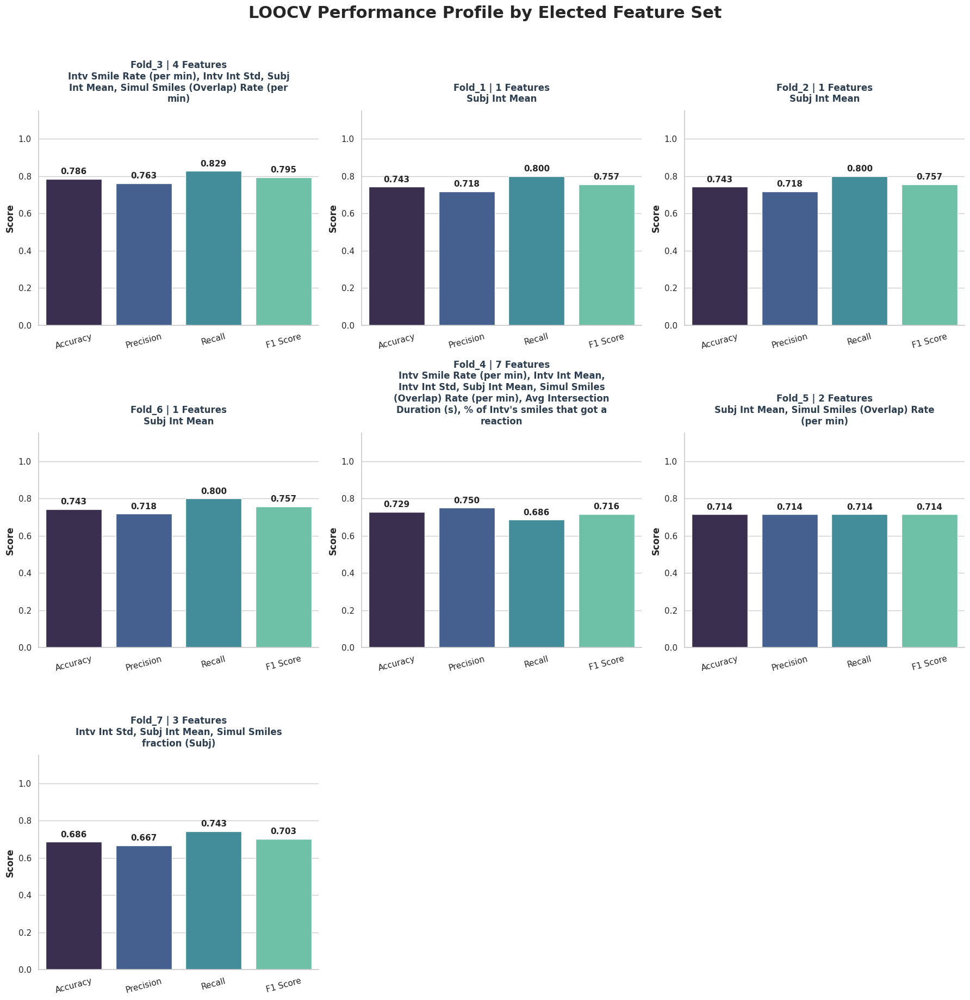

In [18]:
if __name__ == "__main__":
    if os.path.exists(DATA_PATH): 
        df = pd.read_csv(DATA_PATH)
        X_scaled, y = prepare_data(df)
        final_results_df = evaluate_elected_features_loocv(X=X_scaled, y=y, use_l1=False,C_value=1/10, elected_features_dict=fold_best_features)

In [19]:
all_best_festures_set = set()
for i in range(1, 8):
    all_best_festures_set = all_best_festures_set.union(fold_best_features[f'Fold_{i}'])

In [20]:
all_best_festures_set

{"% of Interviewer's smiles that got a reaction",
 'Average Intersection Duration (s)',
 'Interviewer Smile Intensity Mean',
 'Interviewer Smile Intensity Std',
 'Interviewer Smile Rate (per min)',
 'Simultaneous Smiles (Intersections) Rate (per min)',
 'Simultaneous Smiles fraction (Subject)',
 'Subject Smile Intensity Mean'}

In [7]:

def abbreviate_feature_name(name):
    """Shortens long feature names so they don't overlap on the plot axis."""
    replacements = {
        "Interviewer": "Intv", "Subject": "Subj", "Smile Duration": "Dur",
        "Smile Intensity": "Int", "Average": "Avg", "Simultaneous": "Simul",
        "Intersections": "Overlap", "Reactions": "React", "Reaction": "React"
    }
    for old, new in replacements.items():
        name = name.replace(old, new)
    return name

# =============================================================================
# Dashboard Plotting Function for Each Outer Iteration
# =============================================================================
def plot_consensus_elimination_step(rank_df, df_inner_metrics, dropped_feature_display, iteration, total_features):
    """
    Plots the Rank Matrix, Average Rank Bar Chart, and Inner-Pruning Metric Trends per fold.
    Handles overlapping lines via jitter, unique markers, and diverse linestyles.
    """
    sns.set_theme(style="whitegrid")
    
    # Dynamic figure height based on the number of features, plus fixed room for the bottom metrics row and legend
    fig_height = max(14, (total_features * 0.5) + 7)
    
    fig = plt.figure(figsize=(18, fig_height))
    gs = fig.add_gridspec(2, 4, height_ratios=[2.5, 1.5], wspace=0.3, hspace=0.4)
    
    ax_heatmap = fig.add_subplot(gs[0, 0:3]) 
    ax_bar = fig.add_subplot(gs[0, 3])       
    
    ax_acc = fig.add_subplot(gs[1, 0])
    ax_f1 = fig.add_subplot(gs[1, 1])
    ax_prec = fig.add_subplot(gs[1, 2])
    ax_rec = fig.add_subplot(gs[1, 3])
    
    metric_axes = {'Accuracy': ax_acc, 'F1-Score': ax_f1, 'Precision': ax_prec, 'Recall': ax_rec}
    
    # ---------------------------------------------------------
    # 1. Top-Left Subplot: The Rank Matrix (Heatmap)
    # ---------------------------------------------------------
    heatmap_data = rank_df.drop(columns=['Average Rank'])
    sns.heatmap(heatmap_data, annot=True, fmt=".1f", cmap="viridis", 
                cbar_kws={'label': 'Survival Rank (1 = Eliminated First)'},
                linewidths=1, ax=ax_heatmap, annot_kws={"size": 11, "weight": "bold"})
    
    ax_heatmap.set_title(f'Iteration {iteration}: Survival Rank Matrix Across Folds', 
                         fontsize=16, fontweight='bold', pad=15)
    ax_heatmap.set_ylabel('Features (Sorted by Avg Rank)', fontsize=13, fontweight='bold')
    ax_heatmap.set_xlabel('Validation Folds', fontsize=13, fontweight='bold')
    ax_heatmap.tick_params(axis='y', rotation=0, labelsize=11)
    
    # ---------------------------------------------------------
    # 2. Top-Right Subplot: Average Rank (Bar Chart)
    # ---------------------------------------------------------
    avg_ranks = rank_df['Average Rank'].values
    features = rank_df.index
    
    colors = ['#e74c3c' if feat == dropped_feature_display else '#3498db' for feat in features]
    
    sns.barplot(x=avg_ranks, y=features, ax=ax_bar, palette=colors, hue=features, legend=False)
    
    ax_bar.set_title(f'Average Rank\nEliminating: {dropped_feature_display}', 
                     fontsize=15, fontweight='bold', color='#e74c3c', pad=15)
    ax_bar.set_xlabel('Average Score', fontsize=13, fontweight='bold')
    ax_bar.set_xlim(0, total_features + 1) 
    
    ax_bar.set_ylabel('')
    ax_bar.tick_params(axis='y', labelleft=False, left=False)
    ax_bar.grid(axis='y', visible=False)
    
    for i, val in enumerate(avg_ranks):
        is_dropped = (features[i] == dropped_feature_display)
        fw = 'bold' if is_dropped else 'normal'
        c = '#e74c3c' if is_dropped else 'black'
        ax_bar.text(val + 0.1, i, f'{val:.2f}', va='center', fontsize=11, fontweight=fw, color=c)

    # ---------------------------------------------------------
    # 3. Bottom Subplots: Inner-Pruning Metrics Per Fold
    # ---------------------------------------------------------
    unique_feature_counts = sorted(df_inner_metrics['Num_Features'].unique(), reverse=True)
    
    # Sort folds properly (F1, F2, F3...)
    unique_folds = sorted(df_inner_metrics['Fold'].unique(), key=lambda x: int(x[1:]))
    x_base = np.arange(len(unique_folds))
    
    # Visual Differentiation Tools
    # 1. Distinct Colors (husl generates highly separated colors)
    palette = sns.color_palette("husl", n_colors=len(unique_feature_counts))
    # 2. Cycle through distinct markers and line styles
    marker_cycle = itertools.cycle(['o', 's', '^', 'D', 'v', 'p', '*', 'X'])
    linestyle_cycle = itertools.cycle(['-', '--', '-.', ':'])
    # 3. Calculate a tiny jitter offset for the X-axis to prevent total overlap
    # If there are many lines, spread them between -0.15 and +0.15 on the X axis
    jitter_offsets = np.linspace(-0.15, 0.15, len(unique_feature_counts))
    
    legend_handles = []
    
    for idx, nf in enumerate(unique_feature_counts):
        color = palette[idx]
        marker = next(marker_cycle)
        linestyle = next(linestyle_cycle)
        offset = jitter_offsets[idx]
        
        # Save handle for the global legend
        legend_handles.append(
            plt.Line2D([0], [0], color=color, lw=2.5, linestyle=linestyle, marker=marker, markersize=8, label=f"{nf} Features")
        )
        
        for metric_name, ax in metric_axes.items():
            # Filter data for this specific feature count
            df_subset = df_inner_metrics[df_inner_metrics['Num_Features'] == nf].copy()
            # Ensure it is sorted by fold
            df_subset['Fold_Num'] = df_subset['Fold'].str.replace('F', '').astype(int)
            df_subset = df_subset.sort_values('Fold_Num')
            
            y_values = df_subset[metric_name].values
            x_jittered = x_base + offset
            
            # Plot manually to apply jitter, distinct markers, and distinct linestyles
            ax.plot(x_jittered, y_values, color=color, marker=marker, linestyle=linestyle, 
                    linewidth=2.5, markersize=7, alpha=0.85)

    # Format the bottom axes
    for metric_name, ax in metric_axes.items():
        ax.set_title(f"{metric_name} during Pruning", fontsize=13, fontweight='bold')
        ax.set_xticks(x_base)
        ax.set_xticklabels(unique_folds, fontweight='bold')
        ax.set_xlabel("")
        ax.set_ylabel("")
        
        min_val = df_inner_metrics[metric_name].min()
        max_val = df_inner_metrics[metric_name].max()
        ax.set_ylim(max(0.0, min_val - 0.05), min(1.0, max_val + 0.05))

    # ---------------------------------------------------------
    # 4. Global Legend (Placed outside subplots)
    # ---------------------------------------------------------
    fig.legend(handles=legend_handles, 
               title="Inner Pruning Level (# of Features Remaining)", 
               loc='lower center', 
               bbox_to_anchor=(0.5, 0.01), 
               ncol=min(10, len(unique_feature_counts)), # Spread legend horizontally
               fontsize=10, 
               title_fontsize=12,
               frameon=True,
               edgecolor='black')

    fig.suptitle(f"Inner-Fold Performance Metrics (Iteration {iteration})", fontsize=18, fontweight='bold', y=0.98)
    
    sns.despine()
    # Use rect to compress the plots upward, leaving 8% of the bottom space strictly for the legend
    plt.tight_layout(rect=[0, 0.08, 1, 1]) 
    plt.show()

# =============================================================================
# Global Consensus Recursive Feature Elimination
# =============================================================================
def consensus_global_rfe(X, y, initial_features, K_FOLDS=7, C_value=1.0, max_iter=10000):
    # Setup LogReg Params
    if C_value == 0 or C_value is None:
        model_params = {'C': np.inf, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}
    else:
        model_params = {'C': C_value, 'solver': 'saga', 'max_iter': max_iter, 'random_state': 42}

    current_features = list(initial_features)
    iteration = 1
    elimination_history = []
    
    print(f"\n{'='*80}")
    print(f"STARTING CONSENSUS GLOBAL RFE ({len(current_features)} Initial Features)")
    print(f"{'='*80}\n")
    
    while len(current_features) > 1:
        num_feats_this_round = len(current_features)
        print(f"--- Iteration {iteration} | Evaluating {num_feats_this_round} Features ---")
        
        skf = StratifiedKFold(n_splits=K_FOLDS, shuffle=True, random_state=42)
        log_reg = LogisticRegression(**model_params)
        
        feature_ranks = {feat: {} for feat in current_features}
        
        # NEW: List to track the metrics at EVERY pruning step inside the fold
        inner_metrics_records = []
        
        # 1. Run K-Fold
        for fold, (train_index, test_index) in enumerate(skf.split(X, y), start=1):
            X_tr, X_te = X.iloc[train_index], X.iloc[test_index]
            y_tr, y_te = y.iloc[train_index], y.iloc[test_index]
            
            # --- RFE INNER LOOP ---
            inner_features = list(current_features)
            while len(inner_features) > 0:
                # A. Train and evaluate the model at THIS specific pruning step
                log_reg.fit(X_tr[inner_features], y_tr)
                y_pred = log_reg.predict(X_te[inner_features])
                
                # B. Record metrics
                inner_metrics_records.append({
                    'Fold': f"F{fold}",
                    'Num_Features': len(inner_features),
                    'Accuracy': accuracy_score(y_te, y_pred),
                    'F1-Score': f1_score(y_te, y_pred, average='weighted', zero_division=0),
                    'Precision': precision_score(y_te, y_pred, average='weighted', zero_division=0),
                    'Recall': recall_score(y_te, y_pred, average='weighted', zero_division=0)
                })
                
                # C. Identify the weakest coefficient to drop next
                coefs = np.abs(log_reg.coef_[0])
                weakest_idx = np.argmin(coefs)
                weakest_feat = inner_features[weakest_idx]
                
                # D. Calculate Survival Rank (1 = First Eliminated/Worst)
                current_rank = num_feats_this_round - len(inner_features) + 1
                feature_ranks[weakest_feat][f"Fold_{fold}"] = current_rank
                
                # E. Remove feature and repeat loop
                inner_features.remove(weakest_feat)
                
        # 2. Convert all the inner metrics to a DataFrame
        df_inner_metrics = pd.DataFrame(inner_metrics_records)
                
        # 3. Build the Rank Matrix and Calculate Averages
        rank_df = pd.DataFrame(feature_ranks).T
        rank_df['Average Rank'] = rank_df.mean(axis=1)
        
        # Sort so Best (Highest Avg Rank) is at the top, Worst is at the bottom
        rank_df = rank_df.sort_values(by='Average Rank', ascending=False)
        
        # 4. Identify the feature to throw away (Lowest average rank)
        feature_to_drop = rank_df.index[-1]
        
        # 5. Format Dataframe for Plotting
        plot_df = rank_df.copy()
        plot_df.index = [abbreviate_feature_name(idx) for idx in plot_df.index]
        dropped_display_name = abbreviate_feature_name(feature_to_drop)
        
        # 6. Plot the Dashboard (Pass the df_inner_metrics)
        plot_consensus_elimination_step(plot_df, df_inner_metrics, dropped_display_name, iteration, num_feats_this_round)
        
        # 7. Execute the Elimination
        print(f"> Eliminating weakest feature: {feature_to_drop} (Avg Rank: {rank_df['Average Rank'].iloc[-1]:.2f})\n")
        current_features.remove(feature_to_drop)
        
        # Extract the 'full feature' baseline accuracy for the history log
        base_acc = df_inner_metrics[df_inner_metrics['Num_Features'] == num_feats_this_round]['Accuracy'].mean()
        
        elimination_history.append({
            'Iteration': iteration,
            'Dropped_Feature': feature_to_drop,
            'Avg_Rank_At_Drop': rank_df['Average Rank'].iloc[-1],
            'Baseline_Acc': base_acc
        })
        
        iteration += 1

    print(f"{'='*80}")
    print(f"RFE COMPLETE. FINAL SURVIVING FEATURE: {current_features[0]}")
    print(f"{'='*80}")
    
    return current_features[0], elimination_history

Total unique features passed to Consensus RFE: 8

STARTING CONSENSUS GLOBAL RFE (8 Initial Features)

--- Iteration 1 | Evaluating 8 Features ---


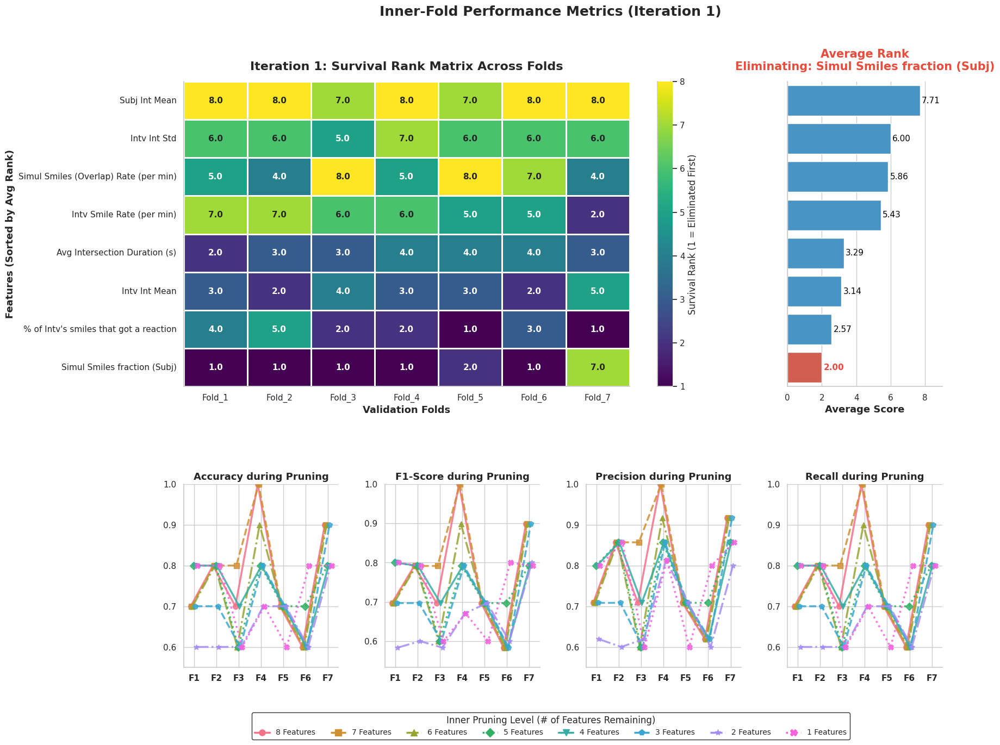

> Eliminating weakest feature: Simultaneous Smiles fraction (Subject) (Avg Rank: 2.00)

--- Iteration 2 | Evaluating 7 Features ---


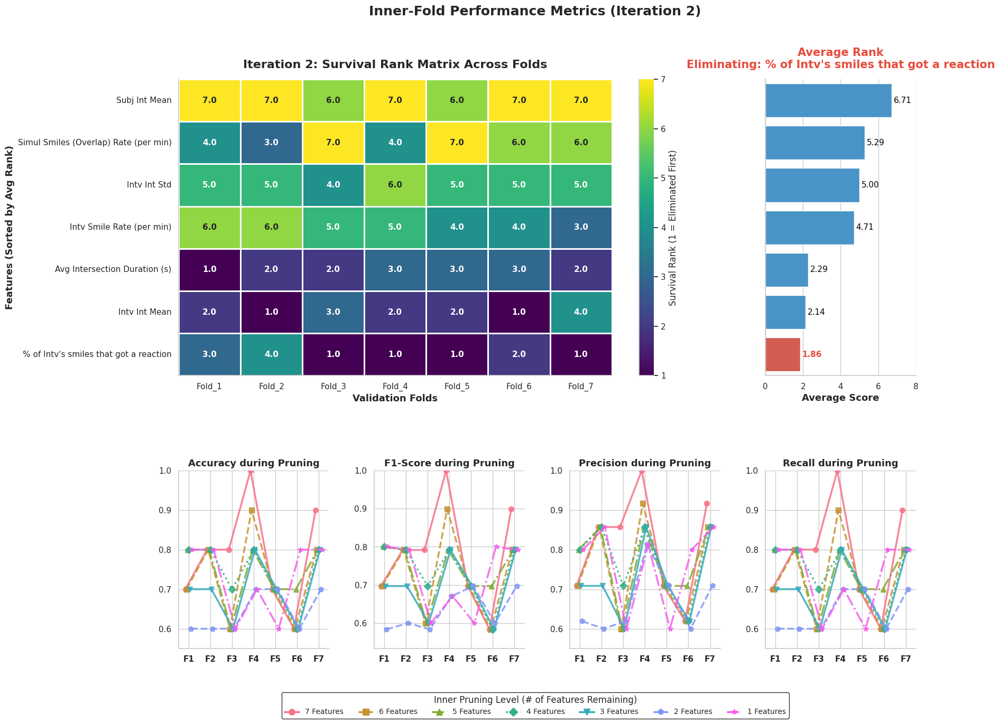

> Eliminating weakest feature: % of Interviewer's smiles that got a reaction (Avg Rank: 1.86)

--- Iteration 3 | Evaluating 6 Features ---


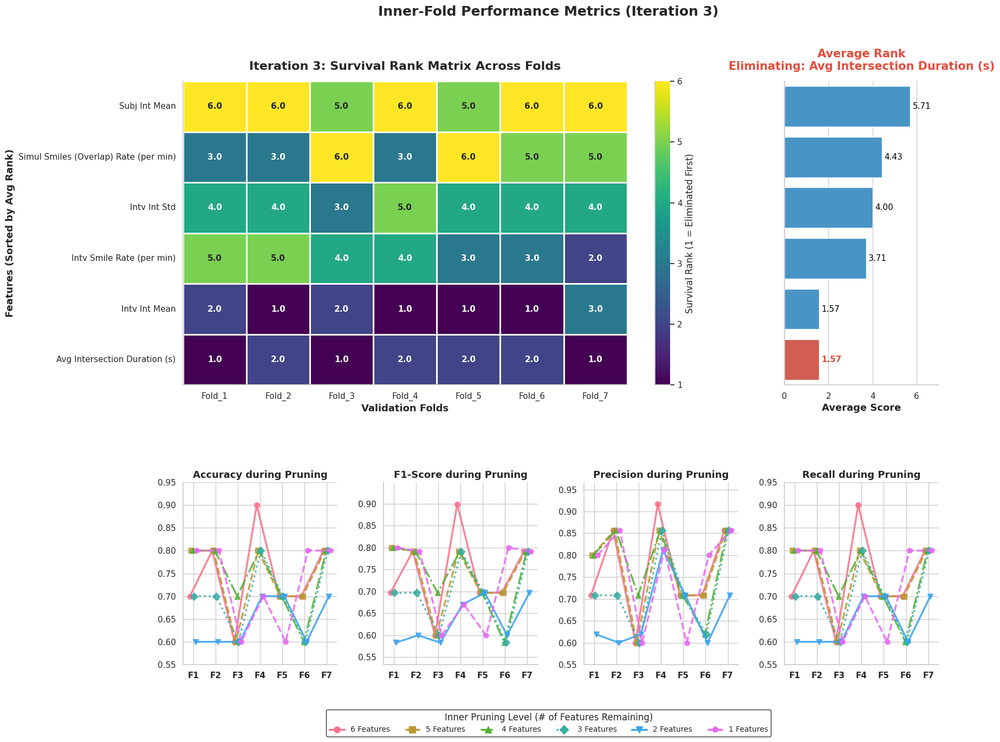

> Eliminating weakest feature: Average Intersection Duration (s) (Avg Rank: 1.57)

--- Iteration 4 | Evaluating 5 Features ---


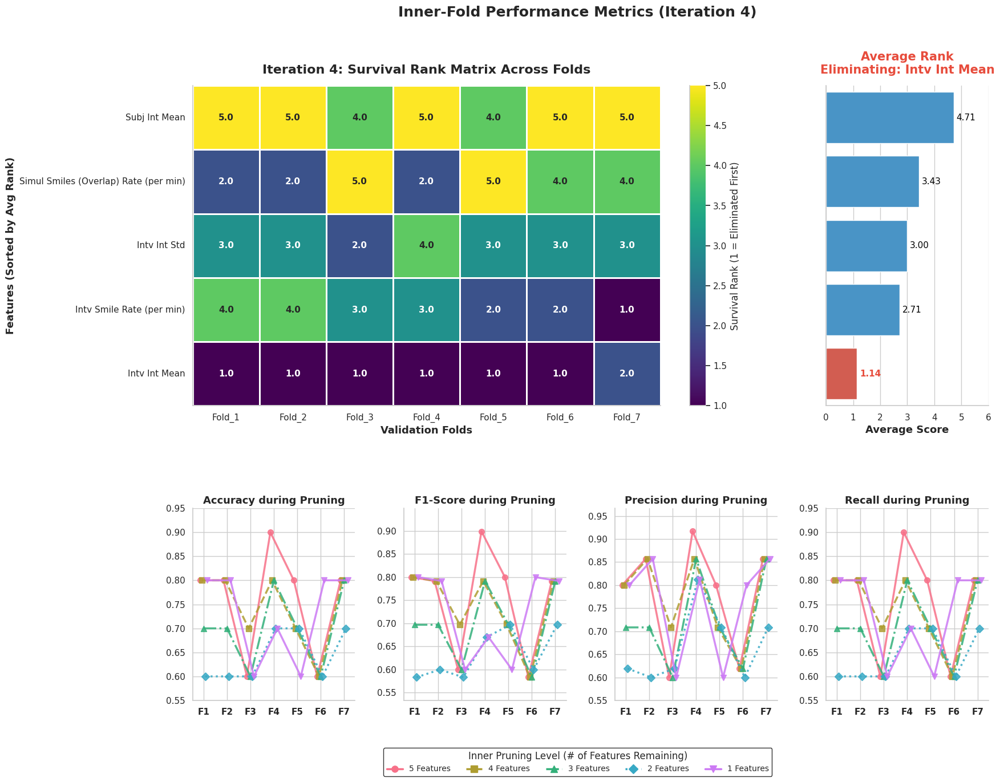

> Eliminating weakest feature: Interviewer Smile Intensity Mean (Avg Rank: 1.14)

--- Iteration 5 | Evaluating 4 Features ---


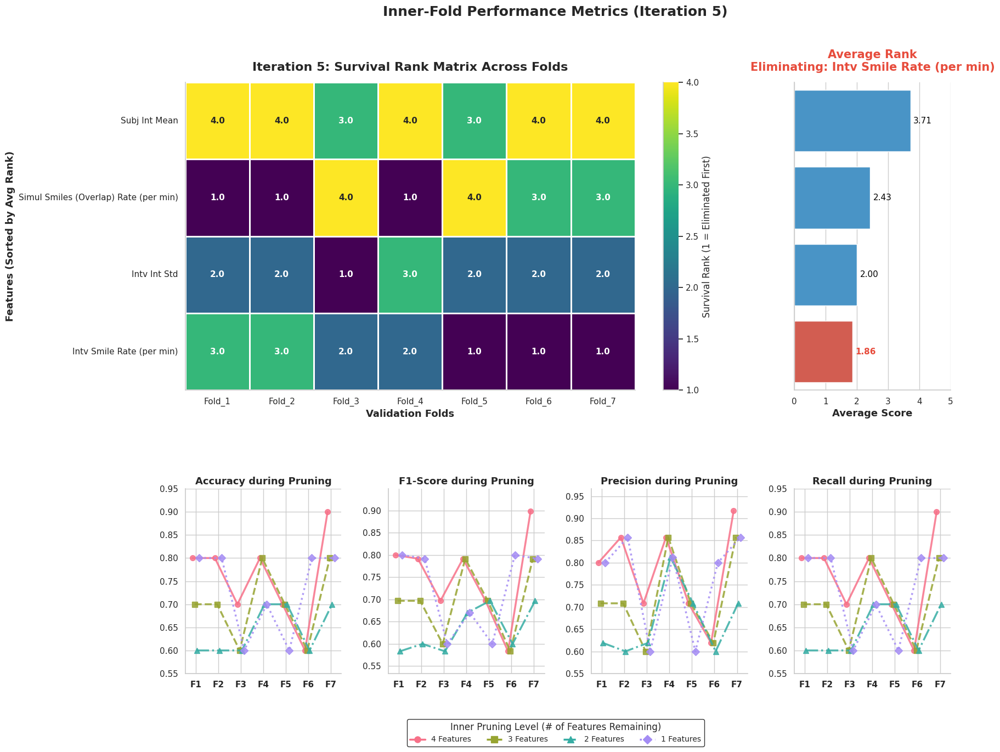

> Eliminating weakest feature: Interviewer Smile Rate (per min) (Avg Rank: 1.86)

--- Iteration 6 | Evaluating 3 Features ---


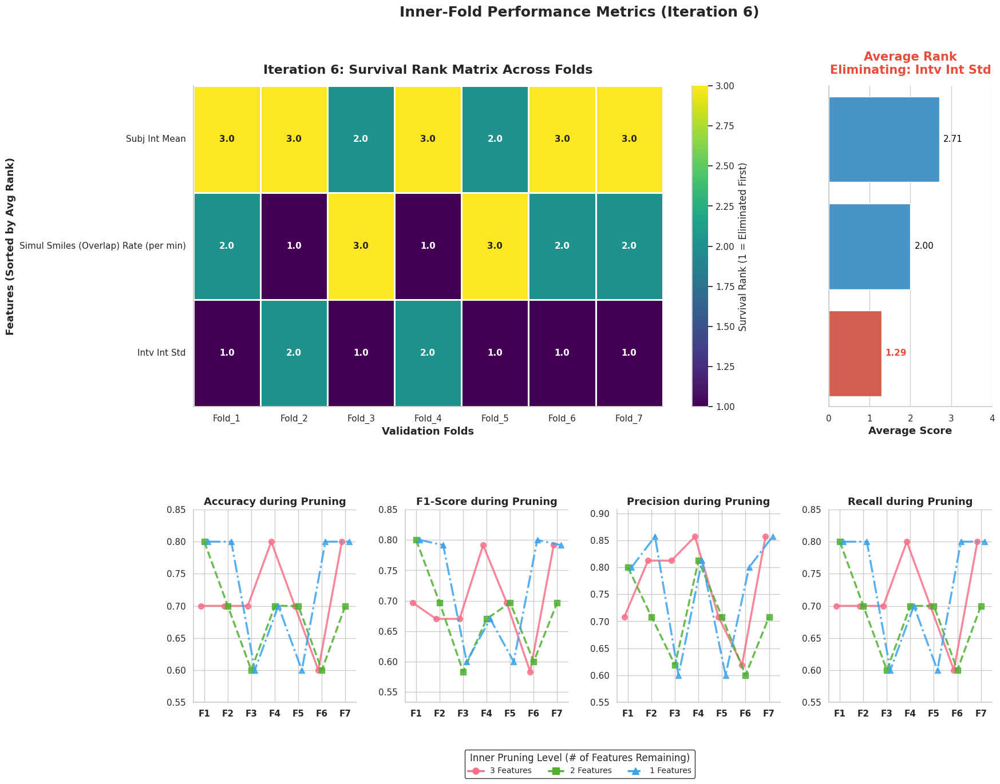

> Eliminating weakest feature: Interviewer Smile Intensity Std (Avg Rank: 1.29)

--- Iteration 7 | Evaluating 2 Features ---


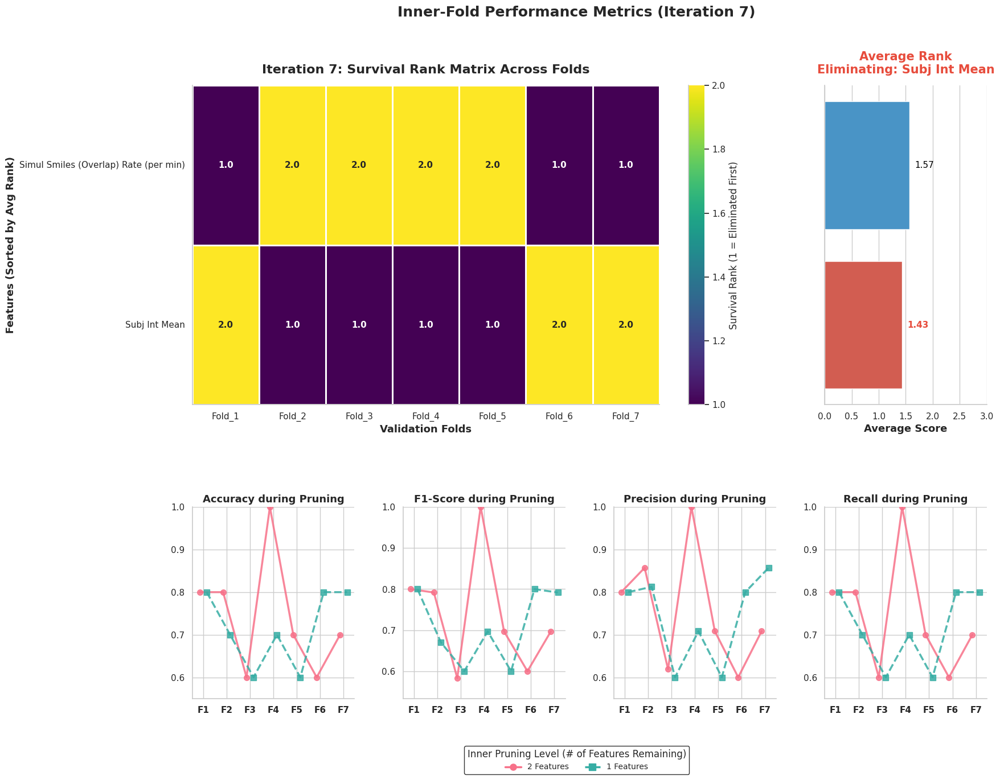

> Eliminating weakest feature: Subject Smile Intensity Mean (Avg Rank: 1.43)

RFE COMPLETE. FINAL SURVIVING FEATURE: Simultaneous Smiles (Intersections) Rate (per min)


In [22]:
if __name__ == "__main__":
    # Assuming X_scaled and y are already prepared and loaded...
    # fold_best_features is a dictionary resulting from your previous evaluation step
    
    # 1. Take the union of all best features identified in the previous folds
    all_best_features_set = set()
    for i in range(1, 8):
        # Make sure the key matches exactly how you stored it (e.g. 'Fold_1')
        all_best_features_set = all_best_features_set.union(fold_best_features[f'Fold_{i}'])
        
    initial_features_list = list(all_best_features_set)
    print(f"Total unique features passed to Consensus RFE: {len(initial_features_list)}")
    
    # 2. Run the consensus elimination process
    final_feature, history = consensus_global_rfe(
        X=X_scaled, 
        y=y, 
        initial_features=initial_features_list, 
        K_FOLDS=7, 
        C_value=1/10
    )

In [ ]:


df_merged = pd.read_csv(DATA_PATH)

# Explicitly define your metadata so the script knows what NOT to plot
metadata_cols = ['Subject Number', 'Label', 'Gender']

# Automatically grab the remaining behavioral features
feature_cols = [col for col in df_merged.columns if col not in metadata_cols]

col_delay = "Average Delay of Reaction (s)"
col_std = "Std Dev of Delay of Reaction (s)"

if col_delay in df_merged.columns:
    df_merged[col_delay] = df_merged[col_delay].fillna(2.0)
    print(f"Applied 2.0s penalty to {col_delay}")

if col_std in df_merged.columns:
    df_merged[col_std] = df_merged[col_std].fillna(0.0)
    print(f"Applied 0.0 penalty to {col_std}")

# --- NORMALIZE THE FEATURES ---
scaler = StandardScaler()
df_scaled = df_merged.copy()
df_scaled[feature_cols] = scaler.fit_transform(df_merged[feature_cols])

OUTPUT_DIR = '/home/amir/Ados_lab/videos2/results/pairwise_feature_plots'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print(f"Successfully loaded and normalized data for {len(df_scaled)} subjects.")
print(f"Detected {len(feature_cols)} behavioral features.")
print(f"Generating {len(feature_cols) * (len(feature_cols) - 1) // 2} unique pairwise plots...")

# =============================================================================
# 2. Memory-Safe Loop over all 136 Combinations
# =============================================================================
sns.set_theme(style="whitegrid", palette="muted")
label_palette = sns.color_palette("Set1", n_colors=df_scaled['Label'].nunique())

pairwise_combinations = list(itertools.combinations(feature_cols, 2))

for idx, (x_feat, y_feat) in enumerate(pairwise_combinations, start=1):
    # Initialize a single figure
    fig, ax = plt.subplots(figsize=(10, 7))
    
    # --- ISOLATE VALID DATA ---
    valid_data = df_scaled[[x_feat, y_feat, 'Label']].dropna()
    
    if len(valid_data) > 5: # Need a minimum amount of data to meaningfully drop 5%
        X_val = valid_data[[x_feat]].values
        y_val = valid_data[y_feat].values
        
        # =====================================================================
        # 1. INITIAL FIT (Before pruning)
        # =====================================================================
        lr_initial = LinearRegression()
        lr_initial.fit(X_val, y_val)
        initial_preds = lr_initial.predict(X_val)
        initial_mse = mean_squared_error(y_val, initial_preds)
        
        # Calculate residuals and threshold
        residuals = np.abs(y_val - initial_preds)
        threshold_95th = np.percentile(residuals, 95)
        inlier_mask = residuals <= threshold_95th
        
        # Split data into clean (95%) and outliers (5%)
        clean_data = valid_data[inlier_mask]
        outlier_data = valid_data[~inlier_mask]
        
        X_clean = clean_data[[x_feat]].values
        y_clean = clean_data[y_feat].values
        
        # =====================================================================
        # 2. FINAL FIT (After pruning)
        # =====================================================================
        lr_final = LinearRegression()
        lr_final.fit(X_clean, y_clean)
        clean_preds = lr_final.predict(X_clean)
        clean_mse = mean_squared_error(y_clean, clean_preds)
        
        # Format MSE for filename sorting (using the cleaned MSE)
        mse_filename_str = f"{clean_mse:06.4f}" 
        
        # =====================================================================
        # PLOTTING ON SINGLE AXIS
        # =====================================================================
        
        # A. Plot Initial Line (Dashed, Gray)
        sns.regplot(
            data=valid_data, x=x_feat, y=y_feat, scatter=False, ax=ax, 
            color='gray', line_kws={'linestyle': '--', 'alpha': 0.6},
            label=f'Initial Line (MSE: {initial_mse:.4f})'
        )
        
        # B. Plot Cleaned Line (Solid, Black)
        sns.regplot(
            data=clean_data, x=x_feat, y=y_feat, scatter=False, ax=ax, 
            color='black', line_kws={'linestyle': '-', 'linewidth': 2.5, 'alpha': 0.9},
            label=f'Cleaned Line (MSE: {clean_mse:.4f})'
        )
        
        # C. Plot the 95% inliers (Colored by Label)
        sns.scatterplot(
            data=clean_data, x=x_feat, y=y_feat, hue='Label', 
            palette=label_palette, s=100, alpha=0.8, edgecolor='k', ax=ax
        )
        
        # D. Plot the 5% dropped outliers (Grey X markers)
        if not outlier_data.empty:
            sns.scatterplot(
                data=outlier_data, x=x_feat, y=y_feat, color='grey', marker='X',
                s=120, alpha=0.5, edgecolor='k', ax=ax, label='Dropped Outliers (5%)', legend=False
            )
            
        ax.set_title(f'Plot {idx}/136: {x_feat} vs {y_feat}\nComparing Initial vs. Pruned Fit', fontsize=14, fontweight='bold', pad=15)
        
    else:
        # Fallback for pairs without enough data
        mse_filename_str = "NaN"
        ax.set_title(f'Plot {idx}/136: {x_feat} vs {y_feat}\nInsufficient Data', fontweight='bold', pad=15)
        if not valid_data.empty:
            sns.scatterplot(data=valid_data, x=x_feat, y=y_feat, hue='Label', palette=label_palette, ax=ax, s=100, edgecolor='k')

    ax.set_xlabel(f"{x_feat} (Z-Score)", fontsize=11, fontweight='bold')
    ax.set_ylabel(f"{y_feat} (Z-Score)", fontsize=11, fontweight='bold')
    
    # Consolidate and position the legend beautifully outside the plot
    handles, labels = ax.get_legend_handles_labels()
    # Filter out duplicate handles if any exist from seaborn
    unique_labels = dict(zip(labels, handles))
    ax.legend(unique_labels.values(), unique_labels.keys(), bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0., fontsize=10)

    sns.despine()
    plt.tight_layout()
    
    # Clean up the feature names so they are safe for Linux/Windows filenames
    def sanitize_filename(name):
        return name.replace(" ", "_").replace("(", "").replace(")", "").replace("->", "2").replace("%", "Pct").replace("/", "_")
    
    safe_x = sanitize_filename(x_feat)
    safe_y = sanitize_filename(y_feat)
    
    # Format: MSE_0.1234_001_FeatureX_vs_FeatureY.png
    filename = f"MSE_{mse_filename_str}_{idx:03d}_{safe_x}_vs_{safe_y}.png"
    filepath = os.path.join(OUTPUT_DIR, filename)
    
    # Ensure directory exists right before saving
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    
    # Save and instantly close the figure to prevent RAM memory leaks
    plt.savefig(filepath, dpi=150, bbox_inches='tight')
    plt.close(fig)

print(f"Finished! All pairwise dual-line plots have been saved safely to: {OUTPUT_DIR}")

Applied 2.0s penalty to Average Delay of Reaction (s)
Applied 0.0 penalty to Std Dev of Delay of Reaction (s)
Successfully loaded and normalized data for 70 subjects.
Detected 22 behavioral features.
Generating 231 unique pairwise plots...
Finished! All pairwise dual-line plots have been saved safely to: /home/amir/Ados_lab/videos2/results/pairwise_feature_plots


Loaded 70 subjects.
Generating Boxplot Dashboards for 22 features...


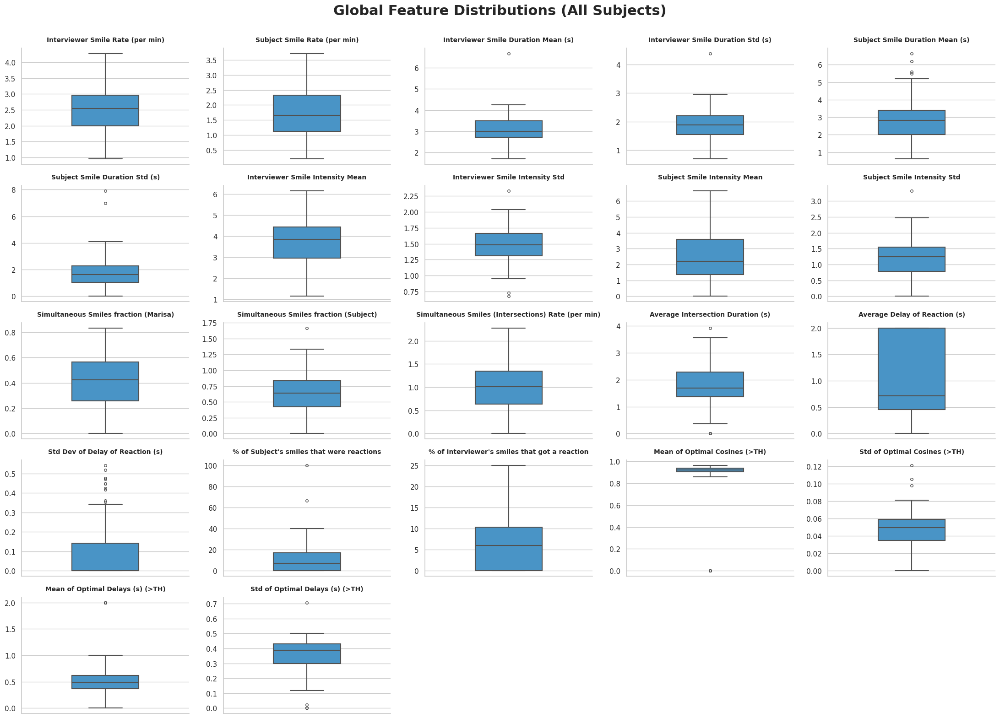

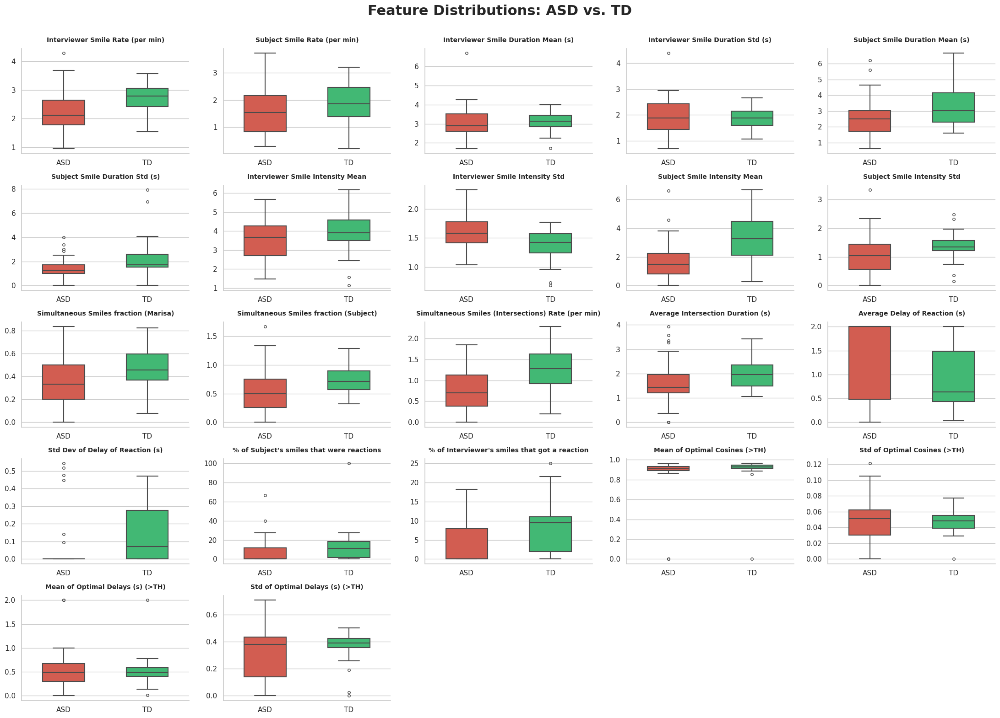

In [24]:
df = pd.read_csv(DATA_PATH)

# Explicitly define metadata so we only plot the behavioral features
metadata_cols = ['Subject Number', 'Label', 'Gender']
feature_cols = [col for col in df.columns if col not in metadata_cols]


# Create a readable label column for the grouped plots (Optional, but looks cleaner)
df['Diagnosis'] = df['Label'].map({1: 'ASD', 0: 'TD'})

print(f"Loaded {len(df)} subjects.")
print(f"Generating Boxplot Dashboards for {len(feature_cols)} features...")

# =============================================================================
# 2. Figure 1: Overall Boxplots (Ignoring Labels)
# =============================================================================
sns.set_theme(style="whitegrid", palette="pastel")

# Create a 4x5 grid (20 slots for 17 features)
fig1, axes1 = plt.subplots(5, 5, figsize=(22, 16))
fig1.suptitle('Global Feature Distributions (All Subjects)', fontsize=22, fontweight='bold', y=0.98)

# Flatten the axes array for easy iteration
axes1_flat = axes1.flatten()

for i, feature in enumerate(feature_cols):
    ax = axes1_flat[i]
    # Vertical boxplot for the overall distribution
    sns.boxplot(y=df[feature], ax=ax, color='#3498db', width=0.4, linewidth=1.5, fliersize=4)
    
    # Format subplot
    ax.set_title(feature, fontsize=10, fontweight='bold', pad=10)
    ax.set_ylabel('') # Hide y-label to keep the grid clean
    
# Hide the remaining unused subplots (slots 17, 18, 19)
for j in range(i + 1, len(axes1_flat)):
    fig1.delaxes(axes1_flat[j])

sns.despine(fig=fig1)
fig1.tight_layout()
fig1.subplots_adjust(top=0.92)


# =============================================================================
# 3. Figure 2: Grouped Boxplots (ADOS vs. Non-ADOS)
# =============================================================================
# Set a distinct color palette for the two classes
class_palette = {'ASD': '#e74c3c', 'TD': '#2ecc71'}

fig2, axes2 = plt.subplots(5, 5, figsize=(22, 16))
fig2.suptitle('Feature Distributions: ASD vs. TD', fontsize=22, fontweight='bold', y=0.98)

axes2_flat = axes2.flatten()

for i, feature in enumerate(feature_cols):
    ax = axes2_flat[i]
    
    # Grouped boxplot comparing the two classes
    sns.boxplot(
        data=df, 
        x='Diagnosis', 
        y=feature, 
        hue='Diagnosis',
        palette=class_palette, 
        ax=ax, 
        width=0.5, 
        linewidth=1.5, 
        fliersize=4,
        legend=False # Hide legend per-subplot to avoid clutter
    )
    
    # Format subplot
    ax.set_title(feature, fontsize=10, fontweight='bold', pad=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    
# Hide the remaining unused subplots
for j in range(i + 1, len(axes2_flat)):
    fig2.delaxes(axes2_flat[j])

sns.despine(fig=fig2)
fig2.tight_layout()
fig2.subplots_adjust(top=0.92)

# =============================================================================
# 4. Display the Dashboards
# =============================================================================
plt.show()

Plotting data points for: Average Delay of Reaction (s)...


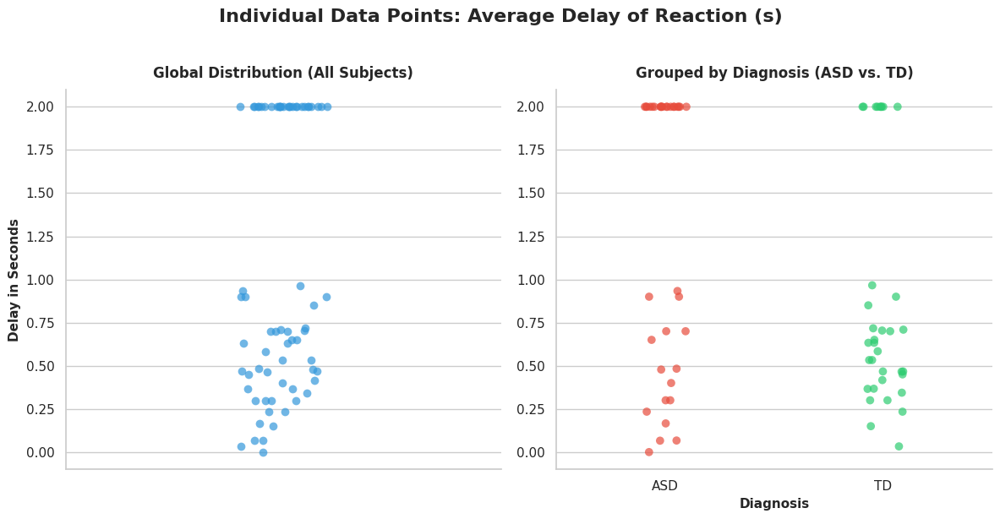

In [25]:
# Create a readable label column
df['Diagnosis'] = df['Label'].map({1: 'ASD', 0: 'TD'})


# Define the specific feature to plot
target_feature = 'Average Delay of Reaction (s)'


# Verify the column exists before plotting
if target_feature not in df.columns:
    print(f"Error: '{target_feature}' not found in the dataset. Check column names.")
else:
    print(f"Plotting data points for: {target_feature}...")
    
    sns.set_theme(style="whitegrid", palette="pastel")
    
    # Create a 1x2 figure layout
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle(f'Individual Data Points: {target_feature}', fontsize=16, fontweight='bold', y=1.02)
    
    # =============================================================================
    # 2. Left Subplot: Overall Points (Ignoring Labels)
    # =============================================================================
    sns.stripplot(
        y=df[target_feature], 
        ax=axes[0], 
        color='#3498db', 
        jitter=True,   # Adds horizontal noise so points don't perfectly overlap
        alpha=0.7,     # Makes points slightly transparent
        size=7         # Size of the dots
    )
    
    axes[0].set_title('Global Distribution (All Subjects)', fontsize=12, fontweight='bold', pad=10)
    axes[0].set_ylabel('Delay in Seconds', fontsize=11, fontweight='bold')
    
    # =============================================================================
    # 3. Right Subplot: Grouped Points (ASD vs. TD)
    # =============================================================================
    class_palette = {'ASD': '#e74c3c', 'TD': '#2ecc71'}
    
    sns.stripplot(
        data=df, 
        x='Diagnosis', 
        y=target_feature, 
        hue='Diagnosis',
        palette=class_palette, 
        ax=axes[1], 
        jitter=True,
        alpha=0.7,
        size=7,
        legend=False 
    )
    
    axes[1].set_title('Grouped by Diagnosis (ASD vs. TD)', fontsize=12, fontweight='bold', pad=10)
    axes[1].set_xlabel('Diagnosis', fontsize=11, fontweight='bold')
    axes[1].set_ylabel('') # Hide Y-label to keep it clean
    
    # =============================================================================
    # 4. Final Formatting & Display
    # =============================================================================
    sns.despine(fig=fig)
    plt.tight_layout()
    plt.show()

In [5]:
def plot_correlation_heatmap(X_df, title="Behavioral Feature Correlation Matrix"):
    """
    Generates a publication-ready correlation heatmap for the feature dataset.
    Masks the upper triangle, uses a diverging color palette, dynamically 
    scales figure and font sizes, and highlights the diagonal in solid black.
    """
    # 1. Abbreviate column names if they are too long
    short_cols = [abbreviate_feature_name(col) for col in X_df.columns]
    df_short = X_df.copy()
    df_short.columns = short_cols
    
    # 2. Compute the correlation matrix
    corr = df_short.corr(method='pearson')
    
    # 3. Generate overlay masks
    # Base mask: Hides upper triangle AND the diagonal (k=0)
    mask_base = np.triu(np.ones_like(corr, dtype=bool), k=0)
    
    # Diagonal mask: Hides EVERYTHING EXCEPT the diagonal
    mask_diag = np.ones_like(corr, dtype=bool)
    np.fill_diagonal(mask_diag, False)
    
    num_feats = len(corr.columns)
    
    # 4. Set up the matplotlib figure
    fig_width = max(12.0, num_feats * 0.55)
    fig_height = max(10.0, num_feats * 0.45)
    f, ax = plt.subplots(figsize=(fig_width, fig_height))
    
    # 5. Set academic theme
    sns.set_theme(style="white")
    plt.rcParams['font.family'] = 'sans-serif'
    
    # 6. Generate a custom diverging colormap (Deep Blue to Deep Red)
    cmap = sns.diverging_palette(230, 20, as_cmap=True)
    
    # --- FIX APPLIED HERE ---
    # 7. Dynamic Font Sizing (More aggressively shrunk for large feature sets)
    annot_size = max(4, 10 - int(num_feats / 4)) # Will scale down to size 4-5 for 25 features
    axis_label_size = max(8, 12 - int(num_feats / 10))
    show_annot = True if num_feats <= 35 else False 
    
    # 8. Draw the base heatmap (Off-Diagonal Cells)
    sns.heatmap(corr, mask=mask_base, cmap=cmap, vmax=1.0, vmin=-1.0, center=0,
                square=True, linewidths=.5, cbar_kws={"shrink": .7, "label": "Pearson Correlation"}, 
                annot=show_annot, fmt=".2f", annot_kws={"size": annot_size, "weight": "bold"}, ax=ax)
                
    # 9. Draw the diagonal heatmap (Solid Black)
    black_cmap = ListedColormap(['black'])
    sns.heatmap(corr, mask=mask_diag, cmap=black_cmap, cbar=False, 
                square=True, linewidths=.5, ax=ax,
                annot=show_annot, fmt=".2f", 
                annot_kws={"size": annot_size, "weight": "bold", "color": "white"})
    
    # 10. Formatting & Alignment
    ax.set_title(title, fontsize=16, fontweight='bold', pad=20)
    
    plt.xticks(rotation=90, ha='center', fontsize=axis_label_size, fontweight='bold')
    plt.yticks(rotation=0, va='center', fontsize=axis_label_size, fontweight='bold')
    
    # Remove empty background coloring
    ax.set_facecolor('white')
    
    plt.tight_layout()
    plt.show()

In [26]:
    

def prune_highly_correlated_features(X_df, y, threshold=0.80, output_file="retained_features.txt"):
    """
    Scans the feature matrix for highly collinear feature pairs.
    If two features have a Pearson correlation >= threshold, it compares
    their absolute correlation with the target 'y'. 
    The feature with the weaker predictive relationship to 'y' is dropped.
    Generates academic subplots for dropped pairs and saves retained features to a text file.
    """
    print(f"\n{'='*60}")
    print(f"PRUNING HIGHLY CORRELATED FEATURES (Threshold: {threshold})")
    print(f"{'='*60}")
    
    # Compute the absolute correlation matrix for features
    corr_matrix = X_df.corr(method='pearson').abs()
    
    to_drop = set()
    features = corr_matrix.columns
    
    collinear_pairs_info = [] # Store information for plotting
    
    # Iterate through the upper triangle of the correlation matrix
    for i in range(len(features)):
        for j in range(i + 1, len(features)):
            feat_A = features[i]
            feat_B = features[j]
            
            # Skip if one of them is already marked for dropping
            if feat_A in to_drop or feat_B in to_drop:
                continue
                
            # If the features are highly correlated
            if corr_matrix.loc[feat_A, feat_B] >= threshold:
                
                # Check their individual absolute correlations with the target 'y'
                corr_A_target = abs(X_df[feat_A].corr(y))
                corr_B_target = abs(X_df[feat_B].corr(y))
                
                collinearity_score = corr_matrix.loc[feat_A, feat_B]
                
                # Drop the one with the weaker target correlation
                if corr_A_target >= corr_B_target:
                    dropped_feat = feat_B
                    kept_feat = feat_A
                    t_corr_dropped = corr_B_target
                    t_corr_kept = corr_A_target
                else:
                    dropped_feat = feat_A
                    kept_feat = feat_B
                    t_corr_dropped = corr_A_target
                    t_corr_kept = corr_B_target
                
                to_drop.add(dropped_feat)
                
                print(f"Collinear Pair: '{feat_A}' & '{feat_B}' (r = {collinearity_score:.3f})")
                print(f" -> Dropping '{dropped_feat}' (Target r = {t_corr_dropped:.3f} vs {t_corr_kept:.3f})")
                
                # Save data for subplot generation
                collinear_pairs_info.append({
                    'feat_A': feat_A,
                    'feat_B': feat_B,
                    'r': collinearity_score,
                    'dropped': dropped_feat
                })
    
    # Create a new pruned dataframe
    X_pruned = X_df.drop(columns=list(to_drop))
    
    print("-" * 60)
    print(f"Original Features: {len(X_df.columns)}")
    print(f"Dropped Features:  {len(to_drop)}")
    print(f"Remaining Features: {len(X_pruned.columns)}")
    print(f"{'='*60}\n")
    
    # --- File I/O: Save retained features to a txt file ---
    with open(output_file, "w") as f:
        f.write('[')
        for feature in X_pruned.columns:
            f.write(f"\"{feature}\",\n")
        f.write(']')
    print(f"[*] Successfully saved {len(X_pruned.columns)} retained features to '{output_file}'.\n")
    
    # --- Visualization: Subplots for Highly Correlated Pairs ---
    if collinear_pairs_info:
        sns.set_theme(style="whitegrid")
        plt.rcParams['font.family'] = 'sans-serif'
        
        num_plots = len(collinear_pairs_info)
        cols = min(3, num_plots)
        rows = math.ceil(num_plots / cols)
        
        fig, axes = plt.subplots(rows, cols, figsize=(5.5 * cols, 5 * rows))
        fig.suptitle(f'Collinear Feature Pairs Analysis (Pearson $|r| \geq {threshold}$)', 
                     fontsize=18, fontweight='bold', y=1.02)
        
        # Flatten axes array for easy iteration (handles single plot case gracefully)
        if num_plots > 1:
            axes_flat = axes.flatten()
        else:
            axes_flat = [axes]
            
        for idx, info in enumerate(collinear_pairs_info):
            ax = axes_flat[idx]
            f_A = info['feat_A']
            f_B = info['feat_B']
            
            # Plot the scatter distribution colored by Class Label
            sns.scatterplot(x=X_df[f_A], y=X_df[f_B], hue=y, ax=ax, 
                            palette='Set1', edgecolor='k', alpha=0.8, s=60)
            
            # Overlay a subtle dashed regression line to show the collinear trend
            sns.regplot(x=X_df[f_A], y=X_df[f_B], ax=ax, scatter=False, 
                        color='black', line_kws={'linestyle':'--', 'alpha':0.5})
            
            # Subplot Formatting
            title_str = f"r = {info['r']:.3f} | Dropped: {abbreviate_feature_name(info['dropped'])}"
            ax.set_title(title_str, fontsize=11, fontweight='bold', color='darkred')
            
            # Wrap axes labels so they don't collide
            ax.set_xlabel(textwrap.fill(f_A, width=35), fontsize=10, fontweight='bold')
            ax.set_ylabel(textwrap.fill(f_B, width=35), fontsize=10, fontweight='bold')
            
            # Clean up legends (only show legend on the first plot to save space)
            if idx == 0:
                ax.legend(title='Label', loc='best', fontsize=9)
            elif ax.get_legend() is not None:
                ax.get_legend().remove()
                
        # Remove any empty subplots in the grid
        for j in range(num_plots, len(axes_flat)):
            fig.delaxes(axes_flat[j])
            
        sns.despine()
        plt.tight_layout()
        plt.show()
        
    return X_pruned

<>:92: SyntaxWarning: invalid escape sequence '\g'
<>:92: SyntaxWarning: invalid escape sequence '\g'
/tmp/ipykernel_3569/907623558.py:92: SyntaxWarning: invalid escape sequence '\g'
  fig.suptitle(f'Collinear Feature Pairs Analysis (Pearson $|r| \geq {threshold}$)',


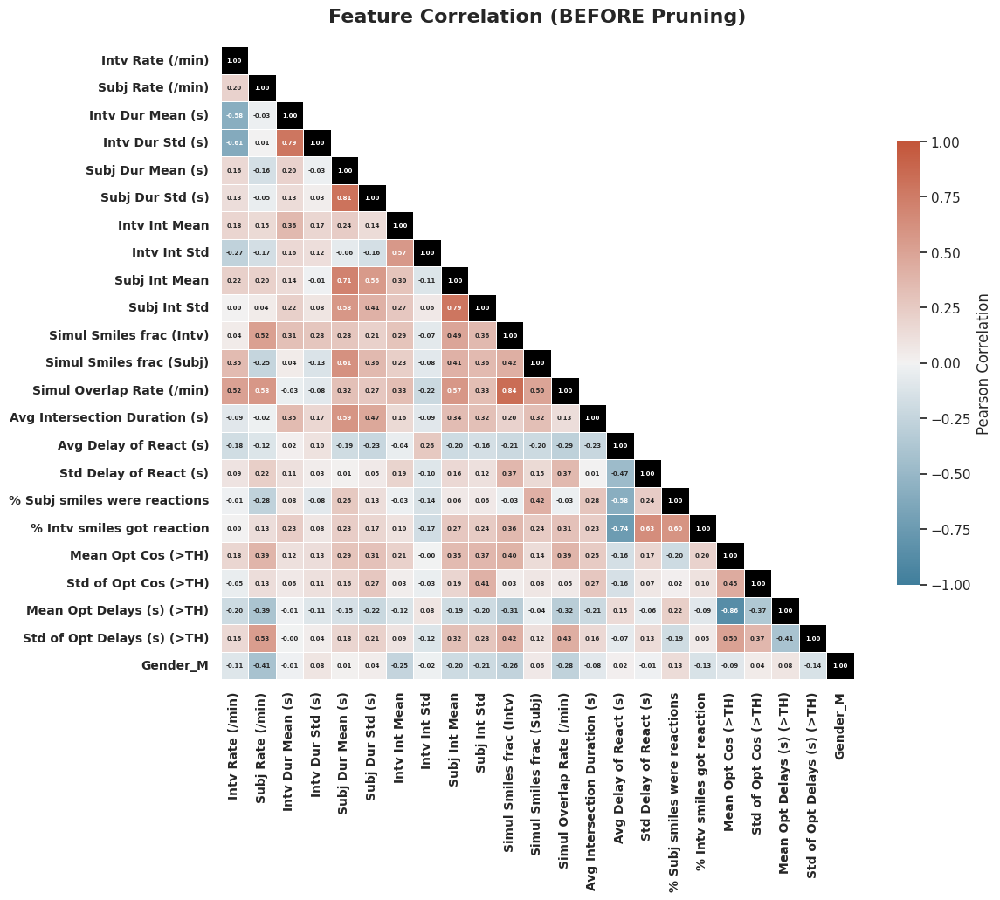


PRUNING HIGHLY CORRELATED FEATURES (Threshold: 0.8)
Collinear Pair: 'Subject Smile Duration Mean (s)' & 'Subject Smile Duration Std (s)' (r = 0.810)
 -> Dropping 'Subject Smile Duration Std (s)' (Target r = 0.286 vs 0.309)
Collinear Pair: 'Simultaneous Smiles fraction (Marisa)' & 'Simultaneous Smiles (Intersections) Rate (per min)' (r = 0.845)
 -> Dropping 'Simultaneous Smiles fraction (Marisa)' (Target r = 0.297 vs 0.463)
Collinear Pair: 'Mean of Optimal Cosines (>TH)' & 'Mean of Optimal Delays (s) (>TH)' (r = 0.860)
 -> Dropping 'Mean of Optimal Delays (s) (>TH)' (Target r = 0.092 vs 0.146)
------------------------------------------------------------
Original Features: 23
Dropped Features:  3
Remaining Features: 20

[*] Successfully saved 20 retained features to 'retained_features.txt'.



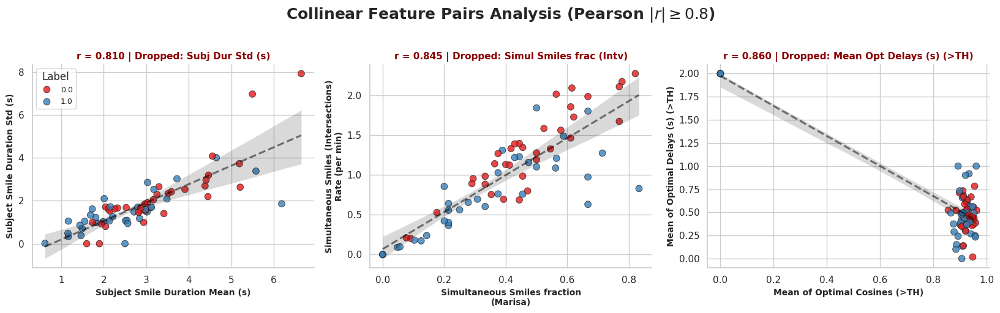

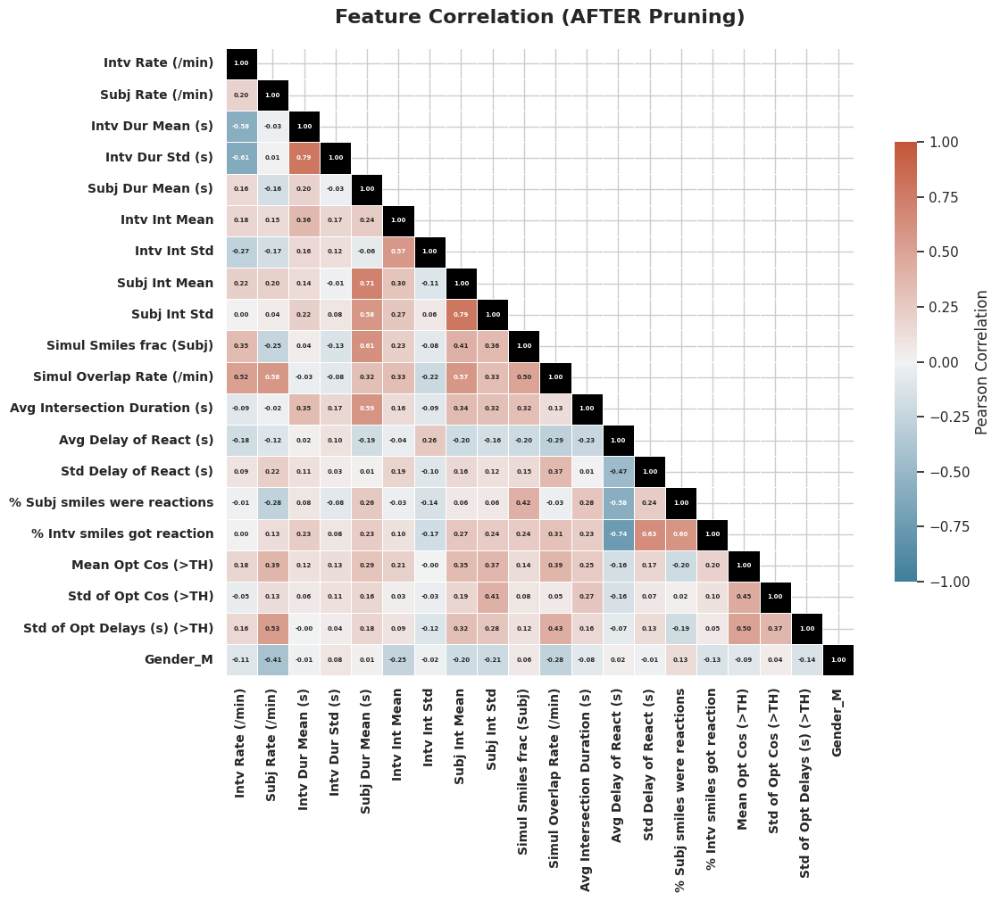

In [27]:
# =============================================================================
# Main Execution 
# =============================================================================
if __name__ == "__main__":
    # --- A. Load and Prepare Data ---
    file_path = "/home/amir/Ados_lab/lab/features_matrix.csv"
    try:
        data = pd.read_csv(file_path)
    except FileNotFoundError:
        print(f"Error: Could not find '{file_path}'. Please ensure it is in the same directory.")
        exit()

    # Isolate behavioral features from metadata
    # meta_cols = ['Subject Number', 'Label', 'Gender']
    meta_cols = ['Subject Number', 'Label']  
    data = pd.get_dummies(data, columns=['Gender'], drop_first=True).astype(float)
    available_meta = [c for c in meta_cols if c in data.columns]
    
    X_df = data.drop(columns=available_meta)
    y = data['Label']  # Keep 'y' as a pandas Series for correlation calculations
    
    # --- B. Plot BEFORE Pruning ---
    plot_correlation_heatmap(X_df, title="Feature Correlation (BEFORE Pruning)")
    
    # --- C. Execute Smart Pruning (Threshold = 0.80) ---
    X_pruned = prune_highly_correlated_features(X_df, y, threshold=0.80)
    
    # --- D. Plot AFTER Pruning ---
    # The resulting matrix should have no dark red/blue squares off the diagonal > 0.80
    plot_correlation_heatmap(X_pruned, title="Feature Correlation (AFTER Pruning)")
    
    # --- E. Continue to Modeling using X_pruned ---
    # Convert 'y' to values if your model requires numpy arrays
    y_values = y.values
    feature_names = X_pruned.columns.tolist()
    num_features = len(feature_names)
    
    # (Proceed with your LOOCV or K-Fold script using X_pruned...)

Loaded 70 subjects.
Generating Boxplot Dashboards for 22 features...


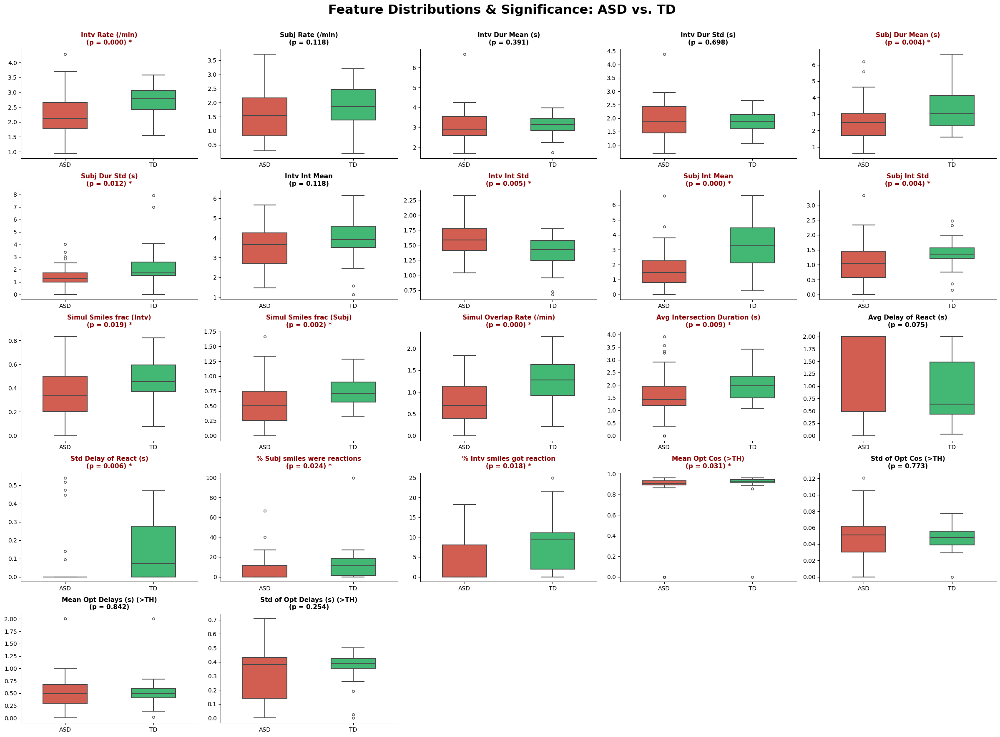

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# =============================================================================
# 1. Setup & Data Loading
# =============================================================================
df = pd.read_csv(DATA_PATH)

# Explicitly define metadata so we only plot the behavioral features
metadata_cols = ['Subject Number', 'Label', 'Gender']
feature_cols = [col for col in df.columns if col not in metadata_cols]

# Create a readable label column for the grouped plots 
df['Diagnosis'] = df['Label'].map({1: 'ASD', 0: 'TD'})

print(f"Loaded {len(df)} subjects.")
print(f"Generating Boxplot Dashboards for {len(feature_cols)} features...")

# =============================================================================
# 2. Figure 2: Grouped Boxplots (ASD vs. TD) with P-Values
# =============================================================================
# Set a distinct color palette for the two classes
class_palette = {'ASD': '#e74c3c', 'TD': '#2ecc71'}

fig2, axes2 = plt.subplots(5, 5, figsize=(24, 18)) 
fig2.suptitle('Feature Distributions & Significance: ASD vs. TD', fontsize=22, fontweight='bold', y=0.98)

axes2_flat = axes2.flatten()

for i, feature in enumerate(feature_cols):
    ax = axes2_flat[i]
    
    # --- A. Statistical Testing (Mann-Whitney U) ---
    asd_data = df[df['Diagnosis'] == 'ASD'][feature].dropna()
    td_data = df[df['Diagnosis'] == 'TD'][feature].dropna()
    
    # Calculate p-value (ignoring features with no variance or completely empty)
    if len(asd_data) > 0 and len(td_data) > 0:
        _, p_value = stats.mannwhitneyu(asd_data, td_data, alternative='two-sided')
    else:
        p_value = 1.0
        
    # --- B. Plotting ---
    sns.boxplot(
        data=df, 
        x='Diagnosis', 
        y=feature, 
        hue='Diagnosis',
        palette=class_palette, 
        ax=ax, 
        width=0.5, 
        linewidth=1.5, 
        fliersize=4,
        legend=False 
    )
    
    # --- C. Dynamic Title Formatting ---
    # Shorten the feature name so it fits in the grid
    short_name = abbreviate_feature_name(feature)
    
    # Highlight significant features in dark red with an asterisk
    if p_value < 0.05:
        title_text = f"{short_name}\n(p = {p_value:.3f}) *"
        title_color = 'darkred'
    else:
        title_text = f"{short_name}\n(p = {p_value:.3f})"
        title_color = 'black'
        
    ax.set_title(title_text, fontsize=11, fontweight='bold', color=title_color, pad=8)
    ax.set_xlabel('')
    ax.set_ylabel('')
    
# Hide the remaining unused subplots
for j in range(i + 1, len(axes2_flat)):
    fig2.delaxes(axes2_flat[j])

sns.despine(fig=fig2)
fig2.tight_layout()
fig2.subplots_adjust(top=0.92)

plt.show()